# Sleep Apnea Detection — CNN + BiGRU

Split from two monolithic cells into **28 documented cells**.

**Run cells 1–22 in order.** Every cell defines things the later ones need,
so skipping one gives a `NameError`. Cell 22 is where training actually
starts; everything before it is definitions and costs no time.

| Cells | What |
|---|---|
| 1–3 | Setup: imports, run mode, all configuration |
| 4–8 | Preprocessing: signal cleaning, features, labels, cache |
| 9–11 | Data: splits, Dataset class, normalization statistics |
| 12–13 | Model: architecture, loss functions |
| 14–15 | Inference: decoding, metrics |
| 16 | Training loop |
| 17–19 | Reporting: helpers, 28 figures, per-seed analysis |
| 20–22 | Entry point — **cell 22 runs it** |
| 23–28 | Loss ablation (optional, run after 22) |

### Before you start

Check the paths in **cell 3** match your machine:

```python
PROJECT_DIR      = "/home/nishant/apneastudyproject"
DEFAULT_DATA_DIR = PROJECT_DIR + "/dataset_output (1)"
OUTPUT_DIR       = PROJECT_DIR + "/output"
```

The first run builds the cache from your raw `.npy` files — a few minutes.
Later runs reuse it and start at Stage 2.

## Cell 1 — Documentation

The full change log: every design decision tagged `[C1]`–`[C28]`, with the
measurement that motivated it. No executable code, but this is the record of
*why* the pipeline is shaped the way it is — worth reading once.

The tags that matter most:

- **`[C21]`** structured decoding is **off**. With it on, severity κ_w went
  0.7368 → **0.0000** and AHI MAE 1.97 → 4.02, buying only +0.009 window F1.
  It was merging adjacent events into long blocks, which halves the event
  count — and the AHI *is* a count.
- **`[C22]`** the split is ranked by apnea **ratio** (higher F1) or **AHI**
  (spans all four severity bands). They disagree: a patient with few long
  events has a high ratio and a low AHI.
- **`[C26]`/`[C27]`** local + notebook adaptation: no `kagglehub`, no
  `argparse` (Jupyter's `sys.argv` holds kernel flags that argparse rejects).

In [1]:
r"""
=============================================================================
 SLEEP APNEA / DISORDERED-BREATHING DETECTION  —  NOTEBOOK BUILD
 Decoder disabled [C21] · SELECTABLE split stratification [C22]

=============================================================================
 HOW TO USE — paste this whole thing into ONE notebook cell and run it
=============================================================================

 Paths are already set for your machine:

     data   /home/nishant/apneastudyproject/dataset_output (1)
     output /home/nishant/apneastudyproject/output
     cache  /home/nishant/apneastudyproject/output/cache

 The cell runs main() automatically at the bottom and leaves the result in a
 variable called `results`. Figures display inline AND are saved to the
 output folder.

 TO CHANGE THE EXPERIMENT, edit the config block and re-run the cell:

     SEEDS = [42, 43, 44]     # multi-seed ensemble + an error bar
     N_FOLDS = 5              # grouped patient cross-validation
     SPLIT_RANK_BY = "ahi"    # or "ratio" (higher F1, fewer severity bands)
     LOSS_TYPE = "bce"        # bce / weighted_bce / focal / weighted_focal
     MAX_PATIENTS = 12        # quick test on an evenly spaced subset

 FIRST RUN takes longer: the cache is built once from the raw .npy files
 (a few minutes). Every run after that starts at Stage 2.

 IF THE DATA PATH IS WRONG, the cell prints every location it searched
 rather than a bare traceback. Fix DEFAULT_DATA_DIR and re-run.

 NOTE ON THE FOLDER NAME: 'dataset_output (1)' contains a space and
 parentheses. That is fine here because the path is a Python string, never
 a shell command — but if you ever pass it to a shell, quote it.

=============================================================================
 CHANGE LOG — every edit is tagged [C#] at its site in the code
=============================================================================

 TIER 1 — correctness. These are not tuning; v3 was measuring the wrong
 thing or throwing away signal.

 [C1] EPOCH POOLING IS NOW mean AND max.
      v3: `h.mean(dim=-1)`. The source labels are ANY-OVERLAP labels, so an
      epoch is positive if an event touches it at all — which makes the
      label effectively a MAX over the epoch. A 10 s apnea inside a 30 s
      epoch is attenuated ~3x by averaging, and the model has to recover the
      max from a mean it was never given. Now both are concatenated. Mean is
      kept because whole-epoch context is still informative.
      Cost: GRU input doubles (2*W -> 4*W). Highest value-per-line change
      in the file.

 [C2] THE PRESENCE MASK NO LONGER GOES THROUGH THE CONVOLUTIONS.
      v3 concatenated the mask as extra input channels, doubling encoder
      input width with signals that are CONSTANT along time. Two costs:
      (a) thousands of identical copies of a flag are convolved, extracting
      nothing that one copy does not; (b) it hands the encoder a patient
      fingerprint — which is a leakage path under a patient-level split.
      The mask now joins at the classifier head. Encoder input drops from
      10->5 and 6->3 channels, so this is also ~10% faster.

 [C3] EPOCHS 20 -> 14.
      v3's OneCycleLR was built for a 20-epoch budget: it peaks at ~epoch 5
      and anneals to near-zero at 20. But the v3 log shows val_loss
      bottoming at epochs 8-14 and val_F1 flat at ~0.728 from epoch 10, so
      early stopping kept a checkpoint taken MID-ANNEAL at high LR — never
      the converged low-LR weights the schedule exists to produce. Matching
      the budget to where the model actually converges gives you the
      annealed weights AND saves ~30% of runtime.

 [C4] EVENT AND AHI METRICS NOW USE RAW PROBABILITIES.
      v3 computed them from SMOOTHED probabilities. Smoothing merges
      adjacent predicted blocks, which lowers the predicted event COUNT —
      and the AHI proxy is exactly a count of events per hour. The v3 MAE
      of 1.58/h was systematically deflated. Smoothed WINDOW metrics are
      still reported alongside for comparison.

 [C5] SN53 EXCLUDED. 900 epochs, ZERO scored events. It cannot exceed
      F1 0.000 by construction and it alone dragged the v3 median
      per-patient F1 from ~0.66 to 0.622.

 [C6] MULTI-SEED + OPTIONAL GROUPED CV.
      SEEDS = [42, 43, 44] by default: probabilities are ensembled across
      seeds before decoding, and the per-seed spread is the honest error
      bar. Set N_FOLDS = 5 for grouped patient cross-validation, which
      makes every patient a test patient instead of 15 of them.

 TIER 2 — inside the existing framework. All toggleable so you can ablate.

 [C7] ENGINEERED FEATURES INJECTED AT THE GRU (USE_FEATURES).
      The labels were generated by a rule: airflow amplitude drops >=30%
      below baseline for >=10 s with >=3% desaturation. That is a division
      and a comparison. A CNN has to learn division from 60 patients; here
      33 physiologically grounded features are computed in closed form at
      cache time and concatenated to the GRU input. Near-zero runtime cost.

 [C8] AUXILIARY BURDEN HEAD (USE_BURDEN_HEAD).
      A second head regresses each chunk's apnea fraction. It supplies the
      per-recording prevalence estimate that [C9] needs, and it regularizes
      — the per-epoch head must now also be globally coherent.

 [C9] PREVALENCE-ADAPTIVE OPERATING POINT + STRUCTURED DECODING.
      v3 per-patient F1 correlates strongly with prevalence while
      per-patient AUC does not (SN6: AUC 0.942 / F1 0.448; SN63: AUC 0.734 /
      F1 0.257). The ranking is fine on mild patients; ONE global threshold
      is what fails them. v4 shifts each recording's threshold toward its
      own predicted prevalence quantile, blended toward the global threshold
      by a factor tuned on VALIDATION — so blend=0 costs nothing if the
      burden estimate is not good enough. Then gaps up to MAX_GAP are closed
      and runs shorter than MIN_LEN dropped, to repair event fragmentation
      (v3: loose event F1 0.657 vs strict 0.5624 — that gap IS fragmentation).

      CONSTRAINED. Maximizing event F1 alone is actively harmful: aggressive
      gap closing merges predictions into a few long blocks that overlap
      almost every true event, so event F1 rises while window F1, severity
      and AHI all collapse. The search therefore maximizes event F1 SUBJECT
      TO window F1 staying within WINDOW_TOL of the undecoded baseline.

 [C10] BOUNDARY HEAD (USE_BOUNDARY_HEAD / USE_BOUNDARY_SPLIT).
      v3 asked "is this epoch apneic" but never "does an event START here".
      Two extra logits per epoch predict onset and offset. Trained always as
      a regularizer; optionally used at inference to split merged blocks,
      under the same window-F1 constraint as [C9].

 [C11] LAG FUSION IS OFF BY DEFAULT — this is an ABLATION, not a deletion.
      LagFusion learns a GLOBAL offset distribution and applies it before a
      BiGRU that already spans +-10 minutes bidirectionally. The GRU can
      learn any fixed offset itself. Set USE_LAG_FUSION = True to compare;
      the learned offsets are still saved and plotted when enabled.

 [C12] TIME MASKING augmentation. With 60 training patients and a plateau by
      epoch 10, regularization is worth more than capacity.

 [C13] EFFICIENCY: RESP_FS hook (16 Hz is still 3x Nyquist for <5 Hz
      respiratory content), optional torch.compile, vectorized longest-run.

 [C15] LAG FUSION IS NOW INPUT-CONDITIONED (LAG_MODE = "conditioned").
      v3's LagFusion learned ONE global offset distribution for the whole
      dataset. That is strictly weaker than the BiGRU sitting downstream,
      which can already learn any fixed offset — which is why the "global"
      mode is an ablation rather than a contribution.

      The conditioned mode predicts the offset logits PER TIMESTEP from the
      respiratory embedding, so a patient with slow circulatory transit gets
      a longer airflow->desaturation lag than one with fast transit, and a
      deep obstructive event gets a different lag from a brief hypopnea.
      That is something the GRU cannot trivially replicate, because the GRU
      mixes the two streams AFTER they have already been paired at a fixed
      alignment. The global logits are kept as a learned PRIOR that the
      conditioned term shifts, so the model degrades gracefully to the v3
      behaviour if the conditioning turns out to be noise.

          LAG_MODE = "off"          v4 default — ablation, GRU does the work
          LAG_MODE = "global"       exactly v3's LagFusion
          LAG_MODE = "conditioned"  per-timestep offsets from the resp stream

 [C16] OPTIONAL EXTRA STEM STRIDE (RESP_STEM_STRIDE / SLOW_STEM_STRIDE).
      The encoder runs at samples_per_epoch/stride positions. Doubling the
      resp stem stride to 4 halves the cost of every dilated block AND
      doubles the receptive field in seconds for free, because the dilations
      then span twice as much wall-clock time. At RESP_FS=32 and stride 4 the
      encoder still sees 8 positions/second, which is ample for content below
      5 Hz. Left at 2 by default so the headline run stays comparable to v3;
      flip it as a paired efficiency ablation.

 [C26] LOCAL-RUN ADAPTATION. Four things differ from the Kaggle build:

      (a) NO kagglehub. The data directory is resolved from --data-dir, then
          $APNEA_DATA, then DEFAULT_DATA_DIR, then ./data, then a bounded
          search around the script. kagglehub is still tried LAST so the same
          file runs unchanged in a Kaggle notebook.

      (b) RELATIVE PATHS. Output and cache default to ./output and ./cache
          beside the script, not /kaggle/working. Both are overridable.

      (c) WINDOWS-SAFE DataLoader. num_workers defaults to 0 on Windows.
          Windows lacks fork(), so each worker re-imports the module; a
          module with top-level side effects (this one builds directories on
          import) can hang or spawn recursively. 0 workers is slightly slower
          and always correct. Pass --workers N to override on Linux/macOS.

      (d) argparse + a __main__ guard. Required for multiprocessing on
          Windows regardless of (c), and it makes every knob settable without
          editing the file.

 [C21] STRUCTURED DECODING IS OFF BY DEFAULT — the single most important
      change in this file, and it is a REMOVAL.

      MEASURED on the v6 run (same seed, same split, decoder on vs off):

          metric              undecoded    decoded    verdict
          window F1              0.7355     0.7448    +0.009
          event F1 (>=50%)       0.4704     0.5472    +0.077
          AHI r                  0.8516     0.8213    -0.030
          AHI MAE (events/h)     1.9695     4.0203    +2.05  WORSE
          severity accuracy      0.8667     0.4000    -0.467  WORSE
          severity kappa_w       0.7368     0.0000    -0.737  DESTROYED
          predicted events          496        238    vs 719 true

      Weighted kappa of EXACTLY ZERO means the predicted severity carries no
      agreement structure with the truth at all. For +0.009 window F1 the
      decoder cost the entire clinical endpoint.

      WHY IT HAPPENS, from this file's own diagnostics:

          true events      median 2.0 epochs, mean  5.07
          predicted events median 4.0 epochs, mean 12.27   <- 2.4x TOO LONG
          onset error  -2 epochs (fires 60 s EARLY)
          offset error +2 epochs (releases 60 s LATE)

      Each predicted event is ~4 epochs (2 minutes) too wide. The decoder is
      not repairing fragmentation, it is MERGING neighbouring events into
      blocks. Merging halves the count, and the AHI *is* a count.

      The window-F1 guard in tune_decoding held perfectly (0.7355 -> 0.7448).
      It protects per-epoch labels. It does not protect the event COUNT.
      So [C21] adds AHI MAE to the constraint as well, and sets the grids to
      the identity so the stage is a no-op unless you deliberately re-enable
      it:

          GAP_GRID = [0]; LEN_GRID = [1]; ONSET_SPLIT_GRID = [None]

      To reinstate it as an ablation, restore the grids AND set
      AHI_TOL = None to disable the new constraint.

 [C22] SPLIT STRATIFICATION IS NOW A FLAG: SPLIT_RANK_BY.

      "ratio"  rank patients by apnea RATIO (fraction of epochs positive).
               This is the ORIGINAL scheme. It gives the HIGHER window F1
               (0.7448 measured, vs 0.6614 on the AHI split) and is the
               default here because you asked for maximum F1.

      "ahi"    rank by the AHI proxy (events per hour), the quantity
               severity is actually defined on.

      THE TWO ARE NOT INTERCHANGEABLE, AND YOU SHOULD KNOW WHY BEFORE YOU
      REPORT EITHER.

      Ratio and AHI disagree badly, because one counts EPOCHS and the other
      counts EVENTS:

          SN26   ratio 0.732   AHI  7.45    few, very long events
          SN68   ratio 0.211   AHI 10.60    many short ones

      Consequence of ranking on ratio: every test split produced this way
      contained 6 normal and 9 mild patients and ZERO moderate, ZERO severe.
      Measured effect of switching to AHI ranking, same model, same seed:

          window F1        0.7448 -> 0.6614     (-0.083)
          PR-AUC           0.8480 -> 0.7062     (-0.142)
          ROC-AUC          0.9271 -> 0.8900     (-0.037)
          severity bands present in test:  2 of 4  ->  4 of 4

      PR-AUC is THRESHOLD-FREE. A 0.142 drop in it cannot be caused by a
      threshold or a loss; only by a harder test set. So the ratio split's
      higher F1 is not a better model — it is an easier test set, one that
      omits the moderate and severe patients entirely.

      HOW TO REPORT THIS HONESTLY. Run BOTH (it is one flag and one rerun)
      and put both rows in the paper:

          stratification   window F1   PR-AUC   severity bands in test
          apnea ratio        0.745      0.848        2 of 4
          AHI (events/h)     0.661      0.706        4 of 4

      Then state: "Stratifying the patient-level split on apnea ratio rather
      than AHI inflates window F1 by 0.083 and PR-AUC by 0.142, because the
      resulting test set contains no moderate or severe recordings. We report
      the AHI-stratified result as primary." That is a methodological finding
      a reviewer will credit. Reporting ONLY the ratio number, without saying
      the test set spanned two of four severity classes, is the version that
      gets caught.

      This script prints a loud warning whenever a severity band is missing
      from the test split, so the caveat cannot be forgotten by accident.

 [C22-OLD] The original rationale for AHI ranking, retained for reference:
      v6 ranked patients by apnea RATIO (fraction of epochs positive). That
      is not AHI (events per hour), and the two disagree badly:

          SN26  ratio 0.732  AHI  7.45   few, very long events
          SN68  ratio 0.211  AHI 10.60   many short ones

      Consequence in every run so far: the test split contained 6 normal and
      9 mild patients and ZERO moderate, ZERO severe. A four-class severity
      metric computed over two present classes measures almost nothing —
      which is why "severity accuracy 0.8667" still needs the caveat.

      Ranking on the AHI proxy instead spreads the real severity range across
      train/val/test. Cheap, and it makes the severity number mean something.

 [C23] AHI-CONSTRAINED DECODER TUNING. tune_decoding now rejects any config
      whose validation AHI MAE exceeds the undecoded baseline by more than
      AHI_TOL (relative). Belt and braces with [C21]: even if you re-enable
      the grids, the search can no longer trade the clinical endpoint for
      event F1.

 [C19] CONTEXT DOUBLED: 10 MINUTES -> 20 MINUTES.
      CHUNK_EPOCHS 20 -> 40, so one forward pass now spans 40 x 30 s =
      20 minutes and the BiGRU sees that whole span in both directions.

      THE ARGUMENT FOR IT. Apnea is not an isolated event, it is a PERIODIC
      process. Obstructive events recur on a 30-90 s cycle; Cheyne-Stokes
      respiration has a 45-90 s cycle; both produce a characteristic
      crescendo-decrescendo envelope that only becomes visible over several
      cycles. Ten minutes contains roughly 7-20 cycles; twenty minutes
      contains 13-40. The extra context should help most where a single
      event is ambiguous but the RHYTHM is not — which is exactly the mild
      patients where this model is weakest.

      MEASURED RESULT — a documented NEGATIVE. Same seed, same split:

          v5 (10 min)   best val F1 0.7582, train-val gap 0.0235
          v6 (20 min)   best val F1 0.7537, train-val gap 0.1028

      Val F1 moved -0.0045, well inside the +-0.0097 seed noise floor, so
      there is NO measurable benefit. But the generalization gap is 4.4x
      larger and val loss diverges 7.4x harder: train loss went LOWER while
      val loss went HIGHER. Doubling the context doubled the effective
      capacity per prediction, and with 59 training patients the model spent
      it on memorizing. Reported as an ablation row, not as an improvement.

      THE ARGUMENT AGAINST IT, stated honestly. A GRU's practical memory is
      shorter than its nominal span, so the marginal epochs at the far end
      of a 20-minute chunk may contribute little. The encoder's receptive
      field is unchanged at 31.6 s — this change buys SEQUENCE context, not
      SIGNAL context. And it costs 2x the compute per chunk. Treat it as a
      hypothesis to test against the v5 numbers, not as a known improvement.

      KNOCK-ON CHANGES:
        EVAL_STRIDE   20 -> 40   (non-overlapping tiling must match)
        TRAIN_STRIDE  10 -> 10   (UNCHANGED, deliberately — see below)
        TIME_MASK span now covers 4 epochs instead of 2 (10% of the chunk)
        time-shift jitter now +-20 epochs instead of +-10

      WHY TRAIN_STRIDE STAYS AT 10. The obvious move is to scale it with the
      chunk (10 -> 20, keeping 50% overlap). Do NOT: it halves the number of
      chunks, and therefore halves the number of OPTIMIZER STEPS per epoch.
      With EPOCHS fixed at 14 the model would get half the gradient updates
      it used to. Holding the stride at 10 gives 75% overlap, preserves the
      step count, and keeps this a controlled comparison against v5 —
      the only thing that changed is how much context each prediction sees.
      Cost: ~2x runtime per epoch. Set it to 20 if you need the time back
      and are willing to raise EPOCHS to compensate.

 [C20] SINGLE SEED — 42.
      v5 trained SEEDS = [42, 43, 44] and ensembled. Seed 42 was the best of
      the three on VALIDATION (0.7582, vs 0.7563 and 0.7406), so it is the
      legitimate single-seed choice: it was selected on validation, never on
      test.

      WHAT YOU GIVE UP, stated plainly:

        1. The ensembling gain. On the v5 run, ensembling moved validation
           AUC from 0.9232 (mean single) to 0.9300. Expect the headline to
           drop by roughly that much.

        2. The error bar. v5 reported 0.7517 +- 0.0097 across seeds. With one
           seed there is NO error bar, and every number below is a point
           estimate. The +-0.0097 from the v5 run is still the best available
           estimate of the noise floor, and it is printed as a reminder —
           but it was measured under 10-minute context, so treat it as
           indicative rather than exact.

        3. Robustness to a bad draw. One seed can land badly. Seed 44
           early-stopped at epoch 9 with val F1 0.7406, well below the other
           two. Nothing here would catch that if 44 had been the only run.

      WHEN SINGLE SEED IS THE RIGHT CALL: rapid iteration and ablations,
      where you only need to know whether a change moves the needle by more
      than ~0.01. For any number that goes in a paper, restore
      SEEDS = [42, 43, 44].

      The per-seed reporting machinery [C18] still runs and degrades
      gracefully: the seed spread becomes a single row, standard deviations
      are reported as n/a rather than NaN, and the ensembling-gain lines are
      suppressed rather than printed as zero.

 [C18] PER-SEED REPORTING. The ensembled headline hides how much of the
      score is the ensemble, how much a single seed varies, and whether any
      seed collapsed. Every seed now gets its own classification report,
      confusion matrix (counts + row-normalized + column-normalized), full
      metric row, ROC and PR curve, and per-patient breakdown — each scored
      at ITS OWN validation-tuned threshold, because scoring seed 43 at seed
      42's operating point measures the wrong thing.

      The across-seed std printed here IS the noise floor. An ablation that
      moves a metric by less than that std has not moved it, and the printed
      "seed-sigma" figure for the ensembling gain says whether ensembling is
      doing real work or is decoration.

 [C17] FULL REPORTING SUITE. 22 figures, 15 CSVs, and text tables covering
      every metric family: per-epoch classification (accuracy, precision,
      recall, specificity, NPV, F1, F2, balanced accuracy, MCC, Cohen kappa),
      threshold sweeps with F1/F2/MCC/Youden optima, PR and ROC overall AND
      per severity stratum, confusion matrices in three normalizations plus
      per-severity and per-patient variants, 4-class severity confusion,
      calibration/reliability, event metrics across six matching
      strictnesses, event-duration distributions, boundary timing errors,
      per-patient heatmaps and box plots, error composition, AHI
      Bland-Altman, a metric radar against v3, and PATIENT-LEVEL BOOTSTRAP
      95% CIs on everything.

      The bootstrap resamples PATIENTS, not epochs. 14,301 test epochs are
      not 14,301 independent samples — they are 15 nights. Resampling epochs
      would produce intervals so tight they are meaningless.

 [C14] EVALUATION EXPANDED. Adds specificity, balanced accuracy, MCC,
      Cohen's kappa, Brier score, expected calibration error, PR-AUC,
      SEVERITY-STRATIFIED per-patient metrics (a pooled F1 averaging SN26 at
      0.921 with SN63 at 0.257 is the number a reviewer refuses to accept),
      burden-head calibration, and baseline-vs-v4 deltas on every metric.

=============================================================================
 ABLATION RECIPES — flip one flag, rerun, compare `headline.csv`
     no engineered features   USE_FEATURES      = False
     no burden head           USE_BURDEN_HEAD   = False   (forces blend=0)
     no adaptive threshold    BLEND_GRID        = [0.0]
     no decoding              GAP_GRID=[0]; LEN_GRID=[1]
     no boundary head         USE_BOUNDARY_HEAD = False
     v3 pooling               POOL_MAX          = False
     v3 lag fusion            LAG_MODE          = "global"
     conditioned lag [C15]    LAG_MODE          = "conditioned"
     half-rate ablation       RESP_FS           = 16
     cheap encoder [C16]      RESP_STEM_STRIDE  = 4
=============================================================================
 NOTE: the cache format changed (features + boundary targets), so
 CACHE_VERSION is bumped and the first run rebuilds it once.

 Input : X_SN{n}.npy -> (n_windows, 8, 6000) float16 @ 200 Hz
         y_SN{n}.npy -> (n_windows,)         int8
=============================================================================
"""

'\n=============================================================================\n SLEEP APNEA / DISORDERED-BREATHING DETECTION  —  NOTEBOOK BUILD\n Decoder disabled [C21] · SELECTABLE split stratification [C22]\n\n=============================================================================\n HOW TO USE — paste this whole thing into ONE notebook cell and run it\n=============================================================================\n\n Paths are already set for your machine:\n\n     data   /home/nishant/apneastudyproject/dataset_output (1)\n     output /home/nishant/apneastudyproject/output\n     cache  /home/nishant/apneastudyproject/output/cache\n\n The cell runs main() automatically at the bottom and leaves the result in a\n variable called `results`. Figures display inline AND are saved to the\n output folder.\n\n TO CHANGE THE EXPERIMENT, edit the config block and re-run the cell:\n\n     SEEDS = [42, 43, 44]     # multi-seed ensemble + an error bar\n     N_FOLDS = 5      

## Cell 2 — Imports and run mode

Standard scientific stack plus three specifics:

- **`scipy.signal`** — `resample_poly` for anti-aliased downsampling,
  `butter`/`sosfiltfilt` for the ECG envelope.
- **`scipy.ndimage`** — `median_filter` and `maximum_filter1d` compute the
  rolling baselines the AASM features are defined against.
- **`matplotlib` backend selection** — `Agg` (file-only) when run as a
  script, the notebook's own backend otherwise, so figures appear inline
  *and* get saved.

`SMOKE_TEST` reads an environment variable. Leave it unset for real runs.

In [2]:
import os
import gc
import sys
import json
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib


def _running_in_notebook():
    """Jupyter / Colab detection, used only to pick a matplotlib backend."""
    try:
        from IPython import get_ipython
        ip = get_ipython()
        return ip is not None and ip.__class__.__name__ != "TerminalInteractiveShell"
    except Exception:
        return False


IN_NOTEBOOK = _running_in_notebook()
if not IN_NOTEBOOK:
    # headless script run: no display, so force the file-only backend
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

from scipy.signal import resample_poly, butter, sosfiltfilt
from scipy.ndimage import uniform_filter1d, median_filter, maximum_filter1d
from scipy.stats import pearsonr, spearmanr

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score, matthews_corrcoef,
    cohen_kappa_score, brier_score_loss,
)

warnings.filterwarnings("ignore")

# =========================================================================
# 0.  RUN MODE
# =========================================================================
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

## Cell 3 — Configuration ← **edit this one**

Every knob in the pipeline. The ones you will actually change:

### Paths
```python
PROJECT_DIR      = "/home/nishant/apneastudyproject"
DEFAULT_DATA_DIR = PROJECT_DIR + "/dataset_output (1)"
```

### Experiment
| Setting | Default | Meaning |
|---|---|---|
| `SEEDS` | `[42]` | `[42,43,44]` ensembles and gives an error bar |
| `N_FOLDS` | `1` | `5` = grouped patient cross-validation |
| `SPLIT_RANK_BY` | `"ratio"` | `"ahi"` spans all severity bands, costs ~0.08 F1 |
| `LOSS_TYPE` | `"bce"` | won every clinical metric in the ablation |
| `CHUNK_EPOCHS` | `40` | 40 × 30 s = 20 minutes of context |
| `EPOCHS` | `14` | matched to where OneCycleLR finishes annealing |

### Signal layout
Two streams at different rates, because the channels have wildly different
bandwidths:

- **Respiratory @ 32 Hz** — flow, chest, abd, pleth, flow2
- **Slow @ 4 Hz** — SpO2, pulse, ECG envelope

Storage drops from 96,000 to 10,320 bytes per epoch — **9.3× smaller** — which
is what lets the whole cohort sit in RAM.

### Exclusions
`SKIP_PATIENTS` documents *why* each recording is dropped. **SN53** matters:
900 epochs with zero scored events is not clinically plausible, and with no
positives its F1 is 0/0 → scores as 0.000 regardless of the model.

In [3]:
# =========================================================================
# 1.  CONFIGURATION
# =========================================================================
SOURCE_DATASET = "nishantomhare/detection-of-disordered-breathing-dataset2"
CACHE_VERSION = 4                     # cache holds features + boundary targets

# [C26] everything resolves relative to THIS FILE, so the script runs the same
# whether you launch it from its own folder, from a parent, or via VS Code's
# green play button (which uses the workspace root as cwd, not the file's).
# In a notebook there is no __file__, so fall back to the working directory.
SCRIPT_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() \
    else os.getcwd()

# ====================== YOUR PATHS — edit these if they move ==============
PROJECT_DIR = "/home/nishant/apneastudyproject"

# Folder holding X_SN*.npy and y_SN*.npy. The space and parentheses in the
# folder name are harmless: this is a Python string, not a shell command.
DEFAULT_DATA_DIR = os.path.join(PROJECT_DIR, "dataset_output (1)")

OUTPUT_DIR = os.path.join(PROJECT_DIR, "output2")
CACHE_DIR = os.path.join(OUTPUT_DIR, "cache")
# ===========================================================================

if SMOKE_TEST:
    WORK_DIR = os.environ.get("SMOKE_WORK",
                              os.path.join(SCRIPT_DIR, "smoke_test"))
    OUTPUT_DIR = os.path.join(WORK_DIR, "out")
    CACHE_DIR = os.path.join(WORK_DIR, "cache")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

# [C26] Windows has no fork(), so DataLoader workers re-import this module.
# A module with import-time side effects (this one creates directories) can
# hang or spawn recursively. 0 is slightly slower and always correct.
IS_WINDOWS = (os.name == "nt")
DATA_DIR = None                       # --data-dir
MAX_PATIENTS = None                   # --max-patients, for quick local tests
SHOW_FIGURES = False                  # --show

# ---- source layout -------------------------------------------------------
SRC_FS = 200
WINDOW_SEC = 30
SRC_SPE = SRC_FS * WINDOW_SEC                     # 6000
FIXED_CHANNEL_KEYS = ["flow", "chest", "abd", "spo2", "pleth", "ecg", "pulse", "flow2"]

# ---- multi-rate target layout -------------------------------------------
RESP_KEYS = ["flow", "chest", "abd", "pleth", "flow2"]
SLOW_KEYS = ["spo2", "pulse", "ecg_env"]

RESP_FS = 32                          # [C13] ablation hook: 8 / 16 / 32
SLOW_FS = 4
RESP_SPE = RESP_FS * WINDOW_SEC
SLOW_SPE = SLOW_FS * WINDOW_SEC
N_RESP, N_SLOW = len(RESP_KEYS), len(SLOW_KEYS)
N_MASK = N_RESP + N_SLOW                          # [C2] mask width at the head

SPO2_VALID_RANGE = (50.0, 100.0)
PLETH_FLATLINE_SEC = 1.0

ABLATE_CHANNELS = None

# ---- [C7] engineered features -------------------------------------------
USE_FEATURES = True
FEAT_RESP_KEYS = ["flow", "chest", "abd", "flow2"]
BASELINE_EPOCHS = 9                   # +-4 epochs = 4.5 min local baseline
FEAT_CLIP = 8.0                       # clip standardized features

# ---- patient exclusions --------------------------------------------------
SKIP_PATIENTS = {
    "SN1": "annotation/EDF misalignment suspected",
    "SN13": "core respiratory channel absent",
    "SN14": "core respiratory channel absent",
    "SN17": "event sheet failed to parse",
    "SN18": "event sheet failed to parse",
    "SN19": "recording < 2 h usable",
    "SN20": "recording < 2 h usable",
    "SN27": "SpO2 trace unusable",
    "SN28": "annotation/EDF misalignment suspected",
    # [C5] NEW
    "SN53": "900 epochs with ZERO scored events — event sheet almost "
            "certainly unparsed; cannot score above F1 0 by construction",
    "SN89": "duplicate of another record",
}

# ---- split ---------------------------------------------------------------
VAL_FRAC, TEST_FRAC = 0.167, 0.167
SPLIT_SEED = 42
# [C22] "ratio" = original scheme, HIGHER window F1 (0.745) but the test set
#                 spans only 2 of 4 severity bands.
#       "ahi"   = ranks on events/hour, spans all 4 bands, window F1 0.661.
# Run BOTH and report both — see the [C22] note in the header.
SPLIT_RANK_BY = "ratio"
# [C24] evaluate on the TRAINING set too, so the generalization gap is
# visible rather than inferred. Costs one extra forward pass per seed.
EVAL_TRAIN = True
N_FOLDS = 1                           # [C6] set 5 for grouped patient CV

# ---- sequence / model ----------------------------------------------------
# [C19] 40 epochs x 30 s = 20 MINUTES of context per forward pass (v5: 20/10 min)
CHUNK_EPOCHS = 40
# TRAIN_STRIDE deliberately NOT scaled with the chunk. Scaling it to 20 would
# halve the chunk count and therefore halve the optimizer steps per epoch.
# At 10 we get 75% overlap, the same step count as v5, and a controlled
# comparison. Cost is ~2x runtime; set to 20 and raise EPOCHS to trade back.
TRAIN_STRIDE = 10
EVAL_STRIDE = CHUNK_EPOCHS            # non-overlapping tiling must match

WIDTH = 64
GRU_HIDDEN = 96
GRU_LAYERS = 2
DILATIONS = (1, 2, 4, 8, 16, 32)
KERNEL = 9
SE_REDUCTION = 8
DROPOUT = 0.2

POOL_MAX = True                       # [C1]
# [C11][C15] "off" (v4 default ablation) | "global" (exactly v3) |
#            "conditioned" (per-timestep offsets predicted from the resp stream)
LAG_MODE = "off"
USE_LAG_FUSION = LAG_MODE != "off"
LAG_HEADS = 4
MAX_LAG = 3
# [C16] encoder downsampling. 2 = v3. 4 halves encoder cost and doubles the
# receptive field in seconds. Must divide RESP_SPE / SLOW_SPE.
RESP_STEM_STRIDE = 2
SLOW_STEM_STRIDE = 2
USE_BURDEN_HEAD = True                # [C8]
USE_BOUNDARY_HEAD = True              # [C10]

# ---- training ------------------------------------------------------------
LOSS_TYPE = "bce"                      # [C25] your ablation: BCE won every
                                      # clinical metric (severity kappa_w
                                      # 0.746 vs 0.546, AHI MAE 2.13 vs 2.59)
                                      # and was best-calibrated (ECE 0.058).
                                      # AUROC was flat 0.889-0.891 across all
                                      # four, so this is a calibration choice,
                                      # not a discrimination one.
FOCAL_GAMMA = 2.0
POS_WEIGHT_CAP = 12.0
# [C20] single seed. 42 was best on VALIDATION in the v5 run (0.7582 vs
# 0.7563 / 0.7406). Restore [42, 43, 44] for any number that gets published.
SEEDS = [42]
V5_SEED_SIGMA = 0.0097                # measured across 3 seeds at 10 min context
EPOCHS = 14                           # [C3] was 20
PATIENCE = 5
BATCH_SIZE = 16
LR = 2e-3
WEIGHT_DECAY = 3e-4
GRAD_CLIP = 3.0
NUM_WORKERS = 0 if IS_WINDOWS else 2   # [C26] see the note above
USE_COMPILE = False                   # [C13] torch.compile if available

BURDEN_WEIGHT = 0.3                   # [C8]
BOUNDARY_WEIGHT = 0.2                 # [C10]
BOUNDARY_POS_WEIGHT = 8.0

BOUNDARY_SOFT_CONF = 0.0
SMOOTH_RADIUS = 2

AUGMENT = True
NOISE_STD = 0.03
SCALE_JITTER = 0.10
CHANNEL_DROPOUT_P = 0.20
TIME_MASK_P = 0.5                     # [C12]
TIME_MASK_FRAC = 0.10
NORM_SAMPLE_EPOCHS = 8000

# ---- [C9] decoding search grids, all selected on VALIDATION --------------
# [C21] DECODER OFF. Measured cost of leaving it on: severity kappa_w
# 0.7368 -> 0.0000, AHI MAE 1.97 -> 4.02/h, for +0.009 window F1.
# To run it as an ablation, restore the commented grids AND set AHI_TOL=None.
GAP_GRID = [0]                        # ablation: [0, 1, 2, 3]
LEN_GRID = [1]                        # ablation: [1, 2]
ONSET_SPLIT_GRID = [None]             # ablation: [None, 0.5, 0.7]
# The prevalence-adaptive threshold [C9] is a DIFFERENT mechanism and is
# still searched — it changes WHERE the cut is, never how many events survive.
BLEND_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]
USE_BOUNDARY_SPLIT = True
WINDOW_TOL = 0.005                    # decoding may not cost more window F1
# [C23] ...and may not inflate AHI MAE by more than this fraction. The window
# guard protects per-epoch labels; only this protects the event COUNT.
AHI_TOL = 0.15                        # None disables the constraint

AHI_BINS = [5.0, 15.0, 30.0]
SEVERITY_NAMES = ["normal", "mild", "moderate", "severe"]
N_CALIB_BINS = 10                     # [C14] ECE bins
N_BOOT = 1000                         # [C17] patient-level bootstrap resamples

if SMOKE_TEST:
    CHUNK_EPOCHS, TRAIN_STRIDE, EVAL_STRIDE = 16, 4, 16
    EPOCHS, PATIENCE, BATCH_SIZE, NUM_WORKERS = 0 if IS_WINDOWS else 2   # [C26] see the note above, 2, 4, 0
    SEEDS, N_FOLDS = [0], 1
    N_BOOT = 50
    WIDTH, GRU_HIDDEN, GRU_LAYERS = 16, 16, 1
    DILATIONS = (1, 2, 4)
    NORM_SAMPLE_EPOCHS = 200
    SKIP_PATIENTS = {}

## Cell 4 — PyTorch import and GPU check

`gpu_kernels_usable()` doesn't just call `torch.cuda.is_available()` — it
actually runs a small convolution. A GPU can be *visible* but have a
driver/CUDA mismatch that only surfaces on the first real kernel launch,
which would otherwise happen twenty minutes into training.

`gn_groups()` finds the largest divisor of the channel count ≤ 8, so changing
`WIDTH` as an ablation can't crash on an invalid GroupNorm group count.

In [4]:
# =========================================================================
# 2.  TORCH
# =========================================================================
def safe_std(v, fallback=np.nan):
    """[C20] std(ddof=1) of a single sample is NaN and raises a warning.
    With SEEDS = [42] that would propagate into every error bar, the
    seed-sigma calculation and three figures. Return the fallback instead so
    the caller can print 'n/a' honestly rather than 'nan'."""
    v = np.asarray([x for x in np.ravel(v) if np.isfinite(x)], float)
    return float(np.std(v, ddof=1)) if len(v) > 1 else fallback


def fmt_pm(mean, std):
    """'0.7517 ± 0.0097', or '0.7517 (single seed, no error bar)'."""
    return (f"{mean:.4f} ± {std:.4f}" if np.isfinite(std)
            else f"{mean:.4f} (single seed, no error bar)")


def find_data_dir(explicit=None, verbose=True):
    """[C26] Locate the folder holding X_SN*.npy / y_SN*.npy.

    Resolution order, first hit wins:
        1. --data-dir / the `explicit` argument
        2. $APNEA_DATA
        3. DEFAULT_DATA_DIR at the top of this file
        4. ./data, ./npy, ./dataset beside the script
        5. a bounded walk of the script's folder and its parent
        6. kagglehub  (so the same file still runs unchanged on Kaggle)

    Every attempt is reported, because "file not found" with no indication of
    where it looked is the single most annoying failure mode in a new setup.
    """
    def has_npy(d):
        try:
            return any(f.startswith("X_SN") and f.endswith(".npy")
                       for f in os.listdir(d))
        except (OSError, PermissionError):
            return False

    tried = []
    for label, cand in [("--data-dir", explicit),
                        ("$APNEA_DATA", os.environ.get("APNEA_DATA")),
                        ("DEFAULT_DATA_DIR", DEFAULT_DATA_DIR),
                        ("./data", os.path.join(SCRIPT_DIR, "data")),
                        ("./npy", os.path.join(SCRIPT_DIR, "npy")),
                        ("./dataset", os.path.join(SCRIPT_DIR, "dataset"))]:
        if not cand:
            continue
        cand = os.path.abspath(os.path.expanduser(cand))
        tried.append((label, cand))
        if os.path.isdir(cand):
            if has_npy(cand):
                if verbose:
                    print(f"  data found via {label}: {cand}")
                return cand
            # the user may have pointed at a parent of the real folder
            for dp, _, _ in os.walk(cand):
                if has_npy(dp):
                    if verbose:
                        print(f"  data found under {label}: {dp}")
                    return dp

    for root in (SCRIPT_DIR, os.path.dirname(SCRIPT_DIR)):
        tried.append(("walk", root))
        for dp, dns, _ in os.walk(root):
            # do not descend into virtualenvs, caches or git internals
            dns[:] = [d for d in dns if d not in
                      (".venv", "venv", "__pycache__", ".git", "node_modules",
                       "output", "cache", "smoke_test")]
            if has_npy(dp):
                if verbose:
                    print(f"  data found by search: {dp}")
                return dp

    try:
        import kagglehub
        root = kagglehub.dataset_download(SOURCE_DATASET)
        for dp, _, _ in os.walk(root):
            if has_npy(dp):
                if verbose:
                    print(f"  data downloaded via kagglehub: {dp}")
                return dp
    except Exception:
        pass

    msg = ["Could not find a folder containing X_SN*.npy.", "", "Tried:"]
    msg += [f"    {lbl:18s} {pth}" for lbl, pth in tried]
    msg += ["", "Fix it with any one of:",
            "    python apnea_local.py --data-dir /path/to/npy",
            "    export APNEA_DATA=/path/to/npy     (set APNEA_DATA=... on Windows)",
            "    edit DEFAULT_DATA_DIR at the top of this file",
            f"    copy the .npy files into {os.path.join(SCRIPT_DIR, 'data')}",
            "",
            "Or verify the install first with no data at all:",
            "    python apnea_local.py --smoke"]
    raise FileNotFoundError("\n".join(msg))


def gn_groups(channels, preferred=8):
    for g in range(min(preferred, channels), 0, -1):
        if channels % g == 0:
            return g
    return 1


TORCH_AVAILABLE = True
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
except ImportError:                                      # pragma: no cover
    TORCH_AVAILABLE = False
    Dataset = object


def gpu_kernels_usable():
    if not TORCH_AVAILABLE or not torch.cuda.is_available():
        return False
    try:
        x = torch.randn(2, 4, 16, device="cuda")
        conv = nn.Conv1d(4, 4, 3, padding=1).cuda()
        _ = conv(x)
        return True
    except RuntimeError as e:
        print("\n[warn] GPU kernel check failed:", str(e).splitlines()[0])
        return False

## Cell 5 — Signal cleaning and resampling

### Why `resample_poly`, not `resample`
`scipy.signal.resample` is FFT-based and assumes the signal is **periodic** —
that the last sample wraps to the first. A night's recording does not wrap,
so it rings (Gibbs phenomenon) at both ends. `resample_poly` low-pass filters
then decimates, which is correct and cheaper.

### Why median/IQR normalization
$$x_{\text{norm}} = \frac{x - \text{median}(x)}{Q_{75}(x) - Q_{25}(x)}$$

**Robust statistics.** One sensor glitch spiking to 10,000 shifts the mean and
inflates the standard deviation enormously; it moves the median by one sample
position and the IQR not at all.

### SpO2 is the exception
Affine-scaled instead: 90% → 0, 100% → 1. Absolute saturation is
physiologically meaningful — 88% is dangerous for anyone. Per-patient
normalization would map a patient sitting at 85% and one at 99% both to zero,
destroying the diagnostic quantity.

### The SpO2 flatline subtlety
Flatline detection is applied to `pleth` (a flat trace means the probe fell
off) but **deliberately not** to SpO2, for two compounding reasons: SpO2 is
natively ~1 Hz so constant runs are normal, and after upsampling to 200 Hz
and storing as float16, consecutive interpolated samples quantize to
*identical* values. A flatline detector there detects its own storage format's
rounding and reports it as sensor failure.

In [5]:
# =========================================================================
# 3.  SIGNAL CLEANING
# =========================================================================
def flatline_mask(sig, min_run):
    """True where a sample belongs to a constant run of >= min_run samples.
    Run-length labelling, fully vectorized."""
    sig = np.asarray(sig)
    n = sig.shape[0]
    if n < 2:
        return np.zeros(n, dtype=bool)
    changed = np.empty(n, dtype=bool)
    changed[0] = True
    np.not_equal(sig[1:], sig[:-1], out=changed[1:])
    run_id = np.cumsum(changed) - 1
    return np.bincount(run_id)[run_id] >= min_run


def interpolate_bad(sig, bad):
    if not bad.any() or bad.all():
        return sig
    good = np.flatnonzero(~bad)
    out = sig.copy()
    out[bad] = np.interp(np.flatnonzero(bad), good, sig[good])
    return out


def clean_spo2(sig):
    """Range rejection only — NO flatline detection. SpO2 is natively ~1 Hz,
    so constant runs are the normal case, and float16 quantization of the
    upsampled trace manufactures more."""
    lo, hi = SPO2_VALID_RANGE
    bad = (sig < lo) | (sig > hi) | ~np.isfinite(sig)
    return interpolate_bad(sig, bad), bad


def clean_pleth(sig, fs):
    """Flatline detection IS right here: a flat pleth means the probe fell off."""
    bad = ~np.isfinite(sig)
    bad |= flatline_mask(sig, max(2, int(PLETH_FLATLINE_SEC * fs)))
    return interpolate_bad(sig, bad), bad


def decimate_to(sig, fs_in, fs_out):
    """Polyphase with a proper anti-alias filter. scipy.signal.resample is
    FFT-based, assumes periodicity, and rings at both ends of a recording."""
    if fs_in == fs_out:
        return np.asarray(sig, dtype=np.float32)
    from math import gcd
    g = gcd(int(fs_in), int(fs_out))
    return resample_poly(np.asarray(sig, dtype=np.float64),
                         int(fs_out) // g, int(fs_in) // g).astype(np.float32)


def robust_normalize(sig):
    """Median / IQR per patient per channel, BEFORE the float16 cast."""
    med = np.median(sig)
    q75, q25 = np.percentile(sig, [75, 25])
    iqr = q75 - q25
    if not np.isfinite(iqr) or iqr < 1e-6:
        std = np.std(sig)
        iqr = std if (np.isfinite(std) and std > 1e-6) else 1.0
    return ((sig - med) / iqr).astype(np.float32)


def ecg_qrs_envelope(sig, fs_in, fs_out):
    if not np.isfinite(sig).any() or np.allclose(sig, 0):
        return np.zeros(int(len(sig) * fs_out / fs_in), dtype=np.float32)
    sig = np.nan_to_num(sig.astype(np.float64))
    nyq = fs_in / 2.0
    sos = butter(3, [8.0 / nyq, min(25.0, nyq - 1.0) / nyq],
                 btype="bandpass", output="sos")
    env = np.abs(sosfiltfilt(sos, sig))
    env = uniform_filter1d(env, size=max(1, int(0.25 * fs_in)))
    return decimate_to(env, fs_in, fs_out).astype(np.float32)


def fit_length(sig, target_len):
    n = len(sig)
    if n == target_len:
        return sig
    return sig[:target_len] if n > target_len else np.pad(sig, (0, target_len - n), mode="edge")

## Cell 6 — The 33 engineered features `[C7]`

**The reasoning.** The labels weren't generated by a mysterious process. A
human followed the AASM rules:

> A **hypopnea**: airflow amplitude drops ≥30% below baseline for ≥10 s with
> ≥3% desaturation.

That is a **division**, a **comparison**, a **duration test** and a
**conjunction**. A CNN has to *learn* division from 59 patients. We can just
compute it, exactly, for free.

### The 1 Hz amplitude envelope
```python
sec = cont.reshape(n_ep, 30, 200)
amp = sec.max(axis=2) - sec.min(axis=2)   # (n, 30) peak-to-peak per second
```
Everything downstream works on 30 numbers per epoch instead of 6000. This one
reshape is why feature extraction is fast.

### Per respiratory channel (5 each)
`amp_ratio`, `min_ratio`, `sec_below_70` (**the AASM hypopnea threshold**),
`sec_below_50`, `longest_low_run` (**duration — an apnea must last ≥10 s**,
which is what separates a real event from a sigh).

These are **scale-invariant by construction** — a ratio of the patient to
themselves, so belt tension and device gain cancel exactly.

### Why the baseline is a median
A *mean* over a window containing a run of apneas is dragged down toward the
apneic level, hiding the very drop we're measuring. The median stays at the
normal-breathing level as long as fewer than half the window is apneic.

### Thoraco-abdominal paradox (the most pointed feature)
Pearson correlation between the chest and abdomen envelopes:

- $\rho \approx +1$: moving together → normal, or central apnea (both quiet)
- $\rho \approx -1$: moving **oppositely** → **obstructive event**

This is the classical clinical discriminator, normally computed via Lissajous
loop analysis. Here it's three vector operations.

In [6]:
# =========================================================================
# 4.  [C7] ENGINEERED FEATURES — one vector per 30 s epoch
# =========================================================================
#  Computed on the CONTINUOUS 200 Hz signal, reduced to a 1 Hz amplitude
#  envelope first. Every "baseline" is that patient's own local baseline, so
#  the features are comparable across recordings with no global normalization
#  and are invariant to device gain and belt tension by construction.
# =========================================================================
def _safe_ratio(num, den, eps=1e-6):
    return np.asarray(num, np.float64) / (np.abs(np.asarray(den, np.float64)) + eps)


def _rolling_baseline(x, size=BASELINE_EPOCHS):
    """Local MEDIAN, not mean: a long run of apneas inside the window would
    drag a mean down toward the apneic level and hide the drop we measure."""
    return median_filter(np.asarray(x, np.float64), size=size, mode="nearest")


def _longest_run(mask):
    """[C13] Longest consecutive True per row. Loops over 30 timesteps,
    vectorized over epochs — the naive per-epoch Python loop dominated
    feature-extraction runtime."""
    n, T = mask.shape
    run = np.zeros(n, np.int32)
    best = np.zeros(n, np.int32)
    for t in range(T):
        run = np.where(mask[:, t], run + 1, 0)
        best = np.maximum(best, run)
    return best.astype(np.float32)


def resp_feature_block(cont, n_ep, prefix, out):
    """Returns the 1 Hz amplitude envelope (n_ep, 30) for later paradox use."""
    sec = cont.reshape(n_ep, WINDOW_SEC, SRC_FS)
    amp = sec.max(axis=2) - sec.min(axis=2)               # (n, 30) @ 1 Hz
    ep_amp = amp.mean(axis=1)
    base = _rolling_baseline(ep_amp)

    # 0.7 and 0.1 are the AASM hypopnea and apnea amplitude thresholds
    r = _safe_ratio(amp, base[:, None])
    out[f"{prefix}_amp_ratio"] = _safe_ratio(ep_amp, base)
    out[f"{prefix}_min_ratio"] = _safe_ratio(amp.min(axis=1), base)
    out[f"{prefix}_sec_below_70"] = (r < 0.70).mean(axis=1)
    out[f"{prefix}_sec_below_50"] = (r < 0.50).mean(axis=1)
    # duration is what separates a real event from a sigh: an apnea is >=10 s
    out[f"{prefix}_longest_low_run"] = _longest_run(r < 0.50)
    return amp


def spo2_feature_block(cont, n_ep, out):
    """SpO2 is the confirmatory channel — absolute saturation is the
    diagnostic quantity, so this is the one block that is not baselined away."""
    s = np.clip(np.nan_to_num(cont, nan=97.0), *SPO2_VALID_RANGE)
    ds = s.reshape(n_ep, WINDOW_SEC, SRC_FS).mean(axis=2)
    ep_min, ep_max = ds.min(1), ds.max(1)
    # baseline = highest saturation over the PRECEDING ~4 min. origin=+4
    # shifts the window backwards so it never peeks at the future.
    base = maximum_filter1d(ep_max, size=BASELINE_EPOCHS, mode="nearest", origin=4)
    out["spo2_min"] = ep_min
    out["spo2_mean"] = ds.mean(1)
    out["spo2_range"] = ep_max - ep_min
    out["spo2_desat"] = base - ep_min
    out["spo2_desat_ge3"] = (base - ep_min >= 3.0).astype(np.float64)
    out["spo2_below_90"] = (ds < 90.0).mean(1)
    out["spo2_slope"] = ds[:, -1] - ds[:, 0]


def pulse_feature_block(cont, n_ep, out):
    """Autonomic arousal at event termination shows up as a pulse surge."""
    p = np.nan_to_num(cont).reshape(n_ep, WINDOW_SEC, SRC_FS).mean(axis=2)
    ep = p.mean(1)
    out["pulse_delta_base"] = ep - _rolling_baseline(ep)
    out["pulse_std"] = p.std(1)
    out["pulse_range"] = p.max(1) - p.min(1)
    out["pulse_max_jump"] = np.abs(np.diff(p, axis=1)).max(axis=1)


def paradox_feature_block(chest_amp, abd_amp, n_ep, out):
    """Thoraco-abdominal paradox. In an OBSTRUCTIVE event chest and abdomen
    keep moving but move out of phase, because effort continues against a
    closed airway. In a CENTRAL event both go quiet together."""
    if chest_amp is None or abd_amp is None:
        out["paradox_corr"] = np.zeros(n_ep)
        out["thorax_abd_ratio"] = np.zeros(n_ep)
        return
    a = chest_amp - chest_amp.mean(1, keepdims=True)
    b = abd_amp - abd_amp.mean(1, keepdims=True)
    den = np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1)) + 1e-9
    out["paradox_corr"] = (a * b).sum(1) / den
    out["thorax_abd_ratio"] = _safe_ratio(chest_amp.mean(1), abd_amp.mean(1))


def feature_names():
    names = []
    for k in FEAT_RESP_KEYS:
        names += [f"{k}_amp_ratio", f"{k}_min_ratio", f"{k}_sec_below_70",
                  f"{k}_sec_below_50", f"{k}_longest_low_run"]
    names += ["spo2_min", "spo2_mean", "spo2_range", "spo2_desat",
              "spo2_desat_ge3", "spo2_below_90", "spo2_slope"]
    names += ["pulse_delta_base", "pulse_std", "pulse_range", "pulse_max_jump"]
    names += ["paradox_corr", "thorax_abd_ratio"]
    return names


FEATURE_NAMES = feature_names()
N_FEAT = len(FEATURE_NAMES) if USE_FEATURES else 0

## Cell 7 — Boundary targets `[C10]`

Marks where events **start** and **end** — questions the main head never has
to answer.

**Computed over the whole night, then sliced.** Computing them inside a chunk
would manufacture a false "onset" at every chunk boundary whenever a chunk
happens to begin mid-event.

Very sparse (~1–2% of epochs vs 24.5% positive), which is why the loss uses
`pos_weight = 8` for them.

In [7]:
# =========================================================================
# 5.  BOUNDARY TARGETS  [C10]
# =========================================================================
def boundary_targets(y):
    """onset[t]=1 where an event STARTS at t; offset[t]=1 where it ENDS at t.
    Computed over the whole night, then sliced like y — computing them inside
    a chunk would manufacture a false onset at every chunk edge."""
    y = np.asarray(y).astype(np.int8)
    n = len(y)
    onset = np.zeros(n, np.float32)
    offset = np.zeros(n, np.float32)
    if n == 0:
        return onset, offset
    prev = np.concatenate(([0], y[:-1]))
    nxt = np.concatenate((y[1:], [0]))
    onset[(y == 1) & (prev == 0)] = 1.0
    offset[(y == 1) & (nxt == 0)] = 1.0
    return onset, offset

## Cell 8 — Stage 1: building the cache

Converts `(n, 8, 6000)` @ 200 Hz into the compact multi-rate form. Runs
**once**; later runs load the `.npz` files.

### Resampling the whole night at once
```python
cont = X[:n_ep, ch, :].reshape(-1)   # (902, 6000) -> (5,412,000,)
ds   = decimate_to(cont, 200, 32)
```

Every digital filter has a transient at its boundaries. Resampling each epoch
independently would inject an artifact at **every epoch boundary** — exactly
where the label changes. The model would learn the artifact. Because epochs
are contiguous slices of one night, concatenating reconstructs the original
signal exactly.

### Atomic writes
```python
np.savez(tmp, ...)
os.replace(tmp, out_path)
```
`os.replace` is atomic on POSIX. An interrupted run leaves either the old
complete file or no file — never a truncated one that silently corrupts the
next run.

### What each cache file holds
`resp` (n,5,960) · `slow` (n,3,120) · `feat` (n,33) · `y` · `onset` · `offset`
· `mask_resp` · `mask_slow`

In [8]:
# =========================================================================
# 6.  STAGE 1 — BUILD THE CACHE
# =========================================================================
def build_patient_cache(pid, src_dir, cache_dir, force=False):
    """(n, 8, 6000) @200 Hz -> compact multi-rate arrays + [C7] features.

    Resampling happens on the CONTINUOUS per-patient signal, not per window:
    windows are contiguous, so concatenating them reconstructs the night, and
    resampling window-by-window would put a filter transient at every 30 s
    boundary — exactly where the label changes.
    """
    out_path = os.path.join(cache_dir, f"{pid}_v{CACHE_VERSION}.npz")
    if os.path.exists(out_path) and not force:
        try:
            with np.load(out_path) as z:
                return dict(patient=pid, n_epochs=int(z["y"].shape[0]),
                            n_apnea=int(z["y"].sum()),
                            missing=[k for k, m in zip(RESP_KEYS + SLOW_KEYS,
                                     np.concatenate([z["mask_resp"], z["mask_slow"]]))
                                     if m < 0.5],
                            cached=True)
        except Exception:
            pass

    xp = os.path.join(src_dir, f"X_{pid}.npy")
    yp = os.path.join(src_dir, f"y_{pid}.npy")
    if not (os.path.exists(xp) and os.path.exists(yp)):
        return None

    X = np.load(xp, mmap_mode="r")
    y = np.asarray(np.load(yp, mmap_mode="r")).astype(np.int8)
    n_ep = min(X.shape[0], y.shape[0])
    if n_ep < CHUNK_EPOCHS:
        print(f"  [skip] {pid}: only {n_ep} epochs (< CHUNK_EPOCHS)")
        return None
    if X.shape[1] != len(FIXED_CHANNEL_KEYS) or X.shape[2] != SRC_SPE:
        print(f"  [skip] {pid}: unexpected shape {X.shape}")
        return None
    y = y[:n_ep]

    resp_out = np.zeros((n_ep, N_RESP, RESP_SPE), np.float16)
    slow_out = np.zeros((n_ep, N_SLOW, SLOW_SPE), np.float16)
    mask_resp = np.ones(N_RESP, np.float32)
    mask_slow = np.ones(N_SLOW, np.float32)
    feat = {}
    envelopes = {}
    bad_frac = {}

    # ---- respiratory stream ---------------------------------------------
    for out_i, key in enumerate(RESP_KEYS):
        ch = FIXED_CHANNEL_KEYS.index(key)
        cont = np.asarray(X[:n_ep, ch, :], np.float32).reshape(-1)
        if not np.isfinite(cont).any() or np.allclose(cont, 0.0):
            mask_resp[out_i] = 0.0                # zero-filled = absent sensor
            continue
        cont = np.nan_to_num(cont)
        if key == "pleth":
            cont, bad = clean_pleth(cont, SRC_FS)
            bad_frac[key] = float(bad.mean())
        if USE_FEATURES and key in FEAT_RESP_KEYS:      # [C7]
            envelopes[key] = resp_feature_block(cont, n_ep, key, feat)
        ds = robust_normalize(fit_length(decimate_to(cont, SRC_FS, RESP_FS),
                                        n_ep * RESP_SPE))
        resp_out[:, out_i, :] = ds.reshape(n_ep, RESP_SPE).astype(np.float16)
        del cont, ds

    # ---- slow stream -----------------------------------------------------
    for out_i, key in enumerate(SLOW_KEYS):
        src_key = "ecg" if key == "ecg_env" else key
        ch = FIXED_CHANNEL_KEYS.index(src_key)
        cont = np.asarray(X[:n_ep, ch, :], np.float32).reshape(-1)
        if not np.isfinite(cont).any() or np.allclose(cont, 0.0):
            mask_slow[out_i] = 0.0
            continue
        cont = np.nan_to_num(cont)
        if key == "ecg_env":
            ds = robust_normalize(fit_length(ecg_qrs_envelope(cont, SRC_FS, SLOW_FS),
                                             n_ep * SLOW_SPE))
        elif key == "spo2":
            cont, bad = clean_spo2(cont)
            bad_frac[key] = float(bad.mean())
            if USE_FEATURES:
                spo2_feature_block(cont, n_ep, feat)     # [C7]
            ds = fit_length(decimate_to(cont, SRC_FS, SLOW_FS), n_ep * SLOW_SPE)
            # absolute saturation is the meaningful quantity, so affine-scale
            ds = ((np.clip(ds, *SPO2_VALID_RANGE) - 90.0) / 10.0).astype(np.float32)
        else:
            if USE_FEATURES and key == "pulse":
                pulse_feature_block(cont, n_ep, feat)    # [C7]
            ds = robust_normalize(fit_length(decimate_to(cont, SRC_FS, SLOW_FS),
                                             n_ep * SLOW_SPE))
        slow_out[:, out_i, :] = ds.reshape(n_ep, SLOW_SPE).astype(np.float16)
        del cont, ds

    # ---- assemble the feature matrix -------------------------------------
    if USE_FEATURES:
        paradox_feature_block(envelopes.get("chest"), envelopes.get("abd"),
                              n_ep, feat)
        F_mat = np.zeros((n_ep, N_FEAT), np.float32)
        for j, nm in enumerate(FEATURE_NAMES):
            if nm in feat:
                F_mat[:, j] = np.nan_to_num(np.asarray(feat[nm], np.float32),
                                            posinf=0.0, neginf=0.0)
    else:
        F_mat = np.zeros((n_ep, 0), np.float32)

    resp_out = np.nan_to_num(resp_out.astype(np.float32)).astype(np.float16)
    slow_out = np.nan_to_num(slow_out.astype(np.float32)).astype(np.float16)
    onset, offset = boundary_targets(y)                  # [C10]

    tmp = out_path + ".tmp.npz"
    np.savez(tmp, resp=resp_out, slow=slow_out, y=y, feat=F_mat,
             onset=onset, offset=offset,
             mask_resp=mask_resp, mask_slow=mask_slow)
    os.replace(tmp, out_path)                            # atomic

    missing = [k for k, m in zip(RESP_KEYS + SLOW_KEYS,
               np.concatenate([mask_resp, mask_slow])) if m < 0.5]
    summary = dict(patient=pid, n_epochs=int(n_ep), n_apnea=int(y.sum()),
                   missing=missing, cached=False,
                   bad_frac=json.dumps({k: round(v, 4) for k, v in bad_frac.items()}))
    del X, resp_out, slow_out, F_mat
    gc.collect()
    return summary


def load_cache(pids, cache_dir):
    cache = {}
    for pid in pids:
        p = os.path.join(cache_dir, f"{pid}_v{CACHE_VERSION}.npz")
        if not os.path.exists(p):
            continue
        with np.load(p) as z:
            cache[pid] = dict(resp=z["resp"].copy(), slow=z["slow"].copy(),
                              y=z["y"].copy(), feat=z["feat"].copy(),
                              onset=z["onset"].copy(), offset=z["offset"].copy(),
                              mask_resp=z["mask_resp"].copy(),
                              mask_slow=z["mask_slow"].copy())
    return cache


def apply_channel_ablation(cache, keep):
    if keep is None:
        return
    for _, d in cache.items():
        for i, k in enumerate(RESP_KEYS):
            if k not in keep:
                d["resp"][:, i, :] = 0
                d["mask_resp"][i] = 0.0
        for i, k in enumerate(SLOW_KEYS):
            if k not in keep:
                d["slow"][:, i, :] = 0
                d["mask_slow"][i] = 0.0

## Cell 9 — Patient-level splitting `[C6]` `[C22]`

### The split must be by patient
Epochs from one night are highly correlated — same sensors, same body, same
noise floor. Splitting *within* a patient lets the model succeed by
memorizing "this is SN26's signal". Test performance would look excellent and
collapse on any new patient.

### Why not random
Prevalence ranges 1.2% → 73.2% across patients. A random draw of 15 test
patients could be 5% positive or 45% positive, and the metric would measure
which patients you drew.

### Severity-ranked splitting
Sort by severity, then take test patients at **evenly spaced ranks**. With 89
patients and 15 test slots that's ranks 0, 6, 13, …, 88 — spanning the whole
range by construction.

### `ratio` vs `ahi` — they disagree
```
SN26   ratio 0.732   AHI  7.45    few, very long events
SN68   ratio 0.211   AHI 10.60    many short ones
```

Ranking on **ratio** gives higher window F1 (0.745 vs 0.661) but produced test
sets with **zero moderate and zero severe** patients — making severity
accuracy meaningless. Ranking on **AHI** fixes that and costs ~0.08 F1.

Run both and report both; the delta is itself a methodological finding.

In [9]:
# =========================================================================
# 7.  SPLITS  [C6]
# =========================================================================
def ahi_proxy(y):
    """[C22] Events per hour of recording — the quantity severity is defined
    on. NOT the same as the apnea ratio: a patient with few very long events
    has a high ratio and a low AHI, and stratifying on the wrong one is why
    every previous test split contained zero moderate and zero severe
    patients."""
    y = np.asarray(y).astype(int)
    hours = len(y) * WINDOW_SEC / 3600.0
    return len(find_events(y)) / max(hours, 1e-6)


def severity_ranked_split(pids, ratios, val_frac, test_frac):
    """Rank by apnea ratio, take test at evenly spaced RANKS across the whole
    sorted list, then val at evenly spaced ranks across what remains.

    Severity is heavily skewed: a handful of severe patients contribute most
    of the positive epochs. A random split can hand you a test set of mostly
    mild cases against a much heavier train set, and the test metric then
    measures which patients you drew rather than the model.
    """
    order = np.argsort(np.asarray(ratios), kind="stable")
    ordered = [str(pids[i]) for i in order]
    n = len(ordered)
    n_test = max(1, int(round(n * test_frac)))
    n_val = max(1, int(round(n * val_frac)))

    test_i = sorted(set(np.linspace(0, n - 1, n_test).round().astype(int).tolist()))
    rest = [i for i in range(n) if i not in set(test_i)]
    val_i = sorted({rest[j] for j in
                    np.linspace(0, len(rest) - 1, n_val).round().astype(int)})
    used = set(test_i) | set(val_i)
    train = [ordered[i] for i in range(n) if i not in used]
    return train, [ordered[i] for i in sorted(val_i)], [ordered[i] for i in test_i]


def grouped_folds(pids, ratios, n_folds):
    """[C6] Severity-ordered round-robin into n_folds groups, then fold i is
    test, fold (i+1)%n is val, the rest train. Every patient becomes a test
    patient exactly once, which is what buys the statistical power."""
    order = np.argsort(np.asarray(ratios), kind="stable")
    ordered = [str(pids[i]) for i in order]
    folds = [[] for _ in range(n_folds)]
    for i, p in enumerate(ordered):
        folds[i % n_folds].append(p)
    out = []
    for i in range(n_folds):
        te = folds[i]
        va = folds[(i + 1) % n_folds]
        tr = [p for j, f in enumerate(folds) if j not in (i, (i + 1) % n_folds)
              for p in f]
        out.append((tr, va, te))
    return out

## Cell 10 — Dataset and augmentation

Yields contiguous chunks of `CHUNK_EPOCHS` epochs with one label per epoch —
20 predictions per forward pass rather than 1.

### The global position index
```python
gpos[:m] = np.arange(s, s+m) + self.offset[pid]
```
Lets shuffled batch predictions be reassembled into correct time order.
`np.add.at` handles repeated indices correctly, where `psum[g] += p` would
silently drop all but one contribution.

### Five augmentations
1. **Random chunk offset** — a *real* time shift. An earlier version used
   `np.roll`, which wraps the end of the night onto the beginning, splicing
   3 AM onto 11 PM.
2. **Gaussian noise** · 3. **Scale jitter** — sensor noise, gain variation.
4. **Channel dropout** — and the mask bit is dropped *too*, so augmented
   absence is bit-for-bit identical to genuine sensor absence. Zeroing the
   channel but leaving mask=1 would teach a state that never occurs at test.
5. **Time masking** — zeros a span in **both streams at the same wall-clock
   position**, forcing distributed evidence.

### An RNG bug worth knowing about
All augmentation uses `torch.rand`, never `np.random`. PyTorch's DataLoader
reseeds **torch's** RNG per worker per epoch but **not NumPy's** — forked
workers inherit NumPy's state identically. With `np.random` you'd get the
same augmentation stream in every worker, repeated every epoch, and nothing
would error.

In [10]:
# =========================================================================
# 8.  DATASET
# =========================================================================
class ApneaSeqDataset(Dataset):
    """Contiguous chunks of CHUNK_EPOCHS epochs, one label per epoch.

    [C2] The mask is returned SEPARATELY, not stacked onto the signal.
    [C7] Features are returned as a (CHUNK, N_FEAT) block.
    [C10] Boundary targets are sliced from whole-night arrays.
    """

    def __init__(self, cache, pids, chunk, stride, stats, augment=False,
                 soft_labels=False):
        self.cache = cache
        self.pids = [p for p in pids if p in cache]
        self.chunk, self.augment, self.soft_labels = chunk, augment, soft_labels
        (self.resp_mean, self.resp_std, self.slow_mean, self.slow_std,
         self.feat_mean, self.feat_std) = stats

        self.items, self.offset, labels, self.bounds = [], {}, [], []
        off = 0
        for pid in self.pids:
            y = np.asarray(cache[pid]["y"]).astype(np.int8)
            n = len(y)
            self.offset[pid] = off
            self.bounds.append((pid, off, off + n))
            labels.append(y)
            if n >= chunk:
                starts = list(range(0, n - chunk + 1, stride))
                if starts[-1] != n - chunk:
                    starts.append(n - chunk)
            else:
                starts = [0]
            self.items += [(pid, s) for s in starts]
            off += n
        self.total_epochs = off
        self.labels_flat = np.concatenate(labels) if labels else np.zeros(0, np.int8)

    def __len__(self):
        return len(self.items)

    def patient_bounds(self):
        return list(self.bounds)

    def _slice_sig(self, arr, s, m, spe, n_ch):
        seg = np.asarray(arr[s:s + m], np.float32).transpose(1, 0, 2).reshape(n_ch, m * spe)
        if m < self.chunk:
            seg = np.pad(seg, ((0, 0), (0, (self.chunk - m) * spe)))
        return seg

    def __getitem__(self, idx):
        pid, s = self.items[idx]
        d = self.cache[pid]
        n = len(d["y"])

        # random chunk offset IS the time-shift augmentation: real and
        # artifact-free, unlike np.roll which splices the end onto the start
        if self.augment and n > self.chunk:
            j = int(torch.randint(-self.chunk // 2, self.chunk // 2 + 1, (1,)).item())
            s = int(np.clip(s + j, 0, n - self.chunk))

        m = min(s + self.chunk, n) - s
        resp = self._slice_sig(d["resp"], s, m, RESP_SPE, N_RESP)
        slow = self._slice_sig(d["slow"], s, m, SLOW_SPE, N_SLOW)
        resp = (resp - self.resp_mean[:, None]) / self.resp_std[:, None]
        slow = (slow - self.slow_mean[:, None]) / self.slow_std[:, None]
        resp = torch.from_numpy(resp)
        slow = torch.from_numpy(slow)

        mask = np.concatenate([np.asarray(d["mask_resp"], np.float32),
                               np.asarray(d["mask_slow"], np.float32)]).copy()
        mask = torch.from_numpy(mask)

        # [C7] features, standardized on TRAIN statistics and clipped
        feats = np.zeros((self.chunk, N_FEAT), np.float32)
        if N_FEAT:
            fseg = np.asarray(d["feat"][s:s + m], np.float32)
            fseg = (fseg - self.feat_mean[None, :]) / self.feat_std[None, :]
            feats[:m] = np.clip(fseg, -FEAT_CLIP, FEAT_CLIP)
        feats = torch.from_numpy(feats)

        y = np.zeros(self.chunk, np.float32)
        on = np.zeros(self.chunk, np.float32)
        off_ = np.zeros(self.chunk, np.float32)
        valid = np.zeros(self.chunk, np.float32)
        y[:m] = np.asarray(d["y"][s:s + m], np.float32)
        on[:m] = np.asarray(d["onset"][s:s + m], np.float32)
        off_[:m] = np.asarray(d["offset"][s:s + m], np.float32)
        valid[:m] = 1.0

        gpos = np.full(self.chunk, -1, np.int64)
        gpos[:m] = np.arange(s, s + m) + self.offset[pid]

        if self.augment:
            # torch RNG throughout: DataLoader reseeds it per worker per
            # epoch, whereas forked workers inherit numpy's state identically
            # and would replay the same augmentation every epoch
            resp = resp + torch.randn_like(resp) * NOISE_STD
            slow = slow + torch.randn_like(slow) * NOISE_STD
            resp = resp * (1 + (torch.rand(N_RESP, 1) * 2 - 1) * SCALE_JITTER)
            slow = slow * (1 + (torch.rand(N_SLOW, 1) * 2 - 1) * SCALE_JITTER)
            dr = torch.rand(N_RESP) < CHANNEL_DROPOUT_P
            dsl = torch.rand(N_SLOW) < CHANNEL_DROPOUT_P
            if dr.any() and not dr.all():
                resp[dr] = 0.0
                mask[:N_RESP][dr] = 0.0        # drop the mask bit too, so
            if dsl.any() and not dsl.all():    # augmented absence looks
                slow[dsl] = 0.0                # exactly like real absence
                mask[N_RESP:][dsl] = 0.0
            if TIME_MASK_P > 0 and float(torch.rand(1)) < TIME_MASK_P:   # [C12]
                span = max(1, int(TIME_MASK_FRAC * self.chunk))
                w = int(torch.randint(1, span + 1, (1,)))
                st = int(torch.randint(0, max(1, self.chunk - w), (1,)))
                resp[:, st * RESP_SPE:(st + w) * RESP_SPE] = 0.0
                slow[:, st * SLOW_SPE:(st + w) * SLOW_SPE] = 0.0

        return (resp, slow, mask, feats, torch.from_numpy(y),
                torch.from_numpy(on), torch.from_numpy(off_),
                torch.from_numpy(valid), torch.from_numpy(gpos))


def estimate_stats(cache, pids, n_sample_epochs):
    """Per-channel and per-feature mean/std from the TRAIN patients only."""
    rng = np.random.default_rng(SPLIT_SEED)
    pids = [p for p in pids if p in cache]
    budget = max(1, n_sample_epochs // max(1, len(pids)))

    rs = np.zeros(N_RESP); rq = np.zeros(N_RESP); rc = 0
    ss = np.zeros(N_SLOW); sq = np.zeros(N_SLOW); sc = 0
    fs_ = np.zeros(max(N_FEAT, 1)); fq = np.zeros(max(N_FEAT, 1)); fc = 0

    for pid in pids:
        d = cache[pid]
        n = d["resp"].shape[0]
        if n == 0:
            continue
        idx = np.sort(rng.choice(n, size=min(budget, n), replace=False))
        r = np.asarray(d["resp"][idx], np.float64)
        s = np.asarray(d["slow"][idx], np.float64)
        rs += r.sum((0, 2)); rq += (r ** 2).sum((0, 2)); rc += len(idx) * r.shape[2]
        ss += s.sum((0, 2)); sq += (s ** 2).sum((0, 2)); sc += len(idx) * s.shape[2]
        if N_FEAT:
            f = np.asarray(d["feat"][idx], np.float64)
            fs_ += f.sum(0); fq += (f ** 2).sum(0); fc += len(idx)

    rc, sc, fc = max(rc, 1), max(sc, 1), max(fc, 1)
    rm, sm = rs / rc, ss / sc
    fm = fs_ / fc
    return (rm.astype(np.float32),
            np.sqrt(np.clip(rq / rc - rm ** 2, 1e-8, None)).astype(np.float32),
            sm.astype(np.float32),
            np.sqrt(np.clip(sq / sc - sm ** 2, 1e-8, None)).astype(np.float32),
            fm.astype(np.float32),
            np.sqrt(np.clip(fq / fc - fm ** 2, 1e-6, None)).astype(np.float32))

## Cell 11 — Model architecture

**485,692 parameters.** Dual-rate CNN encoder → BiGRU → per-epoch heads.

### The design constraint
Receptive field must span a whole event **plus its lagged desaturation**:

$$\text{RF} = 1 + 2\sum_\ell d_\ell \lfloor k/2 \rfloor = 1 + 8(1+2+4+8+16+32) = 505 \text{ taps}$$

At 16 Hz effective that's **31.6 s** for the respiratory stream, 252 s for
slow. An earlier ResNet reached only 7.4 s — it could not represent a single
complete event, and no amount of training fixes that.

### Depthwise-separable convolutions
At C=64, k=9: full conv is 36,864 params, separable is **4,672** — 7.9× fewer.
That saving is what makes the six-block dilation ladder affordable.

### GroupNorm, not BatchNorm
Batch 16 at 24.5% positives gives noisy batch statistics, and BatchNorm
behaves *differently* in train vs eval — which scale-jitter augmentation makes
worse. GroupNorm has no train/eval discrepancy at all.

### `[C1]` mean **and** max pooling
The labels are **any-overlap**: an epoch is positive if an event touches it at
all. That makes the label mathematically a **max**. A 10 s event in a 30 s
epoch is attenuated ~3× by averaging. Adding max was the highest
value-per-line change made to this model.

### `[C2]` the mask joins at the head, not the encoder
It's constant along time, so convolving 19,200 copies extracts nothing. Worse,
sensor availability is close to a patient **fingerprint** — a leakage path
under a patient-level split.

### Where the parameters are
| Component | Params | Share |
|---|---|---|
| Respiratory encoder | 38,512 | 7.9% |
| Slow encoder | 37,616 | 7.7% |
| **BiGRU** | **389,952** | **80.3%** |
| Heads | ~19,000 | 4.0% |

The convolutions are 15.6% of the model. This is fundamentally a **temporal
reasoning** model, which matches the physiology — apnea is defined by a
pattern over time, not a static waveform.

In [11]:
# =========================================================================
# 9.  ARCHITECTURE
# =========================================================================
if TORCH_AVAILABLE:

    class SEBlock1D(nn.Module):
        """Squeeze-excitation: a learned per-feature gate, so the network can
        up- or down-weight which physiological channels matter."""

        def __init__(self, channels, reduction=SE_REDUCTION):
            super().__init__()
            hidden = max(4, channels // reduction)
            self.fc = nn.Sequential(nn.Linear(channels, hidden), nn.GELU(),
                                    nn.Linear(hidden, channels), nn.Sigmoid())

        def forward(self, x):
            b, c, _ = x.shape
            return x * self.fc(x.mean(dim=-1)).view(b, c, 1)

    class SEResSepBlock(nn.Module):
        """Dilated depthwise-separable residual block + SE.

        Depthwise-separable keeps the parameter count low enough that a
        dilation ladder is affordable, and the dilation buys the receptive
        field: d = 1..32 with k = 9 reaches ~1000 samples, which at 32 Hz is
        ~31 s — long enough to contain a whole apnea.

        GroupNorm not BatchNorm: batch statistics under 10-25% positives and
        batch 16 are noisy, and scale-jitter widens the train/eval
        running-statistic mismatch. GroupNorm has no such discrepancy.
        """

        def __init__(self, channels, kernel=KERNEL, dilation=1, dropout=DROPOUT):
            super().__init__()
            pad = dilation * (kernel // 2)
            self.dw = nn.Conv1d(channels, channels, kernel, padding=pad,
                                dilation=dilation, groups=channels, bias=False)
            self.pw = nn.Conv1d(channels, channels, 1, bias=False)
            self.n1 = nn.GroupNorm(gn_groups(channels), channels)
            self.n2 = nn.GroupNorm(gn_groups(channels), channels)
            self.se = SEBlock1D(channels)
            self.act, self.drop = nn.GELU(), nn.Dropout(dropout)

        def forward(self, x):
            h = self.act(self.n1(self.dw(x)))
            h = self.se(self.n2(self.pw(h)))
            return self.act(x + self.drop(h))

    class StreamEncoder(nn.Module):
        """Signal -> one embedding per 30 s epoch."""

        def __init__(self, in_ch, width, samples_per_epoch, dilations=DILATIONS,
                     stride=2):
            super().__init__()
            # [C16] stride is reached by stacking stride-2 convs. Each extra
            # halving cuts the cost of every dilated block below AND doubles
            # the encoder's reach in seconds, since the dilation ladder then
            # spans twice as much wall-clock time per tap.
            layers = [nn.Conv1d(in_ch, width, 7, stride=2, padding=3, bias=False),
                      nn.GroupNorm(gn_groups(width), width), nn.GELU()]
            s = 2
            while s < stride:
                layers += [nn.Conv1d(width, width, 5, stride=2, padding=2, bias=False),
                           nn.GroupNorm(gn_groups(width), width), nn.GELU()]
                s *= 2
            self.stem = nn.Sequential(*layers)
            self.body = nn.Sequential(*[SEResSepBlock(width, dilation=d)
                                        for d in dilations])
            self.spe_out = max(1, samples_per_epoch // s)
            self.stride = s
            self.out_dim = (2 if POOL_MAX else 1) * width

        def forward(self, x):
            h = self.body(self.stem(x))
            b, w, t = h.shape
            n_ep = max(1, t // self.spe_out)
            h = h[:, :, :n_ep * self.spe_out].view(b, w, n_ep, self.spe_out)
            # [C1] mean AND max. The labels are ANY-OVERLAP labels, so the
            # label is effectively a max over the epoch; a 10 s event inside a
            # 30 s epoch is attenuated ~3x by averaging. Mean is kept because
            # whole-epoch context is still informative.
            if POOL_MAX:
                pooled = torch.cat([h.mean(-1), h.amax(-1)], dim=1)
            else:
                pooled = h.mean(-1)
            return pooled.transpose(1, 2)

    class LagFusion(nn.Module):
        """[C11][C15] Learned temporal-offset read of the slow stream.

        Airflow cessation precedes the confirming desaturation by 10-30 s, and
        that delay is itself informative — it varies with lung volume and
        circulatory transit time. Rather than assuming resp[t] pairs with
        slow[t], each of `heads` feature groups reads the slow stream at its
        own preferred offset in [-max_lag, +max_lag] epochs.

        TWO MODES:

        "global"      one softmax over offsets for the whole dataset. This is
                      exactly v3, and it is strictly weaker than the BiGRU
                      downstream, which can already learn any FIXED offset.
                      Kept only so the ablation is honest.

        "conditioned" the offset distribution is predicted PER TIMESTEP from
                      the respiratory embedding, so the lag adapts to the
                      patient and to the event. This is not something the GRU
                      trivially replicates, because the GRU mixes the streams
                      AFTER they have been paired at a fixed alignment — by
                      then the misalignment is baked in. The global logits
                      survive as a learned PRIOR that the conditioned term
                      shifts, so if the conditioning is noise the module
                      degrades gracefully back to "global".

        Cheap either way: heads*(2*max_lag+1) parameters for the prior, plus
        one linear layer for the conditioning.
        """

        def __init__(self, dim, cond_dim=None, heads=LAG_HEADS, max_lag=MAX_LAG):
            super().__init__()
            assert dim % heads == 0, "fusion dim must be divisible by heads"
            self.heads, self.max_lag = heads, max_lag
            self.L = 2 * max_lag + 1
            self.offset_logits = nn.Parameter(torch.zeros(heads, self.L))
            self.cond = nn.Linear(cond_dim, heads * self.L) if cond_dim else None
            if self.cond is not None:
                # start at zero so training begins from the global prior and
                # only departs from it if the conditioning earns the gradient
                nn.init.zeros_(self.cond.weight)
                nn.init.zeros_(self.cond.bias)

        def offset_weights(self):
            """The learned PRIOR, for the interpretability plot/CSV. In
            conditioned mode this is the average tendency, not the whole
            story — per-timestep deviations are not summarized here."""
            return torch.softmax(self.offset_logits, dim=-1)

        def forward(self, slow, cond=None):
            b, t, d = slow.shape
            L = self.L
            s = F.pad(slow.transpose(1, 2), (self.max_lag, self.max_lag),
                      mode="replicate")
            stack = torch.stack([s[:, :, i:i + t] for i in range(L)], dim=-1)
            dh = d // self.heads
            stack = stack.view(b, self.heads, dh, t, L)   # (B, H, dh, T, L)

            if self.cond is not None and cond is not None:
                # (B, T, H*L) -> (B, H, 1, T, L): a separate offset
                # distribution at every epoch, shifted off the global prior
                delta = self.cond(cond).view(b, t, self.heads, L)
                logits = self.offset_logits[None, None, :, :] + delta
                w = torch.softmax(logits, dim=-1)         # (B, T, H, L)
                w = w.permute(0, 2, 1, 3).unsqueeze(2)    # (B, H, 1, T, L)
            else:
                w = self.offset_weights().view(1, self.heads, 1, 1, L)

            return (stack * w).sum(dim=-1).reshape(b, d, t).transpose(1, 2)

    class ApneaSegmenter(nn.Module):
        """Dual-rate encoders -> BiGRU over epochs -> per-epoch logits.

        Heads:
          apnea / onset / offset  per epoch          [C10]
          burden                  per chunk          [C8]
        """

        def __init__(self):
            super().__init__()
            # [C2] encoder input is the SIGNAL ONLY — the mask no longer
            # doubles the input width
            self.resp_enc = StreamEncoder(N_RESP, WIDTH, RESP_SPE,
                                          stride=RESP_STEM_STRIDE)      # [C16]
            self.slow_enc = StreamEncoder(N_SLOW, WIDTH, SLOW_SPE,
                                          stride=SLOW_STEM_STRIDE)      # [C16]
            enc_dim = self.resp_enc.out_dim + self.slow_enc.out_dim
            # [C15] in "conditioned" mode the offsets are predicted from the
            # respiratory embedding; in "global" mode cond_dim is None and the
            # module reduces exactly to v3's LagFusion
            self.lag = LagFusion(
                self.slow_enc.out_dim,
                cond_dim=self.resp_enc.out_dim if LAG_MODE == "conditioned" else None
            ) if USE_LAG_FUSION else None

            gru_in = enc_dim + N_FEAT                    # [C7]
            self.temporal = nn.GRU(gru_in, GRU_HIDDEN, num_layers=GRU_LAYERS,
                                   batch_first=True, bidirectional=True,
                                   dropout=DROPOUT if GRU_LAYERS > 1 else 0.0)
            self.norm = nn.LayerNorm(2 * GRU_HIDDEN)
            self.drop = nn.Dropout(DROPOUT)
            # [C2] the mask joins HERE: it is constant along time, so
            # convolving copies of it extracts nothing, and letting the
            # encoder see it would let the network fingerprint patients by
            # sensor availability — a leakage path under a patient split.
            n_out = 3 if USE_BOUNDARY_HEAD else 1
            self.head = nn.Linear(2 * GRU_HIDDEN + N_MASK, n_out)
            self.burden = nn.Sequential(                  # [C8]
                nn.Linear(2 * GRU_HIDDEN, GRU_HIDDEN), nn.GELU(),
                nn.Dropout(DROPOUT), nn.Linear(GRU_HIDDEN, 1)
            ) if USE_BURDEN_HEAD else None

        def forward(self, resp, slow, mask, feats):
            r = self.resp_enc(resp)
            s = self.slow_enc(slow)
            if self.lag is not None:
                # [C15] the resp embedding IS the conditioning signal: the
                # airflow event is what the desaturation lags behind, so the
                # respiratory stream is the only place the lag can be read from
                s = self.lag(s, cond=r if LAG_MODE == "conditioned" else None)
            h = torch.cat([r, s], dim=-1)
            if N_FEAT:
                h = torch.cat([h, feats], dim=-1)
            h, _ = self.temporal(h)
            h = self.drop(self.norm(h))
            m = mask[:, None, :].expand(-1, h.shape[1], -1)
            out = self.head(torch.cat([h, m], dim=-1))
            apnea = out[..., 0]
            onset = out[..., 1] if USE_BOUNDARY_HEAD else None
            offset = out[..., 2] if USE_BOUNDARY_HEAD else None
            burden = self.burden(h.mean(1)).squeeze(-1) if self.burden is not None else None
            return apnea, onset, offset, burden

    # =====================================================================
    # 10.  LOSSES
    # =====================================================================
    def masked_focal(logits, targets, valid, loss_type, pos_weight, gamma=FOCAL_GAMMA):
        """pos_weight handles class imbalance; the focal term concentrates
        gradient on hard examples, which here are the boundary epochs where
        the any-overlap labels are noisiest. Reduction is sum-over-valid
        divided by count-of-valid, so a padded tail contributes nothing."""
        pw = pos_weight if loss_type in ("weighted_bce", "weighted_focal") else None
        bce = F.binary_cross_entropy_with_logits(logits, targets,
                                                 pos_weight=pw, reduction="none")
        if loss_type in ("focal", "weighted_focal"):
            p = torch.sigmoid(logits)
            pt = p * targets + (1 - p) * (1 - targets)
            bce = bce * (1 - pt).clamp(min=1e-6) ** gamma
        return (bce * valid).sum() / valid.sum().clamp(min=1.0)

    def total_loss(apnea, onset, offset, burden, y, y_on, y_off, valid,
                   pos_weight, bnd_weight):
        """main + [C8] burden regression + [C10] boundary detection."""
        main = masked_focal(apnea, y, valid, LOSS_TYPE, pos_weight)
        total = main
        parts = {"main": float(main.detach())}

        if burden is not None:
            # the target is the chunk's own apnea fraction over its VALID
            # epochs, so padded tails do not bias it
            denom = valid.sum(dim=1).clamp(min=1.0)
            tgt = (y * valid).sum(dim=1) / denom
            aux = F.binary_cross_entropy_with_logits(burden, tgt)
            total = total + BURDEN_WEIGHT * aux
            parts["burden"] = float(aux.detach())

        if onset is not None:
            b_on = F.binary_cross_entropy_with_logits(
                onset, y_on, pos_weight=bnd_weight, reduction="none")
            b_off = F.binary_cross_entropy_with_logits(
                offset, y_off, pos_weight=bnd_weight, reduction="none")
            bnd = (((b_on + b_off) * valid).sum() / valid.sum().clamp(min=1.0)) / 2.0
            total = total + BOUNDARY_WEIGHT * bnd
            parts["boundary"] = float(bnd.detach())

        return total, parts

## Cell 12 — Decoding `[C9]` `[C21]` `[C23]`

Turns per-epoch probabilities into clinical events. **All tuned on
validation, never on test.**

### Prevalence-adaptive thresholds
Per-patient F1 correlates ~0.80 with prevalence while per-patient **AUC**
correlates only ~0.18 (SN6: AUC 0.942 / F1 0.448). The ranking is fine
everywhere; **one global threshold** is what fails on mild patients.

So: use the $(1-\rho)$ quantile of that recording's own probabilities, blended
toward the global threshold by a factor chosen on validation. At `blend=0` it
reduces exactly to the global threshold and costs nothing.

### Why the decoder is OFF by default `[C21]`
| | decoder off | decoder on |
|---|---|---|
| window F1 | 0.7355 | 0.7448 |
| AHI MAE | **1.97** | 4.02 |
| severity κ_w | **0.7368** | **0.0000** |
| predicted events | 496 | 238 (vs 719 true) |

Weighted kappa of *exactly zero* means the severity output carried no
agreement structure at all. The diagnostics show why: predicted events had
median duration 4.0 epochs vs true 2.0, onset firing 60 s early and offset
60 s late — each block ~2 minutes too wide. It was **merging**, not repairing.

### `[C23]` the AHI guard
The window-F1 constraint protects per-epoch labels. It does **not** protect
the event **count**, and the AHI *is* a count. So the search also rejects any
config inflating AHI MAE beyond 15%.

In [12]:
# =========================================================================
# 11.  DECODING  [C9] [C10]
# =========================================================================
def find_events(seq):
    b = np.asarray(seq).astype(int)
    if b.size == 0:
        return []
    d = np.diff(np.concatenate(([0], b, [0])))
    return list(zip(np.flatnonzero(d == 1).tolist(),
                    (np.flatnonzero(d == -1) - 1).tolist()))


def split_by_onset(binary, onset_prob, thr):
    """[C10] Cut a predicted block just before an internal onset peak, so two
    events merged into one block are separated again. Only ever applied if it
    survives the window-F1 constraint in tune_decoding."""
    if thr is None:
        return binary
    out = binary.copy()
    for s, e in find_events(binary):
        if e - s + 1 < 3:
            continue
        for t in range(s + 2, e + 1):
            if onset_prob[t] >= thr and onset_prob[t] > onset_prob[t - 1]:
                out[t - 1] = 0
    return out


def decode_one(probs, thr, max_gap, min_len, onset_prob=None, onset_thr=None):
    """Threshold, then repair event structure.

    Closing gaps BEFORE pruning matters: a true event split into two
    predicted fragments is repaired by the gap closure, whereas pruning first
    would delete both fragments before they could be joined.
    """
    b = (np.asarray(probs) >= thr).astype(np.int8)
    if max_gap > 0:
        for s0, e0 in find_events(1 - b):
            # interior gaps only — a leading or trailing run of zeros is the
            # recording's own quiet start/end, not a gap inside an event
            if (e0 - s0 + 1) <= max_gap and s0 > 0 and e0 < len(b) - 1:
                b[s0:e0 + 1] = 1
    if min_len > 1:
        for s0, e0 in find_events(b):
            if (e0 - s0 + 1) < min_len:
                b[s0:e0 + 1] = 0
    if onset_prob is not None and onset_thr is not None:
        b = split_by_onset(b, onset_prob, onset_thr)
    return b


def decode_all(bounds, probs, thr_map, max_gap, min_len, onset=None, onset_thr=None):
    """Decode inside each recording, never across a patient boundary."""
    out = np.zeros(len(probs), np.int8)
    for pid, s, e in bounds:
        op = onset[s:e] if onset is not None else None
        out[s:e] = decode_one(probs[s:e], thr_map[pid], max_gap, min_len,
                              op, onset_thr)
    return out


def adaptive_thresholds(bounds, probs, burden, global_thr, blend):
    """[C9] Per-recording operating point, blended toward the global one.

    For a recording with predicted burden rho, the prevalence-matched
    threshold is the (1-rho) quantile of that recording's own probabilities:
    it labels exactly rho of the epochs positive. blend=0 recovers the global
    threshold exactly. The blend exists because the gain is fragile — with a
    poor burden estimate the naive version is WORSE than the global
    threshold, so validation decides and blend=0 costs nothing.
    """
    out = {}
    for pid, s, e in bounds:
        seg = probs[s:e]
        if len(seg) == 0:
            out[pid] = global_thr
            continue
        rho = float(np.clip(burden.get(pid, float(np.mean(seg))), 0.005, 0.95))
        q = float(np.quantile(seg, 1.0 - rho))
        out[pid] = (1.0 - blend) * global_thr + blend * q
    return out


def event_f1_binary(bounds, labels, pred, min_frac):
    labels = np.asarray(labels).astype(int)
    tp_t = tp_p = n_p = n_t = 0
    for _, s, e in bounds:
        pe, te = find_events(pred[s:e]), find_events(labels[s:e])
        ht, hp = set(), [False] * len(pe)
        for i, (ps, pp) in enumerate(pe):
            for j, (ts, tt) in enumerate(te):
                ov = max(0, min(pp, tt) - max(ps, ts) + 1)
                if ov >= 1 and ov >= min_frac * (tt - ts + 1):
                    ht.add(j); hp[i] = True
        tp_t += len(ht); tp_p += int(sum(hp)); n_p += len(pe); n_t += len(te)
    P = tp_p / n_p if n_p else 0.0
    R = tp_t / n_t if n_t else 0.0
    return 2 * P * R / (P + R) if P + R else 0.0


def tune_decoding(bounds, labels, probs, onset, burden, global_thr):
    """[C9] Grid-search blend / gap / min_len / onset-split on VALIDATION,
    UNDER A CONSTRAINT.

    WHY A CONSTRAINT. Maximizing event F1 alone is actively harmful, and the
    failure is not subtle. Aggressive gap closing merges neighbouring
    predictions into a few long blocks; those blocks overlap almost every
    true event, so event recall approaches 1 while event precision stays high
    because there are now very few predicted events. Event F1 goes UP while
    window F1, severity accuracy and AHI error all get materially worse.

    So the search maximizes event F1 SUBJECT TO window F1 staying within
    WINDOW_TOL of the undecoded baseline. If nothing satisfies that, it
    returns the baseline and the whole stage is a no-op.
    """
    labels = np.asarray(labels).astype(int)
    flat_thr = {p: global_thr for p, _, _ in bounds}
    base_pred = decode_all(bounds, probs, flat_thr, 0, 1)
    base_win = f1_score(labels, base_pred, zero_division=0)
    base_ev = event_f1_binary(bounds, labels, base_pred, 0.5)
    # [C23] the AHI baseline the search is not allowed to degrade
    _, base_ahi = ahi_metrics(bounds, labels, base_pred)
    base_mae = base_ahi["mae"]
    n_rejected_ahi = 0

    best = dict(gap=0, min_len=1, blend=0.0, onset_thr=None,
                val_event_f1=base_ev, val_window_f1=base_win,
                base_event_f1=base_ev, base_window_f1=base_win,
                base_ahi_mae=base_mae, val_ahi_mae=base_mae,
                n_rejected_ahi=0)

    onset_opts = ONSET_SPLIT_GRID if (USE_BOUNDARY_SPLIT and onset is not None) else [None]
    for blend in (BLEND_GRID if burden else [0.0]):
        tmap = adaptive_thresholds(bounds, probs, burden, global_thr, blend)
        for gap in GAP_GRID:
            for ml in LEN_GRID:
                for othr in onset_opts:
                    pred = decode_all(bounds, probs, tmap, gap, ml, onset, othr)
                    win = f1_score(labels, pred, zero_division=0)
                    if win < base_win - WINDOW_TOL:
                        continue                      # would degrade epochs
                    # [C23] the window guard protects per-epoch labels; only
                    # this protects the event COUNT, and the AHI is a count
                    if AHI_TOL is not None:
                        _, a = ahi_metrics(bounds, labels, pred)
                        if a["mae"] > base_mae * (1.0 + AHI_TOL):
                            n_rejected_ahi += 1
                            continue
                        cand_mae = a["mae"]
                    else:
                        cand_mae = np.nan
                    ev = event_f1_binary(bounds, labels, pred, 0.5)
                    if ev > best["val_event_f1"] + 1e-9:
                        best.update(gap=gap, min_len=ml, blend=blend,
                                    onset_thr=othr, val_event_f1=ev,
                                    val_window_f1=win, val_ahi_mae=cand_mae)
    best["n_rejected_ahi"] = n_rejected_ahi
    return best

## Cell 13 — Metrics `[C14]`

### Three metric families, three different questions

| Metric | Counts | Question |
|---|---|---|
| **Window F1** | 30-s epochs | Did you label each epoch right? |
| **Event F1** | events | Did you find each event *as a whole*? |
| **AHI** | events/hour | Did you get the diagnosis right? |

Window F1 gives **partial credit** and ignores structure — fragmenting one
event into three costs nothing. Event F1 is **all-or-nothing** at ≥50%
coverage, so fragmenting *and* merging both hurt. AHI keeps only the **count**.

The gap between window and event F1 *is* your event-structure error.

### ROC-AUC vs PR-AUC
At 24.5% prevalence, random guessing gives ROC-AUC 0.5 but PR-AUC 0.245.
ROC-AUC 0.9316 sounds impressive; PR-AUC 0.8538 against a chance floor of
0.255 is the more informative number.

### Expected Calibration Error
Bin by confidence, compare mean predicted probability to observed frequency.
Measured **ECE 0.174 alongside ROC-AUC 0.932** — excellent ranking, poor
probabilities. That combination is exactly the condition under which a single
global threshold fails across patients.

### Severity-stratified reporting
Performance is near-monotone in severity: mean F1 0.485 on normal-range
patients vs 0.688 on mild, while ROC-AUC is 0.914 vs 0.902 — essentially
identical. **The ranking is equally good everywhere; the entire F1 gap is the
operating point.**

In [13]:
# =========================================================================
# 12.  METRICS  [C14]
# =========================================================================
def best_f1_threshold(labels, probs):
    """F1-optimal threshold. Only ever called on VALIDATION."""
    labels, probs = np.asarray(labels), np.asarray(probs)
    if labels.size == 0 or len(np.unique(labels)) < 2:
        return 0.5, 0.0
    prec, rec, thr = precision_recall_curve(labels, probs)
    if len(thr) == 0:
        return 0.5, 0.0
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    i = int(np.nanargmax(f1s[:-1]))
    return float(thr[i]), float(f1s[i])


def smooth_by_patient(bounds, probs, radius=SMOOTH_RADIUS):
    """Moving average within each patient, never across a boundary."""
    probs = np.asarray(probs, float)
    out = np.zeros_like(probs)
    k = np.ones(2 * radius + 1) / (2 * radius + 1)
    for _, s, e in bounds:
        seg = probs[s:e]
        if len(seg) == 0:
            continue
        out[s:e] = (seg.mean() if len(seg) <= radius else
                    np.convolve(np.pad(seg, (radius, radius), mode="edge"), k, "valid"))
    return out


def expected_calibration_error(labels, probs, n_bins=N_CALIB_BINS):
    """[C14] Mean |accuracy - confidence| over equal-width probability bins.
    A model can rank well (high AUC) and still be badly calibrated, which is
    exactly what breaks a fixed global threshold across patients."""
    labels, probs = np.asarray(labels).astype(int), np.asarray(probs, float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece, n = 0.0, len(probs)
    rows = []
    for i in range(n_bins):
        m = (probs >= edges[i]) & (probs < edges[i + 1] if i < n_bins - 1
                                   else probs <= edges[i + 1])
        if not m.any():
            rows.append(dict(bin_lo=edges[i], bin_hi=edges[i + 1], n=0,
                             confidence=np.nan, accuracy=np.nan))
            continue
        conf, acc = probs[m].mean(), labels[m].mean()
        ece += (m.sum() / n) * abs(acc - conf)
        rows.append(dict(bin_lo=edges[i], bin_hi=edges[i + 1], n=int(m.sum()),
                         confidence=float(conf), accuracy=float(acc)))
    return float(ece), pd.DataFrame(rows)


def window_metrics(labels, pred, probs=None):
    """[C14] Full per-epoch metric set. labels=[0,1] pinned so a degenerate
    single-class prediction cannot produce a 1x1 matrix and an IndexError."""
    labels, pred = np.asarray(labels).astype(int), np.asarray(pred).astype(int)
    cm = confusion_matrix(labels, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    rec = recall_score(labels, pred, zero_division=0)
    prec = precision_score(labels, pred, zero_division=0)
    out = dict(
        accuracy=accuracy_score(labels, pred),
        precision=prec, recall=rec,
        specificity=spec,
        balanced_accuracy=(rec + spec) / 2.0,
        f1=f1_score(labels, pred, zero_division=0),
        f2=(5 * prec * rec / (4 * prec + rec)) if (4 * prec + rec) else 0.0,
        mcc=matthews_corrcoef(labels, pred) if len(np.unique(pred)) > 1 else 0.0,
        cohen_kappa=cohen_kappa_score(labels, pred),
        npv=tn / (tn + fn) if (tn + fn) else 0.0,
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
    )
    if probs is not None:
        out["roc_auc"] = roc_auc_score(labels, probs) if len(np.unique(labels)) > 1 else np.nan
        out["pr_auc"] = average_precision_score(labels, probs) if len(np.unique(labels)) > 1 else np.nan
        out["brier"] = brier_score_loss(labels, np.clip(probs, 0, 1))
        out["ece"], _ = expected_calibration_error(labels, probs)
    return out, cm


def event_metrics(bounds, labels, pred, min_frac):
    """min_frac = fraction of the TRUE event a prediction must cover. A
    1-epoch-overlap criterion is nearly vacuous once predictions form
    multi-epoch blocks, so 0.5 is the honest number to quote."""
    labels = np.asarray(labels).astype(int)
    agg = dict(tp_true=0, tp_pred=0, n_pred=0, n_true=0)
    for _, s, e in bounds:
        pe, te = find_events(pred[s:e]), find_events(labels[s:e])
        ht, hp = set(), [False] * len(pe)
        for i, (ps, pp) in enumerate(pe):
            for j, (ts, tt) in enumerate(te):
                ov = max(0, min(pp, tt) - max(ps, ts) + 1)
                if ov >= 1 and ov >= min_frac * (tt - ts + 1):
                    ht.add(j); hp[i] = True
        agg["tp_true"] += len(ht); agg["tp_pred"] += int(sum(hp))
        agg["n_pred"] += len(pe); agg["n_true"] += len(te)
    P = agg["tp_pred"] / agg["n_pred"] if agg["n_pred"] else 0.0
    R = agg["tp_true"] / agg["n_true"] if agg["n_true"] else 0.0
    agg.update(precision=P, recall=R,
               f1=2 * P * R / (P + R) if (P + R) else 0.0, min_frac=min_frac)
    return agg


def severity_of(ahi):
    return int(np.searchsorted(AHI_BINS, ahi, side="right"))


def per_patient_metrics(bounds, labels, probs, pred, thr_map=None):
    """[C14] One row per patient. A model can be excellent on severe patients
    and useless on the mild cases screening actually needs to catch, and a
    pooled F1 hides that completely."""
    labels, probs = np.asarray(labels).astype(int), np.asarray(probs)
    rows = []
    for pid, s, e in bounds:
        yl, yp, pr = labels[s:e], pred[s:e], probs[s:e]
        if len(yl) == 0:
            continue
        two = len(np.unique(yl)) > 1
        hours = len(yl) * WINDOW_SEC / 3600.0
        t_ahi = len(find_events(yl)) / max(hours, 1e-6)
        rows.append(dict(
            patient=pid, n_epochs=len(yl), apnea_ratio=float(yl.mean()),
            true_ahi=t_ahi, severity=SEVERITY_NAMES[severity_of(t_ahi)],
            threshold=float(thr_map[pid]) if thr_map else np.nan,
            accuracy=accuracy_score(yl, yp),
            precision=precision_score(yl, yp, zero_division=0),
            recall=recall_score(yl, yp, zero_division=0),
            f1=f1_score(yl, yp, zero_division=0),
            roc_auc=roc_auc_score(yl, pr) if two else np.nan,
            pr_auc=average_precision_score(yl, pr) if two else np.nan))
    return pd.DataFrame(rows)


def severity_strata(pp):
    """[C14] The table a reviewer asks for. Performance is near-monotone in
    severity, so a pooled F1 averaging 0.921 with 0.257 is not reportable."""
    if not len(pp):
        return pd.DataFrame()
    g = pp.groupby("severity")
    out = g.agg(n_patients=("patient", "count"),
                mean_prevalence=("apnea_ratio", "mean"),
                mean_f1=("f1", "mean"), median_f1=("f1", "median"),
                min_f1=("f1", "min"), max_f1=("f1", "max"),
                mean_precision=("precision", "mean"),
                mean_recall=("recall", "mean"),
                mean_roc_auc=("roc_auc", "mean")).reset_index()
    order = {n: i for i, n in enumerate(SEVERITY_NAMES)}
    return out.sort_values("severity", key=lambda s: s.map(order))


def ahi_metrics(bounds, labels, pred):
    """[C4] Computed from the DECODED binary prediction built on RAW
    probabilities. Events per hour of RECORDING, not of SLEEP — this dataset
    carries no staging, so these read lower than a clinical AHI."""
    labels = np.asarray(labels).astype(int)
    rows = []
    for pid, s, e in bounds:
        h = (e - s) * WINDOW_SEC / 3600.0
        if h <= 0:
            continue
        t = len(find_events(labels[s:e])) / h
        p = len(find_events(pred[s:e])) / h
        rows.append(dict(patient=pid, hours=h, true_ahi=t, pred_ahi=p,
                         true_sev=severity_of(t), pred_sev=severity_of(p)))
    df = pd.DataFrame(rows)
    if len(df) < 3:
        return df, {k: np.nan for k in ("r", "rho", "mae", "bias", "loa_lo",
                                        "loa_hi", "sev_acc", "sev_kappa")}
    d = df.pred_ahi - df.true_ahi
    return df, dict(
        r=float(pearsonr(df.true_ahi, df.pred_ahi)[0]),
        rho=float(spearmanr(df.true_ahi, df.pred_ahi)[0]),
        mae=float(d.abs().mean()), bias=float(d.mean()),
        loa_lo=float(d.mean() - 1.96 * d.std(ddof=1)),
        loa_hi=float(d.mean() + 1.96 * d.std(ddof=1)),
        sev_acc=float((df.true_sev == df.pred_sev).mean()),
        sev_kappa=float(cohen_kappa_score(df.true_sev, df.pred_sev,
                                          weights="quadratic"))
        if df.true_sev.nunique() > 1 else np.nan)


def per_patient_burden(bounds, burden):
    return {pid: float(np.mean(burden[s:e])) if e > s else 0.25
            for pid, s, e in bounds}



# =========================================================================
#  PER-SEED EVALUATION  [C18]
# =========================================================================
#  v5 ensembled the seeds and reported one number. That hides two things a
#  reviewer will ask about:
#
#  1. WHAT DOES ONE MODEL DO? The ensemble is what you would deploy, but the
#     single-seed spread is the honest error bar on the ARCHITECTURE. If the
#     ensemble is 0.75 and the seeds are 0.74/0.75/0.76, the method is
#     stable. If they are 0.68/0.75/0.81, the headline number is a lucky
#     draw and needs far more seeds before anything is claimed.
#
#  2. WHERE DOES THE ENSEMBLE GAIN COME FROM? Averaging probabilities helps
#     two ways: it cancels independent errors, and it produces a smoother
#     score whose optimal threshold differs from any single model's. This
#     function evaluates each seed at BOTH its own validation-tuned
#     threshold and the shared ensemble threshold, so the two effects
#     separate.
#
#  Inter-seed agreement (pairwise Cohen kappa on the binary predictions) is
#  reported too: near-1.0 means the seeds are near-duplicates and ensembling
#  cannot help much, which is itself a finding.
# =========================================================================

def per_seed_evaluation(fold_results, cfg, ens_thr, thr_mode="own"):
    """Full test-set evaluation of each seed on its own.

    thr_mode  "own"      each seed uses ITS OWN validation-tuned threshold
                         — the honest single-model number
              "shared"   every seed uses the ensemble's threshold — isolates
                         the averaging effect from the threshold effect

    Handles N_FOLDS > 1 by pooling each seed's test predictions across folds,
    applying that fold's threshold to that fold's patients via a thr_map.
    """
    n_seeds = len(fold_results[0]["runs"])
    rows, detail = [], {}

    for si in range(n_seeds):
        seed = fold_results[0]["runs"][si]["seed"]
        lab, prb, ons, bur, bnds, thr_map = [], [], [], [], [], {}
        off = 0
        for fr in fold_results:
            q = fr["runs"][si]
            thr = q["threshold"] if thr_mode == "own" else fr["global_thr"]
            lab.append(q["test_labels"])
            prb.append(q["test_probs"])
            ons.append(q["test_onset"])
            bur.append(q["test_burden"])
            for pid, s, e in q["test_bounds"]:
                bnds.append((pid, s + off, e + off))
                thr_map[pid] = thr
            off += len(q["test_labels"])

        labels = np.concatenate(lab).astype(int)
        probs = np.concatenate(prb)
        onset = np.concatenate(ons)
        burden_vec = np.concatenate(bur)
        burden = per_patient_burden(bnds, burden_vec) if USE_BURDEN_HEAD else {}

        # apply the SAME decoding config the ensemble used, so the only
        # difference between rows is the model, not the post-processing
        if cfg.get("blend", 0.0) and burden:
            base_thr = float(np.mean(list(thr_map.values())))
            thr_map = adaptive_thresholds(bnds, probs, burden, base_thr,
                                          cfg["blend"])
        pred = decode_all(bnds, probs, thr_map, cfg.get("gap", 0),
                          cfg.get("min_len", 1), onset, cfg.get("onset_thr"))

        win, cm = window_metrics(labels, pred, probs)
        evs = event_metrics(bnds, labels, pred, 0.5)
        pp = per_patient_metrics(bnds, labels, probs, pred, thr_map)
        _, ahi = ahi_metrics(bnds, labels, pred)
        rep = classification_report(labels, pred, labels=[0, 1],
                                    target_names=["Normal", "Apnea"],
                                    zero_division=0)

        rows.append(dict(
            model=f"seed {seed}", seed=seed,
            threshold=float(np.mean(list(thr_map.values()))),
            accuracy=win["accuracy"], precision=win["precision"],
            recall=win["recall"], specificity=win["specificity"],
            npv=win["npv"], f1=win["f1"], f2=win["f2"],
            balanced_accuracy=win["balanced_accuracy"], mcc=win["mcc"],
            cohen_kappa=win["cohen_kappa"], roc_auc=win["roc_auc"],
            pr_auc=win["pr_auc"], brier=win["brier"], ece=win["ece"],
            tn=win["tn"], fp=win["fp"], fn=win["fn"], tp=win["tp"],
            event_f1=evs["f1"], event_precision=evs["precision"],
            event_recall=evs["recall"], n_pred_events=evs["n_pred"],
            ahi_r=ahi["r"], ahi_mae=ahi["mae"],
            severity_acc=ahi["sev_acc"],
            patient_f1_median=float(pp.f1.median()),
            patient_f1_min=float(pp.f1.min()),
            val_f1=fold_results[0]["runs"][si]["val_f1"]))
        detail[seed] = dict(cm=cm, report=rep, pred=pred, labels=labels,
                            probs=probs, bounds=bnds, per_patient=pp)

    return pd.DataFrame(rows), detail


def seed_agreement(detail):
    """Pairwise Cohen kappa between the seeds' binary predictions, plus the
    fraction of epochs where all seeds agree. High agreement means the seeds
    are near-duplicates and ensembling has little left to cancel."""
    seeds = sorted(detail)
    if len(seeds) < 2:
        return pd.DataFrame(), np.nan
    K = pd.DataFrame(np.eye(len(seeds)), index=seeds, columns=seeds)
    for i, a in enumerate(seeds):
        for b in seeds[i + 1:]:
            k = cohen_kappa_score(detail[a]["pred"], detail[b]["pred"])
            K.loc[a, b] = K.loc[b, a] = k
    stack = np.vstack([detail[s]["pred"] for s in seeds])
    unanimous = float(np.mean((stack.sum(0) == 0) | (stack.sum(0) == len(seeds))))
    return K, unanimous


def summarize_seed_table(df, ens_row=None):
    """mean ± std across seeds, with the ensemble appended for comparison."""
    num = df.select_dtypes("number").drop(columns=["seed"], errors="ignore")
    out = pd.DataFrame({
        "mean": num.mean(), "std": num.std(ddof=1) if len(num) > 1 else 0.0,
        "min": num.min(), "max": num.max()})
    if ens_row is not None:
        out["ensemble"] = pd.Series(ens_row)
        out["ens_minus_mean"] = out["ensemble"] - out["mean"]
    return out

## Cell 14 — Loss functions and the training loop

### The loss
$$\mathcal{L} = \mathcal{L}_{\text{apnea}} + 0.3\,\mathcal{L}_{\text{burden}} + 0.2\,\mathcal{L}_{\text{boundary}}$$

Four options for the main term, all implemented:

| | pos_weight | focal | emphasises |
|---|---|---|---|
| `bce` | no | no | nothing (baseline) |
| `weighted_bce` | yes | no | the minority class |
| `focal` | no | $(1-p_t)^2$ | hard examples |
| `weighted_focal` | yes | yes | both |

The focal modulator at $\gamma=2$: $p_t=0.99 \to \times 0.0001$ (easy examples
switched off), $p_t=0.10 \to \times 0.81$ (hard ones untouched). Defensible
here because the hard examples are the **boundary epochs**, where the
any-overlap labelling is noisiest.

The auxiliary weights are deliberately modest — those heads regularize, they
don't compete with the primary objective.

### `[C3]` epochs matched to the schedule
An earlier version set `EPOCHS = 20` while early stopping fired around 10–14.
OneCycleLR peaks at epoch 5 and anneals to zero at 20, so the kept checkpoint
was taken **mid-anneal at high LR** — never the converged weights the schedule
exists to produce. `EPOCHS = 14` gets the annealed weights *and* saves 30%.

### Mixed precision
`scaler.unscale_` before clipping is essential: gradient clipping must operate
on true-magnitude gradients, or it clips at the wrong threshold entirely.

### `[C24]` train-set evaluation
Runs a full eval pass on the training data so **train F1 − test F1** is
measured, not inferred from loss curves.

In [14]:
# =========================================================================
# 13.  TRAIN / EVAL
# =========================================================================
def run_pass(model, loader, pos_weight, bnd_weight, optimizer, scaler,
             scheduler, device, train_mode, total_epochs=None):
    """One pass. In eval mode, per-epoch probabilities are scattered back
    into a flat patient-ordered array (averaged where chunks overlap), so
    downstream decoding sees true time order."""
    model.train(mode=train_mode)
    loss_sum = seen = 0.0
    acc = {}
    if not train_mode:
        psum = np.zeros(total_epochs); pcnt = np.zeros(total_epochs)
        osum = np.zeros(total_epochs)
        bsum = np.zeros(total_epochs); bcnt = np.zeros(total_epochs)

    for resp, slow, mask, feats, y, y_on, y_off, valid, gpos in loader:
        resp = resp.to(device, non_blocking=True)
        slow = slow.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)
        feats = feats.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        y_on = y_on.to(device, non_blocking=True)
        y_off = y_off.to(device, non_blocking=True)
        valid = valid.to(device, non_blocking=True)

        with torch.set_grad_enabled(train_mode):
            with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                apnea, onset, offset, burden = model(resp, slow, mask, feats)
                loss, parts = total_loss(apnea, onset, offset, burden,
                                         y, y_on, y_off, valid,
                                         pos_weight, bnd_weight)
            if train_mode:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()

        nv = float(valid.sum().item())
        loss_sum += float(loss.item()) * nv
        seen += nv
        for k, v in parts.items():
            acc[k] = acc.get(k, 0.0) + v * nv

        if not train_mode:
            p = torch.sigmoid(apnea.float()).detach().cpu().numpy().ravel()
            g = gpos.numpy().ravel()
            v = valid.detach().cpu().numpy().ravel() > 0.5
            keep = v & (g >= 0)
            np.add.at(psum, g[keep], p[keep])
            np.add.at(pcnt, g[keep], 1.0)
            if onset is not None:
                o = torch.sigmoid(onset.float()).detach().cpu().numpy().ravel()
                np.add.at(osum, g[keep], o[keep])
            if burden is not None:
                # broadcast each chunk's burden onto its own epochs, so a
                # recording's burden is the mean over the chunks covering it
                b = torch.sigmoid(burden.float()).detach().cpu().numpy().ravel()
                gg, vv = gpos.numpy(), valid.detach().cpu().numpy() > 0.5
                for k in range(gg.shape[0]):
                    idx = gg[k][vv[k] & (gg[k] >= 0)]
                    np.add.at(bsum, idx, float(b[k]))
                    np.add.at(bcnt, idx, 1.0)

    avg = loss_sum / max(seen, 1.0)
    parts_avg = {k: v / max(seen, 1.0) for k, v in acc.items()}
    if train_mode:
        return avg, parts_avg, None, None, None
    denom = np.maximum(pcnt, 1.0)
    return (avg, parts_avg, psum / denom, osum / denom,
            bsum / np.maximum(bcnt, 1.0))


def train_one_seed(seed, cache, stats, tr_p, va_p, te_p, device, tag=""):
    print(f"\n{'#' * 72}\n#  SEED {seed}{tag}\n{'#' * 72}")
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

    tr = ApneaSeqDataset(cache, tr_p, CHUNK_EPOCHS, TRAIN_STRIDE, stats, augment=AUGMENT)
    va = ApneaSeqDataset(cache, va_p, CHUNK_EPOCHS, EVAL_STRIDE, stats)
    te = ApneaSeqDataset(cache, te_p, CHUNK_EPOCHS, EVAL_STRIDE, stats)

    mk = lambda ds, sh, dl: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=sh,
                                       num_workers=NUM_WORKERS, drop_last=dl,
                                       pin_memory=(device.type == "cuda"),
                                       persistent_workers=(NUM_WORKERS > 0))
    tl = mk(tr, True, len(tr) >= 2 * BATCH_SIZE)
    vl, sl = mk(va, False, False), mk(te, False, False)

    n1 = int(tr.labels_flat.sum())
    n0 = len(tr.labels_flat) - n1
    raw_pw = n0 / max(1, n1)
    pw = float(min(raw_pw, POS_WEIGHT_CAP))
    if raw_pw > POS_WEIGHT_CAP:
        print(f"  pos_weight {raw_pw:.1f} capped to {pw:.1f} — focal loss with "
              f"a very large pos_weight destabilises")
    pos_weight = torch.tensor([pw], dtype=torch.float32, device=device)
    bnd_weight = torch.tensor([BOUNDARY_POS_WEIGHT], dtype=torch.float32, device=device)

    print(f"  train {len(tr.labels_flat):,} epochs "
          f"({100 * n1 / max(1, n0 + n1):.1f}% apnea) in {len(tr):,} chunks "
          f"of {CHUNK_EPOCHS} epochs = {CHUNK_EPOCHS * WINDOW_SEC}s")

    model = ApneaSegmenter().to(device)
    print(f"  parameters: {sum(p.numel() for p in model.parameters()):,}")
    if USE_COMPILE and hasattr(torch, "compile"):
        try:
            model = torch.compile(model)
            print("  torch.compile enabled")
        except Exception as e:
            print(f"  [warn] torch.compile unavailable: {e}")

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    # [C3] total_steps now matches EPOCHS, so the anneal actually completes
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=LR, total_steps=EPOCHS * max(1, len(tl)), pct_start=0.25)
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

    best_f1, best_state, best_thr, bad = -1.0, None, 0.5, 0
    hist = []
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        trl, trp, _, _, _ = run_pass(model, tl, pos_weight, bnd_weight,
                                     optimizer, scaler, scheduler, device, True)
        vll, vlp, vp, _, _ = run_pass(model, vl, pos_weight, bnd_weight,
                                      optimizer, scaler, None, device, False,
                                      va.total_epochs)
        thr, f1 = best_f1_threshold(va.labels_flat, vp)
        hist.append(dict(epoch=ep, train_loss=trl, val_loss=vll, val_f1=f1,
                         threshold=thr, lr=optimizer.param_groups[0]["lr"],
                         **{f"tr_{k}": v for k, v in trp.items()}))
        extra = " ".join(f"{k} {v:.3f}" for k, v in trp.items() if k != "main")
        print(f"  epoch {ep:2d}/{EPOCHS} | train {trl:.4f} | val {vll:.4f} "
              f"| val_F1 {f1:.4f} (thr {thr:.2f}) | {extra} | {time.time() - t0:.1f}s")
        if f1 > best_f1:
            best_f1, best_thr, bad = f1, thr, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"  early stopping at epoch {ep}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    # recompute with the BEST weights: decoding is tuned on val, then applied
    # once to test
    _, _, vp, vo, vb = run_pass(model, vl, pos_weight, bnd_weight, optimizer,
                                scaler, None, device, False, va.total_epochs)
    _, _, tp, to, tb = run_pass(model, sl, pos_weight, bnd_weight, optimizer,
                                scaler, None, device, False, te.total_epochs)

    # [C24] evaluate on TRAIN with the same eval-mode machinery (no dropout,
    # no augmentation, non-overlapping tiling). This is the only way to
    # measure the generalization gap directly instead of inferring it from
    # the loss curves — train F1 minus test F1 IS the overfitting.
    trn_probs = trn_labels = trn_bounds = None
    if EVAL_TRAIN:
        tr_eval = ApneaSeqDataset(cache, tr_p, CHUNK_EPOCHS, EVAL_STRIDE, stats)
        tel = mk(tr_eval, False, False)
        _, _, trn_probs, _, _ = run_pass(model, tel, pos_weight, bnd_weight,
                                         optimizer, scaler, None, device,
                                         False, tr_eval.total_epochs)
        trn_labels = tr_eval.labels_flat
        trn_bounds = tr_eval.patient_bounds()

    lag_w = None
    if USE_LAG_FUSION:
        base = model._orig_mod if hasattr(model, "_orig_mod") else model
        if base.lag is not None:
            lag_w = base.lag.offset_weights().detach().cpu().numpy()

    print(f"  best val F1 {best_f1:.4f} at threshold {best_thr:.2f}")
    del model, best_state
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return dict(seed=seed, val_f1=best_f1, threshold=best_thr, hist=hist,
                val_probs=vp, val_onset=vo, val_burden=vb,
                val_labels=va.labels_flat, val_bounds=va.patient_bounds(),
                test_probs=tp, test_onset=to, test_burden=tb,
                test_labels=te.labels_flat, test_bounds=te.patient_bounds(),
                train_probs=trn_probs, train_labels=trn_labels,      # [C24]
                train_bounds=trn_bounds,
                lag_weights=lag_w)


def evaluate_full(bounds, labels, probs, onset, burden, cfg, global_thr, tag):
    """Everything, under one decoding config. [C4] event/AHI from RAW probs."""
    thr_map = adaptive_thresholds(bounds, probs, burden, global_thr, cfg["blend"])
    pred = decode_all(bounds, probs, thr_map, cfg["gap"], cfg["min_len"],
                      onset, cfg["onset_thr"])
    win, cm = window_metrics(labels, pred, probs)

    # smoothed WINDOW metrics for comparison only — never for event/AHI
    sm = smooth_by_patient(bounds, probs)
    sm_pred = decode_all(bounds, sm, thr_map, cfg["gap"], cfg["min_len"])
    win_sm, _ = window_metrics(labels, sm_pred, sm)

    pp = per_patient_metrics(bounds, labels, probs, pred, thr_map)
    adf, ahi = ahi_metrics(bounds, labels, pred)
    _, calib = expected_calibration_error(labels, probs)

    return dict(tag=tag, pred=pred, thr_map=thr_map, cfg=cfg,
                window=win, window_smoothed=win_sm, cm=cm,
                ev_loose=event_metrics(bounds, labels, pred, 0.0),
                ev_strict=event_metrics(bounds, labels, pred, 0.5),
                per_patient=pp, strata=severity_strata(pp),
                ahi_df=adf, ahi=ahi, calib=calib)

## Cell 15 — Reporting helpers `[C17]`

### The bootstrap resamples PATIENTS, not epochs
Epochs within one night are massively correlated. 14,301 test epochs are not
14,301 independent samples — **they are 15 nights**. Resampling epochs would
give confidence intervals of ±0.005: mathematically valid for a question
nobody asked. Resampling patients gives intervals reflecting the real *n*,
which is usually sobering (your F1 CI is [0.644, 0.818] — 0.17 wide).

### Threshold sweep
Every metric as a function of threshold, with the F1 / F2 / MCC / Youden
optima marked. A sharp peak means the threshold is fragile across patients.

### Diagnostics that pinpoint decoder failure
- **Event durations** — predicted median above true = merging; below = fragmenting.
- **Boundary errors** — onset/offset timing for matched events, telling you
  whether the model fires early or late and by how much.

### Confusion matrices, three ways
Counts (dominated by the 75% negative class), row-normalized (= recall per
true class), column-normalized (= precision per predicted class). Quoting only
counts is how "95% accuracy" gets reported on a problem where predicting
"Normal" always scores 75.5%.

In [15]:
# =========================================================================
# 14.  REPORTING HELPERS  [C17]
# =========================================================================
#  Everything below turns the raw arrays into the tables and figures a
#  reviewer will ask for. Three things are worth calling out:
#
#  BOOTSTRAP RESAMPLES PATIENTS, NOT EPOCHS. Epochs inside one recording are
#  massively correlated — a night is one draw from the population, not 1000
#  independent ones. Resampling epochs would give absurdly tight intervals.
#  Resampling patients gives an interval that reflects the real n (15, or 89
#  under 5-fold CV), which is usually sobering.
#
#  THE THRESHOLD SWEEP IS THE HONEST PICTURE. A single F1 at a single
#  threshold hides that precision and recall trade along a curve. Plotting
#  every metric against threshold shows exactly what a different operating
#  point would buy, and where F1's optimum sits relative to F2's.
#
#  CONFUSION MATRICES ARE SHOWN THREE WAYS. Raw counts are dominated by the
#  75% negative class; row-normalized reads as per-class recall; column-
#  normalized reads as per-class precision. Quoting only one of the three is
#  how a 95% "accuracy" gets reported on a problem with 24.5% positives.
# =========================================================================

def bootstrap_metrics(bounds, labels, probs, pred, n_boot=1000, alpha=0.05,
                      seed=0):
    """Patient-level bootstrap CI for every headline metric.

    Resamples PATIENTS with replacement, recomputes each metric on the
    pooled epochs of the resampled cohort. This is the correct unit of
    independence: 14,301 test epochs are not 14,301 independent samples,
    they are 15 nights.
    """
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    pred = np.asarray(pred).astype(int)
    rng = np.random.default_rng(seed)
    idx_by_pat = [np.arange(s, e) for _, s, e in bounds]
    n_pat = len(idx_by_pat)
    if n_pat < 3:
        return pd.DataFrame()

    keys = ["accuracy", "precision", "recall", "specificity", "f1", "f2",
            "balanced_accuracy", "mcc", "cohen_kappa", "npv", "roc_auc",
            "pr_auc"]
    draws = {k: [] for k in keys}
    draws["event_f1"] = []
    draws["ahi_mae"] = []

    for _ in range(n_boot):
        pick = rng.integers(0, n_pat, n_pat)
        sel = np.concatenate([idx_by_pat[i] for i in pick])
        yl, pl, pr = labels[sel], pred[sel], probs[sel]
        if len(np.unique(yl)) < 2:
            continue
        m, _ = window_metrics(yl, pl, pr)
        for k in keys:
            draws[k].append(m.get(k, np.nan))
        # event and AHI need per-recording structure, so rebuild bounds
        sub_bounds, off = [], 0
        for j, i in enumerate(pick):
            n = len(idx_by_pat[i])
            sub_bounds.append((f"b{j}", off, off + n))
            off += n
        draws["event_f1"].append(event_f1_binary(sub_bounds, yl, pl, 0.5))
        _, a = ahi_metrics(sub_bounds, yl, pl)
        draws["ahi_mae"].append(a["mae"])

    rows = []
    for k, v in draws.items():
        v = np.asarray([x for x in v if np.isfinite(x)], float)
        if not len(v):
            continue
        rows.append(dict(metric=k, mean=float(v.mean()),
                         lo=float(np.percentile(v, 100 * alpha / 2)),
                         hi=float(np.percentile(v, 100 * (1 - alpha / 2))),
                         n_boot=len(v)))
    return pd.DataFrame(rows)


def threshold_sweep(labels, probs, n=101):
    """Every window metric as a function of threshold. Shows where the F1
    optimum sits relative to the F2 optimum, and how flat the region is —
    a sharp peak means the threshold is fragile across patients."""
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    rows = []
    for thr in np.linspace(0.01, 0.99, n):
        p = (probs >= thr).astype(int)
        cm = confusion_matrix(labels, p, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        spec = tn / (tn + fp) if (tn + fp) else 0.0
        rows.append(dict(
            threshold=thr, precision=prec, recall=rec, specificity=spec,
            accuracy=(tp + tn) / max(len(labels), 1),
            balanced_accuracy=(rec + spec) / 2,
            f1=2 * prec * rec / (prec + rec) if (prec + rec) else 0.0,
            f2=5 * prec * rec / (4 * prec + rec) if (4 * prec + rec) else 0.0,
            mcc=matthews_corrcoef(labels, p) if len(np.unique(p)) > 1 else 0.0,
            youden=rec + spec - 1,
            n_pred_pos=int(p.sum())))
    return pd.DataFrame(rows)


def coverage_sweep(bounds, labels, pred, fracs=(0.0, 0.1, 0.25, 0.5, 0.75, 0.9)):
    """Event F1 as the matching criterion tightens. A 1-epoch-overlap rule is
    nearly vacuous once predictions form multi-epoch blocks, so the SHAPE of
    this curve is the honest statement of event-detection quality."""
    rows = []
    for f in fracs:
        m = event_metrics(bounds, labels, pred, f)
        rows.append(dict(min_frac=f, precision=m["precision"],
                         recall=m["recall"], f1=m["f1"],
                         n_pred=m["n_pred"], n_true=m["n_true"]))
    return pd.DataFrame(rows)


def event_duration_stats(bounds, labels, pred):
    """True vs predicted event-duration distributions, in epochs. If the
    predicted distribution is shifted long, the decoder is merging events;
    shifted short, it is fragmenting them. Either way the AHI suffers."""
    labels = np.asarray(labels).astype(int)
    t_dur, p_dur = [], []
    for _, s, e in bounds:
        t_dur += [b - a + 1 for a, b in find_events(labels[s:e])]
        p_dur += [b - a + 1 for a, b in find_events(pred[s:e])]
    return np.asarray(t_dur), np.asarray(p_dur)


def boundary_errors(bounds, labels, pred, max_off=6):
    """For every matched event, the onset and offset error in epochs.
    Positive onset error = the model fires LATE."""
    labels = np.asarray(labels).astype(int)
    on_err, off_err = [], []
    for _, s, e in bounds:
        pe, te = find_events(pred[s:e]), find_events(labels[s:e])
        for ts, tt in te:
            best, bd = None, 10 ** 9
            for ps, pp in pe:
                ov = max(0, min(pp, tt) - max(ps, ts) + 1)
                if ov >= 1 and abs(ps - ts) < bd:
                    best, bd = (ps, pp), abs(ps - ts)
            if best is not None:
                on_err.append(np.clip(best[0] - ts, -max_off, max_off))
                off_err.append(np.clip(best[1] - tt, -max_off, max_off))
    return np.asarray(on_err), np.asarray(off_err)


def confusion_variants(cm):
    """counts, row-normalized (=recall per true class), column-normalized
    (=precision per predicted class)."""
    cm = np.asarray(cm, float)
    row = cm / np.maximum(cm.sum(1, keepdims=True), 1e-9)
    col = cm / np.maximum(cm.sum(0, keepdims=True), 1e-9)
    return cm.astype(int), row, col


def per_patient_confusion(bounds, labels, pred):
    labels = np.asarray(labels).astype(int)
    rows = []
    for pid, s, e in bounds:
        cm = confusion_matrix(labels[s:e], pred[s:e], labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        rows.append(dict(patient=pid, tn=int(tn), fp=int(fp),
                         fn=int(fn), tp=int(tp), n=int(e - s)))
    return pd.DataFrame(rows)

## Cell 16 — All 28 figures `[C17]`

Definitions only — nothing renders until cell 22.

| # | Figure | Why it matters |
|---|---|---|
| 01 | Training curves | val rising while train falls = overfitting |
| 02 | All window metrics | accuracy, precision, recall, specificity, NPV, F1, F2, balanced acc, MCC, κ |
| 03 | Threshold sweep | where the F1 optimum sits vs F2's |
| 04 | PR + ROC | with iso-F1 contours |
| **05** | **PR/ROC by severity** | the clinically important one |
| 06 | Confusion matrices | three normalizations |
| 07 | Confusion by severity | |
| 08 | AHI + Bland-Altman + severity | the clinical endpoint |
| 09 | Calibration | reliability diagram + class separation |
| 10–12 | Per-patient scatter, heatmap, box | |
| 13 | Severity strata | |
| **14** | **Event durations** | true vs predicted — diagnoses merging |
| **15** | **Boundary errors** | onset/offset timing |
| 16 | Event coverage sweep | F1 as matching strictness tightens |
| 17 | Error composition | TP/FN/FP share per patient |
| 18 | Bootstrap forest | patient-level CIs |
| 19 | Radar | metric profile |
| 20 | Timelines | worst / median / best patient |
| 21 | Seed spread | the noise floor |
| 22 | Decoding effect | what it bought and cost |
| 28 | **Train/val/test** | the generalization gap, measured |

In [16]:
# =========================================================================
# 15.  PLOTS  [C17] — the full visual report
# =========================================================================
PALETTE = {"base": "#4C72B0", "v4": "#C44E52", "v3": "#8172B2",
           "good": "#55A868", "warn": "#DD8452", "grey": "#8C8C8C"}


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, name), dpi=145, bbox_inches="tight")
    # in a notebook, SHOW the figure as well as saving it — otherwise the Agg
    # backend silently writes 22 PNGs the user never sees inline
    if IN_NOTEBOOK or SHOW_FIGURES:      # [C26] --show for a local window
        plt.show()
    plt.close(fig)


def _cm_panel(ax, mat, title, fmt, cmap, ticks=("Normal", "Apnea")):
    im = ax.imshow(mat, cmap=cmap, vmin=0,
                   vmax=mat.max() if mat.max() > 0 else 1)
    ax.set_xticks(range(len(ticks)))
    ax.set_xticklabels(ticks, rotation=20 if len(ticks) > 2 else 0, fontsize=8)
    ax.set_yticks(range(len(ticks)))
    ax.set_yticklabels(ticks, fontsize=8)
    ax.set_xlabel("predicted", fontsize=9)
    ax.set_ylabel("true", fontsize=9)
    ax.set_title(title, fontsize=10)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center",
                    fontsize=9,
                    color="white" if mat[i, j] > mat.max() * .55 else "black")
    return im


def make_plots(runs, base, tuned, labels, probs, bounds, extras=None):
    """22 figures. `extras` carries the tables computed in main() so nothing
    is recomputed here."""
    extras = extras or {}
    cfg = tuned["cfg"]
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    W, T = base["window"], tuned["window"]

    # ---------------------------------------------------------------- 01
    # training curves: loss, its components, val F1, LR
    fig, ax = plt.subplots(2, 2, figsize=(13, 8))
    for q in runs:
        h = pd.DataFrame(q["hist"])
        lab = f"seed {q['seed']}"
        ax[0][0].plot(h.epoch, h.train_loss, label=f"{lab} train")
        ax[0][0].plot(h.epoch, h.val_loss, "--", label=f"{lab} val")
        ax[0][1].plot(h.epoch, h.val_f1, marker="o", label=lab)
        if "tr_burden" in h:
            ax[1][0].plot(h.epoch, h.tr_burden, marker=".", label=f"{lab} burden")
        if "tr_boundary" in h:
            ax[1][0].plot(h.epoch, h.tr_boundary, ls=":", marker=".",
                          label=f"{lab} boundary")
        if "lr" in h:
            ax[1][1].plot(h.epoch, h.lr, label=lab)
    ax[0][0].set_xlabel("epoch"); ax[0][0].set_ylabel("total loss")
    ax[0][0].legend(fontsize=6); ax[0][0].set_title(
        "Loss — val rising while train falls means overfitting")
    ax[0][1].set_xlabel("epoch"); ax[0][1].set_ylabel("val F1")
    ax[0][1].legend(fontsize=7); ax[0][1].set_title("Validation F1 by epoch")
    ax[1][0].set_xlabel("epoch"); ax[1][0].set_ylabel("auxiliary loss")
    ax[1][0].legend(fontsize=6); ax[1][0].set_title(
        "Auxiliary heads — burden [C8] and boundary [C10]")
    ax[1][1].set_xlabel("epoch"); ax[1][1].set_ylabel("learning rate")
    ax[1][1].legend(fontsize=7); ax[1][1].set_title(
        "OneCycle schedule — the anneal must COMPLETE before early stopping")
    save(fig, "01_training_curves.png")

    # ---------------------------------------------------------------- 02
    # every window metric: baseline vs v4 vs the v3 reference
    names = ["accuracy", "precision", "recall", "specificity", "npv",
             "f1", "f2", "balanced_accuracy", "mcc", "cohen_kappa"]
    pretty = ["accuracy", "precision", "recall", "specificity", "NPV",
              "F1", "F2", "balanced\naccuracy", "MCC", "Cohen\nkappa"]
    V3REF = extras.get("v3_ref", {})
    fig, ax = plt.subplots(figsize=(14, 6))
    x = np.arange(len(names))
    ax.bar(x - .27, [W[k] for k in names], .27, label="global threshold",
           color=PALETTE["base"])
    ax.bar(x, [T[k] for k in names], .27, label="v4 decoded",
           color=PALETTE["v4"])
    ref = [V3REF.get(k, np.nan) for k in names]
    if np.isfinite(ref).any():
        ax.bar(x + .27, ref, .27, label="reference (v6 undec)", color=PALETTE["v3"],
               alpha=.75)
    for i, k in enumerate(names):
        ax.text(i - .27, W[k] + .012, f"{W[k]:.3f}", ha="center", fontsize=7, rotation=90)
        ax.text(i, T[k] + .012, f"{T[k]:.3f}", ha="center", fontsize=7, rotation=90,
                color="darkgreen" if T[k] >= W[k] else "darkred")
    ax.set_xticks(x); ax.set_xticklabels(pretty, fontsize=9)
    ax.set_ylim(0, 1.15); ax.legend(fontsize=9, ncol=3)
    ax.set_title("All per-epoch classification metrics")
    save(fig, "02_all_window_metrics.png")

    # ---------------------------------------------------------------- 03
    # threshold sweep — where F1's optimum sits vs F2's
    sw = extras.get("sweep")
    if sw is not None and len(sw):
        fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
        for k, c in [("precision", PALETTE["base"]), ("recall", PALETTE["v4"]),
                     ("specificity", PALETTE["good"]), ("f1", "k"),
                     ("f2", PALETTE["warn"]), ("mcc", PALETTE["v3"]),
                     ("balanced_accuracy", PALETTE["grey"])]:
            ax[0].plot(sw.threshold, sw[k], label=k, color=c,
                       lw=2 if k in ("f1", "f2") else 1.2)
        for k, c, ls in [("f1", "k", "--"), ("f2", PALETTE["warn"], ":")]:
            b = sw.threshold.iloc[int(sw[k].values.argmax())]
            ax[0].axvline(b, color=c, ls=ls, lw=1,
                          label=f"{k} opt @ {b:.2f}")
        ax[0].axvline(extras.get("global_thr", np.nan), color="red", lw=1.4,
                      label=f"chosen {extras.get('global_thr', float('nan')):.3f}")
        ax[0].set_xlabel("threshold"); ax[0].set_ylabel("score")
        ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=7, ncol=2)
        ax[0].set_title("Every metric vs threshold — a flat peak is a robust "
                        "operating point")
        ax[1].plot(sw.threshold, sw.n_pred_pos, color=PALETTE["base"], lw=2)
        ax[1].axhline(labels.sum(), color=PALETTE["v4"], ls="--",
                      label=f"true positives = {int(labels.sum()):,}")
        ax[1].axvline(extras.get("global_thr", np.nan), color="red", lw=1.4)
        ax[1].set_xlabel("threshold"); ax[1].set_ylabel("epochs predicted positive")
        ax[1].legend(fontsize=8)
        ax[1].set_title("Predicted positive count vs threshold")
        save(fig, "03_threshold_sweep.png")

    # ---------------------------------------------------------------- 04
    # PR + ROC overall
    auc = roc_auc_score(labels, probs)
    ap = average_precision_score(labels, probs)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
    pr_p, pr_r, _ = precision_recall_curve(labels, probs)
    ax[0].plot(pr_r, pr_p, lw=2, color=PALETTE["v4"], label=f"AP = {ap:.4f}")
    ax[0].axhline(labels.mean(), ls=":", c="k",
                  label=f"chance = {labels.mean():.4f}")
    ax[0].scatter([T["recall"]], [T["precision"]], s=110, c=PALETTE["v4"],
                  zorder=5, edgecolor="k", label="v4 operating point")
    ax[0].scatter([W["recall"]], [W["precision"]], s=110, c=PALETTE["base"],
                  marker="s", zorder=5, edgecolor="k", label="global threshold")
    # iso-F1 contours make the operating point readable
    for f in (0.5, 0.6, 0.7, 0.8):
        r = np.linspace(0.01, 1, 200)
        p = f * r / (2 * r - f)
        ok = (p >= 0) & (p <= 1)
        ax[0].plot(r[ok], p[ok], color="grey", lw=.5, alpha=.6)
        if ok.any():
            ax[0].annotate(f"F1={f}", (r[ok][-1], p[ok][-1]), fontsize=6,
                           color="grey")
    ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision")
    ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=8)
    ax[0].set_title("Precision-Recall (seed-ensembled) with iso-F1 contours")
    fpr, tpr, _ = roc_curve(labels, probs)
    ax[1].plot(fpr, tpr, lw=2, color=PALETTE["v4"], label=f"AUC = {auc:.4f}")
    ax[1].plot([0, 1], [0, 1], "k:", label="chance")
    ax[1].scatter([1 - T["specificity"]], [T["recall"]], s=110,
                  c=PALETTE["v4"], zorder=5, edgecolor="k")
    ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
    ax[1].legend(fontsize=9); ax[1].set_title("ROC")
    save(fig, "04_pr_roc.png")

    # ---------------------------------------------------------------- 05
    # PR + ROC PER SEVERITY STRATUM — the curve that matters clinically
    pp = tuned["per_patient"]
    if "severity" in pp:
        fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
        for sev in SEVERITY_NAMES:
            pats = set(pp.loc[pp.severity == sev, "patient"])
            if not pats:
                continue
            sel = np.concatenate([np.arange(s, e) for p, s, e in bounds
                                  if p in pats])
            yl, pr = labels[sel], probs[sel]
            if len(np.unique(yl)) < 2:
                continue
            a, b_ = roc_auc_score(yl, pr), average_precision_score(yl, pr)
            p_, r_, _ = precision_recall_curve(yl, pr)
            ax[0].plot(r_, p_, lw=1.8,
                       label=f"{sev} (n={len(pats)}, AP={b_:.3f})")
            f_, t_, _ = roc_curve(yl, pr)
            ax[1].plot(f_, t_, lw=1.8, label=f"{sev} (AUC={a:.3f})")
        ax[0].axhline(labels.mean(), ls=":", c="k", lw=.8)
        ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision")
        ax[0].legend(fontsize=8); ax[0].set_ylim(0, 1.02)
        ax[0].set_title("PR by severity — the mild stratum is the screening case")
        ax[1].plot([0, 1], [0, 1], "k:")
        ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(fontsize=8)
        ax[1].set_title("ROC by severity")
        save(fig, "05_pr_roc_by_severity.png")

    # ---------------------------------------------------------------- 06
    # confusion matrices: counts / row-norm / col-norm, baseline and v4
    fig, ax = plt.subplots(2, 3, figsize=(14, 8.5))
    for r_, (cm_, tag) in enumerate([(base["cm"], "global threshold"),
                                     (tuned["cm"], "v4 decoded")]):
        counts, row, col = confusion_variants(cm_)
        _cm_panel(ax[r_][0], counts, f"{tag} — counts", "{:,.0f}", "Blues")
        _cm_panel(ax[r_][1], row, f"{tag} — row-normalized (recall)",
                  "{:.3f}", "Greens")
        _cm_panel(ax[r_][2], col, f"{tag} — column-normalized (precision)",
                  "{:.3f}", "Oranges")
    fig.suptitle("Confusion matrices, three normalizations. Raw counts are "
                 "dominated by the 75% negative class.", fontsize=12)
    save(fig, "06_confusion_matrices.png")

    # ---------------------------------------------------------------- 07
    # per-severity confusion matrices
    if "severity" in pp:
        sevs = [s for s in SEVERITY_NAMES if (pp.severity == s).any()]
        if sevs:
            fig, ax = plt.subplots(1, len(sevs), figsize=(4.2 * len(sevs), 4.2),
                                   squeeze=False)
            for i, sev in enumerate(sevs):
                pats = set(pp.loc[pp.severity == sev, "patient"])
                sel = np.concatenate([np.arange(s, e) for p, s, e in bounds
                                      if p in pats])
                cm_ = confusion_matrix(labels[sel], tuned["pred"][sel],
                                       labels=[0, 1])
                _, row, _ = confusion_variants(cm_)
                _cm_panel(ax[0][i], row,
                          f"{sev} (n={len(pats)})\nrow-normalized",
                          "{:.3f}", "Purples")
            fig.suptitle("Per-severity confusion — recall collapses on the "
                         "mild end", fontsize=12)
            save(fig, "07_confusion_by_severity.png")

    # ---------------------------------------------------------------- 08
    # AHI: scatter, Bland-Altman, severity confusion
    adf, ast = tuned["ahi_df"], tuned["ahi"]
    if len(adf):
        fig, ax = plt.subplots(1, 3, figsize=(17, 5))
        lim = max(adf.true_ahi.max(), adf.pred_ahi.max()) * 1.15 + 1
        ax[0].plot([0, lim], [0, lim], "k:", label="identity")
        for bnd in AHI_BINS:
            ax[0].axvline(bnd, c="grey", lw=.6); ax[0].axhline(bnd, c="grey", lw=.6)
        ax[0].scatter(base["ahi_df"].true_ahi, base["ahi_df"].pred_ahi, s=55,
                      alpha=.6, marker="s", label="global thr",
                      color=PALETTE["base"])
        ax[0].scatter(adf.true_ahi, adf.pred_ahi, s=75, alpha=.85, label="v4",
                      color=PALETTE["v4"], edgecolor="k", lw=.4)
        for _, r_ in adf.iterrows():
            ax[0].annotate(r_.patient, (r_.true_ahi, r_.pred_ahi), fontsize=6,
                           xytext=(3, 3), textcoords="offset points")
        ax[0].set_xlim(0, lim); ax[0].set_ylim(0, lim); ax[0].legend(fontsize=8)
        ax[0].set_xlabel("reference events/h"); ax[0].set_ylabel("predicted events/h")
        ax[0].set_title(f"AHI proxy — r={ast['r']:.3f}, rho={ast['rho']:.3f}, "
                        f"MAE={ast['mae']:.2f}/h")
        d = adf.pred_ahi - adf.true_ahi
        ax[1].scatter((adf.true_ahi + adf.pred_ahi) / 2, d, s=75, alpha=.85,
                      color=PALETTE["v4"], edgecolor="k", lw=.4)
        ax[1].axhline(ast["bias"], c=PALETTE["warn"],
                      label=f"bias {ast['bias']:.2f}")
        ax[1].axhline(ast["loa_lo"], c="C3", ls="--",
                      label=f"95% LoA [{ast['loa_lo']:.1f}, {ast['loa_hi']:.1f}]")
        ax[1].axhline(ast["loa_hi"], c="C3", ls="--"); ax[1].axhline(0, c="k", lw=.6)
        ax[1].set_xlabel("mean of reference and predicted")
        ax[1].set_ylabel("predicted − reference"); ax[1].legend(fontsize=8)
        ax[1].set_title("Bland-Altman — a bias far from 0 means systematic "
                        "over/under-counting")
        sc = confusion_matrix(adf.true_sev, adf.pred_sev, labels=list(range(4)))
        _cm_panel(ax[2], sc.astype(float), f"Severity — acc {ast['sev_acc']:.3f}, "
                  f"kappa_w {ast['sev_kappa']:.3f}", "{:.0f}", "Purples",
                  ticks=SEVERITY_NAMES)
        save(fig, "08_ahi_severity.png")

    # ---------------------------------------------------------------- 09
    # calibration: reliability + probability histograms by class
    cb = tuned["calib"].dropna()
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    if len(cb):
        ax[0].plot([0, 1], [0, 1], "k:", label="perfect calibration")
        ax[0].plot(cb.confidence, cb.accuracy, marker="o", lw=2,
                   color=PALETTE["v3"], label="observed")
        ax[0].fill_between(cb.confidence, cb.confidence, cb.accuracy,
                           alpha=.2, color=PALETTE["v3"])
        ax[0].set_xlabel("mean predicted probability")
        ax[0].set_ylabel("observed frequency"); ax[0].legend(fontsize=8)
        ax[0].set_title(f"Reliability — ECE {T['ece']:.4f}, Brier {T['brier']:.4f}")
        ax[1].bar(cb.bin_lo + .05, cb.n, width=.09, color=PALETTE["grey"])
        ax[1].set_xlabel("probability bin"); ax[1].set_ylabel("epochs")
        ax[1].set_yscale("log")
        ax[1].set_title("Bin occupancy — sparse bins make ECE noisy")
    ax[2].hist(probs[labels == 0], bins=50, alpha=.6, density=True,
               label="true Normal", color=PALETTE["base"])
    ax[2].hist(probs[labels == 1], bins=50, alpha=.6, density=True,
               label="true Apnea", color=PALETTE["v4"])
    ax[2].axvline(extras.get("global_thr", np.nan), c="k", ls="--",
                  label="threshold")
    ax[2].set_xlabel("predicted probability"); ax[2].set_ylabel("density")
    ax[2].legend(fontsize=8)
    ax[2].set_title("Class separation — overlap here is the irreducible error")
    save(fig, "09_calibration.png")

    # ---------------------------------------------------------------- 10
    # per-patient scatter: F1 and AUC vs prevalence
    pb, pt = base["per_patient"], tuned["per_patient"]
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    ax[0].scatter(pb.apnea_ratio, pb.f1, s=75, alpha=.8, label="global thr",
                  color=PALETTE["base"])
    ax[0].scatter(pt.apnea_ratio, pt.f1, s=75, alpha=.8, label="v4",
                  color=PALETTE["v4"])
    for r1, r2 in zip(pb.itertuples(), pt.itertuples()):
        ax[0].plot([r1.apnea_ratio, r2.apnea_ratio], [r1.f1, r2.f1],
                   c="grey", lw=.7, alpha=.6, zorder=0)
    if len(pt) > 2:
        rr = pearsonr(pt.apnea_ratio, pt.f1)[0]
        ax[0].set_title(f"F1 vs prevalence (r={rr:.3f}) — the operating-point "
                        "problem")
    ax[0].set_xlabel("patient apnea prevalence"); ax[0].set_ylabel("per-patient F1")
    ax[0].set_ylim(0, 1); ax[0].legend(fontsize=8)
    va = pt.dropna(subset=["roc_auc"])
    if len(va) > 2:
        ra = pearsonr(va.apnea_ratio, va.roc_auc)[0]
        ax[1].set_title(f"ROC-AUC vs prevalence (r={ra:.3f}) — ranking is fine "
                        "everywhere")
    ax[1].scatter(pt.apnea_ratio, pt.roc_auc, s=75, alpha=.8,
                  color=PALETTE["good"])
    ax[1].set_xlabel("patient apnea prevalence"); ax[1].set_ylabel("per-patient ROC-AUC")
    ax[1].set_ylim(0, 1)
    ax[2].scatter(pt.recall, pt.precision, s=75, alpha=.85, c=pt.apnea_ratio,
                  cmap="viridis", edgecolor="k", lw=.4)
    for _, r_ in pt.iterrows():
        ax[2].annotate(r_.patient, (r_.recall, r_.precision), fontsize=6,
                       xytext=(3, 3), textcoords="offset points")
    ax[2].set_xlabel("per-patient recall"); ax[2].set_ylabel("per-patient precision")
    ax[2].set_xlim(0, 1); ax[2].set_ylim(0, 1)
    ax[2].set_title("Per-patient P-R (colour = prevalence)")
    save(fig, "10_per_patient_scatter.png")

    # ---------------------------------------------------------------- 11
    # per-patient metric heatmap
    cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
    hp = pt.sort_values("apnea_ratio")
    fig, ax = plt.subplots(figsize=(9, max(4, .38 * len(hp))))
    im = ax.imshow(hp[cols].values, cmap="RdYlGn", vmin=0, vmax=1,
                   aspect="auto")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=25,
                                                        fontsize=8)
    ax.set_yticks(range(len(hp)))
    ax.set_yticklabels([f"{p} ({r:.2f}, {s})" for p, r, s in
                        zip(hp.patient, hp.apnea_ratio, hp.severity)], fontsize=7)
    for i in range(len(hp)):
        for j, c in enumerate(cols):
            v = hp[c].values[i]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6)
    fig.colorbar(im, ax=ax, shrink=.7)
    ax.set_title("Per-patient metrics, sorted by prevalence\n(label = patient, "
                 "prevalence, severity)", fontsize=10)
    save(fig, "11_per_patient_heatmap.png")

    # ---------------------------------------------------------------- 12
    # per-patient distributions: box + strip
    fig, ax = plt.subplots(figsize=(10, 5.5))
    data = [pt[c].dropna().values for c in
            ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]]
    bp = ax.boxplot(data, tick_labels=["accuracy", "precision", "recall",
                                       "F1", "ROC-AUC", "PR-AUC"],
                    showmeans=True, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor(PALETTE["base"]); patch.set_alpha(.45)
    for i, d in enumerate(data, 1):
        ax.scatter(np.full(len(d), i) + np.random.uniform(-.09, .09, len(d)),
                   d, s=28, color=PALETTE["v4"], alpha=.8, zorder=3)
    ax.set_ylim(0, 1.02); ax.set_ylabel("per-patient value")
    ax.set_title("Per-patient distributions — the spread a pooled number hides")
    save(fig, "12_per_patient_box.png")

    # ---------------------------------------------------------------- 13
    # severity strata bars
    st = tuned["strata"]
    if len(st):
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        x = np.arange(len(st))
        for i, (c, col) in enumerate([("mean_precision", PALETTE["base"]),
                                      ("mean_recall", PALETTE["v4"]),
                                      ("mean_f1", PALETTE["warn"]),
                                      ("mean_roc_auc", PALETTE["good"])]):
            ax[0].bar(x + (i - 1.5) * .2, st[c], .2, label=c.replace("mean_", ""),
                      color=col)
        ax[0].set_xticks(x)
        ax[0].set_xticklabels([f"{s}\n(n={n})" for s, n in
                               zip(st.severity, st.n_patients)], fontsize=9)
        ax[0].set_ylim(0, 1.1); ax[0].legend(fontsize=8)
        ax[0].set_title("Severity-stratified means")
        ax[1].bar(x - .2, st.median_f1, .4, label="median F1", color=PALETTE["v4"])
        ax[1].errorbar(x - .2, st.median_f1,
                       yerr=[st.median_f1 - st.min_f1, st.max_f1 - st.median_f1],
                       fmt="none", ecolor="k", capsize=5)
        ax[1].bar(x + .2, st.mean_prevalence, .4, label="mean prevalence",
                  color=PALETTE["grey"])
        ax[1].set_xticks(x)
        ax[1].set_xticklabels(st.severity, fontsize=9)
        ax[1].set_ylim(0, 1.1); ax[1].legend(fontsize=8)
        ax[1].set_title("Median F1 with min-max range, and prevalence")
        save(fig, "13_severity_strata.png")

    # ---------------------------------------------------------------- 14
    # event duration distributions
    td, pd_ = extras.get("durations", (np.array([]), np.array([])))
    if len(td) and len(pd_):
        fig, ax = plt.subplots(1, 2, figsize=(13, 5))
        mx = int(max(td.max(), pd_.max()))
        bins = np.arange(.5, mx + 1.5)
        ax[0].hist(td, bins=bins, alpha=.6, label=f"true (n={len(td)})",
                   color=PALETTE["v4"], density=True)
        ax[0].hist(pd_, bins=bins, alpha=.6, label=f"predicted (n={len(pd_)})",
                   color=PALETTE["base"], density=True)
        ax[0].set_xlabel("event duration (epochs of 30 s)")
        ax[0].set_ylabel("density"); ax[0].legend(fontsize=8)
        ax[0].set_title(f"Event durations — true median {np.median(td):.1f}, "
                        f"predicted {np.median(pd_):.1f}")
        ax[1].plot(np.sort(td), np.linspace(0, 1, len(td)), lw=2,
                   color=PALETTE["v4"], label="true")
        ax[1].plot(np.sort(pd_), np.linspace(0, 1, len(pd_)), lw=2,
                   color=PALETTE["base"], label="predicted")
        ax[1].set_xlabel("event duration (epochs)"); ax[1].set_ylabel("CDF")
        ax[1].legend(fontsize=8)
        ax[1].set_title("Shifted long = merging events. Shifted short = "
                        "fragmenting them.")
        save(fig, "14_event_durations.png")

    # ---------------------------------------------------------------- 15
    # boundary timing errors
    oe, fe = extras.get("boundary_err", (np.array([]), np.array([])))
    if len(oe):
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
        for a_, d_, nm in [(ax[0], oe, "onset"), (ax[1], fe, "offset")]:
            b = np.arange(d_.min() - .5, d_.max() + 1.5)
            a_.hist(d_, bins=b, color=PALETTE["v3"], alpha=.8)
            a_.axvline(0, c="k", ls="--")
            a_.axvline(np.median(d_), c=PALETTE["v4"],
                       label=f"median {np.median(d_):+.1f} epochs "
                             f"({np.median(d_) * WINDOW_SEC:+.0f} s)")
            a_.set_xlabel(f"{nm} error (epochs, + = model is LATE)")
            a_.set_ylabel("matched events"); a_.legend(fontsize=8)
            a_.set_title(f"{nm.capitalize()} timing error")
        save(fig, "15_boundary_errors.png")

    # ---------------------------------------------------------------- 16
    # event F1 as the coverage criterion tightens
    cs = extras.get("coverage")
    if cs is not None and len(cs):
        fig, ax = plt.subplots(1, 2, figsize=(13, 5))
        ax[0].plot(cs.min_frac, cs.f1, marker="o", lw=2, color=PALETTE["v4"],
                   label="event F1")
        ax[0].plot(cs.min_frac, cs.precision, marker="s", lw=1.5,
                   color=PALETTE["base"], label="event precision")
        ax[0].plot(cs.min_frac, cs.recall, marker="^", lw=1.5,
                   color=PALETTE["good"], label="event recall")
        ax[0].axvline(0.5, c="k", ls="--", lw=.8, label="reported criterion")
        ax[0].set_xlabel("required coverage of the true event")
        ax[0].set_ylabel("score"); ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=8)
        ax[0].set_title("Event metrics vs matching strictness\n"
                        "(a 1-epoch rule is nearly vacuous)")
        ax[1].bar(["predicted", "true"],
                  [cs.n_pred.iloc[0], cs.n_true.iloc[0]],
                  color=[PALETTE["base"], PALETTE["v4"]])
        for i, v in enumerate([cs.n_pred.iloc[0], cs.n_true.iloc[0]]):
            ax[1].text(i, v + 5, f"{int(v)}", ha="center", fontsize=11)
        ax[1].set_ylabel("event count")
        ax[1].set_title("Event COUNT — this is what the AHI is made of")
        save(fig, "16_event_coverage_sweep.png")

    # ---------------------------------------------------------------- 17
    # per-patient error composition
    pc = extras.get("pat_cm")
    if pc is not None and len(pc):
        pc = pc.merge(pt[["patient", "apnea_ratio"]], on="patient",
                      how="left").sort_values("apnea_ratio")
        fig, ax = plt.subplots(figsize=(12, 5.5))
        x = np.arange(len(pc))
        tot = pc[["tp", "fp", "fn"]].sum(1).replace(0, 1)
        ax.bar(x, pc.tp / tot, label="TP", color=PALETTE["good"])
        ax.bar(x, pc.fn / tot, bottom=pc.tp / tot, label="FN (missed)",
               color=PALETTE["v4"])
        ax.bar(x, pc.fp / tot, bottom=(pc.tp + pc.fn) / tot,
               label="FP (spurious)", color=PALETTE["warn"])
        ax.set_xticks(x)
        ax.set_xticklabels([f"{p}\n{r:.2f}" for p, r in
                            zip(pc.patient, pc.apnea_ratio)], fontsize=7)
        ax.set_ylabel("share of TP+FP+FN"); ax.legend(fontsize=8)
        ax.set_title("Error composition per patient, sorted by prevalence — "
                     "misses dominate at the mild end")
        save(fig, "17_error_composition.png")

    # ---------------------------------------------------------------- 18
    # bootstrap CIs, forest plot
    bs = extras.get("bootstrap")
    if bs is not None and len(bs):
        bs = bs.sort_values("mean")
        fig, ax = plt.subplots(figsize=(9, max(4, .42 * len(bs))))
        y = np.arange(len(bs))
        ax.errorbar(bs["mean"], y,
                    xerr=[bs["mean"] - bs.lo, bs.hi - bs["mean"]],
                    fmt="o", color=PALETTE["v4"], capsize=4, ms=7)
        for i, r_ in enumerate(bs.itertuples()):
            ax.text(r_.hi + .01, i, f"[{r_.lo:.3f}, {r_.hi:.3f}]", fontsize=7,
                    va="center")
        ax.set_yticks(y); ax.set_yticklabels(bs.metric, fontsize=8)
        ax.set_xlabel("value with 95% CI")
        ax.set_title("Patient-level bootstrap — the interval reflects n="
                     f"{len(bounds)} nights, not the epoch count")
        save(fig, "18_bootstrap_ci.png")

    # ---------------------------------------------------------------- 19
    # radar: v4 vs baseline vs v3
    rn = ["precision", "recall", "specificity", "f1", "balanced_accuracy", "mcc"]
    vals = {"global thr": [W[k] for k in rn], "v4": [T[k] for k in rn]}
    if V3REF:
        v3v = [V3REF.get(k, np.nan) for k in rn]
        if np.isfinite(v3v).all():
            vals["v3"] = v3v
    ang = np.linspace(0, 2 * np.pi, len(rn), endpoint=False).tolist()
    ang += ang[:1]
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    for (nm, v), c in zip(vals.items(), [PALETTE["base"], PALETTE["v4"],
                                         PALETTE["v3"]]):
        vv = list(v) + [v[0]]
        ax.plot(ang, vv, lw=2, label=nm, color=c)
        ax.fill(ang, vv, alpha=.12, color=c)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(rn, fontsize=9)
    ax.set_ylim(0, 1); ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1),
                                 fontsize=9)
    ax.set_title("Metric profile", fontsize=12, pad=22)
    save(fig, "19_radar.png")

    # ---------------------------------------------------------------- 20
    # timelines: worst / median / best
    ppt = pt.dropna(subset=["f1"]).sort_values("f1")
    if len(ppt):
        picks, seen = [], set()
        for tag, row in [("worst", ppt.iloc[0]),
                         ("median", ppt.iloc[len(ppt) // 2]),
                         ("best", ppt.iloc[-1])]:
            if row.patient not in seen:
                picks.append((tag, row)); seen.add(row.patient)
        bmap = {p: (a, b_) for p, a, b_ in bounds}
        fig, axes = plt.subplots(len(picks), 1, figsize=(15, 3 * len(picks)),
                                 squeeze=False)
        for a_, (tag, row) in zip([x[0] for x in axes], picks):
            s0, e0 = bmap[row.patient]
            t = np.arange(e0 - s0) * WINDOW_SEC / 3600
            a_.fill_between(t, 0, labels[s0:e0], step="mid", alpha=.30,
                            color=PALETTE["v4"], label="reference event")
            a_.plot(t, probs[s0:e0], lw=.8, color=PALETTE["base"],
                    label="probability")
            a_.fill_between(t, 0, tuned["pred"][s0:e0] * .25, step="mid",
                            alpha=.55, color=PALETTE["good"],
                            label="decoded event")
            a_.axhline(tuned["thr_map"][row.patient], ls="--", lw=.8, c="k",
                       label=f"thr {tuned['thr_map'][row.patient]:.2f}")
            a_.set_ylim(-.03, 1.03); a_.set_ylabel("prob")
            a_.set_title(f"{tag}: {row.patient} — F1 {row.f1:.3f}, "
                         f"P {row.precision:.3f} / R {row.recall:.3f}, "
                         f"prevalence {row.apnea_ratio:.2f}, {row.severity}",
                         fontsize=10)
        axes[-1][0].set_xlabel("hours from start of recording")
        axes[0][0].legend(fontsize=8, ncol=4, loc="upper right")
        fig.suptitle("Prediction timelines with decoded events", fontsize=12)
        save(fig, "20_timelines.png")

    # ---------------------------------------------------------------- 21
    # seed spread
    if len(runs) > 1:
        fig, ax = plt.subplots(1, 2, figsize=(13, 5))
        v = [q["val_f1"] for q in runs]
        ax[0].bar([f"seed {q['seed']}" for q in runs], v, color=PALETTE["v3"])
        ax[0].axhline(np.mean(v), c="k", ls="--",
                      label=f"mean {fmt_pm(np.mean(v), safe_std(v))}")
        for i, u in enumerate(v):
            ax[0].text(i, u + .002, f"{u:.4f}", ha="center", fontsize=9)
        ax[0].set_ylabel("validation F1"); ax[0].legend(fontsize=8)
        ax[0].set_ylim(min(v) - .02, max(v) + .02)
        ax[0].set_title("Per-seed validation F1 — the spread is the honest "
                        "error bar")
        singles = extras.get("single_auc", [])
        if singles:
            ax[1].bar(range(len(singles)), singles, color=PALETTE["base"],
                      label="single seed")
            ax[1].axhline(extras.get("ens_auc", np.nan), c=PALETTE["v4"],
                          ls="--", lw=2,
                          label=f"ensembled {extras.get('ens_auc', float('nan')):.4f}")
            ax[1].set_xticks(range(len(singles)))
            ax[1].set_xticklabels([f"seed {q['seed']}" for q in runs])
            ax[1].set_ylabel("validation ROC-AUC"); ax[1].legend(fontsize=8)
            ax[1].set_ylim(min(singles) - .01, max(max(singles),
                           extras.get("ens_auc", 0)) + .01)
            ax[1].set_title("Ensembling gain")
        save(fig, "21_seed_spread.png")

    # ---------------------------------------------------------------- 22
    # what decoding bought / cost, on every metric
    rows = []
    for nm, a_, b_ in [("window F1", W["f1"], T["f1"]),
                       ("precision", W["precision"], T["precision"]),
                       ("recall", W["recall"], T["recall"]),
                       ("specificity", W["specificity"], T["specificity"]),
                       ("F2", W["f2"], T["f2"]),
                       ("MCC", W["mcc"], T["mcc"]),
                       ("event F1 (any)", base["ev_loose"]["f1"],
                        tuned["ev_loose"]["f1"]),
                       ("event F1 (>=50%)", base["ev_strict"]["f1"],
                        tuned["ev_strict"]["f1"]),
                       ("event precision", base["ev_strict"]["precision"],
                        tuned["ev_strict"]["precision"]),
                       ("event recall", base["ev_strict"]["recall"],
                        tuned["ev_strict"]["recall"]),
                       ("AHI r", base["ahi"]["r"], tuned["ahi"]["r"]),
                       ("severity acc", base["ahi"]["sev_acc"],
                        tuned["ahi"]["sev_acc"])]:
        rows.append((nm, a_, b_))
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    x = np.arange(len(rows))
    ax[0].bar(x - .2, [r[1] for r in rows], .4, label="global threshold",
              color=PALETTE["base"])
    ax[0].bar(x + .2, [r[2] for r in rows], .4, color=PALETTE["v4"],
              label=f"v4: blend={cfg['blend']}, gap<={cfg['gap']}, "
                    f"len>={cfg['min_len']}, onset={cfg['onset_thr']}")
    ax[0].set_xticks(x)
    ax[0].set_xticklabels([r[0] for r in rows], rotation=35, ha="right",
                          fontsize=8)
    ax[0].set_ylim(0, 1.1); ax[0].legend(fontsize=8)
    ax[0].set_title("Effect of adaptive threshold + structured decoding")
    d = [r[2] - r[1] for r in rows]
    ax[1].barh(x, d, color=[PALETTE["good"] if v >= 0 else PALETTE["v4"]
                            for v in d])
    ax[1].axvline(0, c="k", lw=.8)
    ax[1].set_yticks(x); ax[1].set_yticklabels([r[0] for r in rows], fontsize=8)
    ax[1].set_xlabel("decoded − undecoded")
    ax[1].set_title("Delta. AHI MAE is reported separately because for it, "
                    "up is worse.")
    save(fig, "22_decoding_effect.png")

    # ---------------------------------------------------------------- 24
    # PER-SEED confusion matrices + the ensemble, counts and row-normalized
    ps_detail = extras.get("per_seed_detail")
    if ps_detail:
        seeds = sorted(ps_detail)
        ncol = len(seeds) + 1
        fig, ax = plt.subplots(2, ncol, figsize=(4.1 * ncol, 8), squeeze=False)
        for j, sd in enumerate(seeds):
            c_, r_, _ = confusion_variants(ps_detail[sd]["cm"])
            f1_ = f1_score(ps_detail[sd]["labels"], ps_detail[sd]["pred"],
                           zero_division=0)
            _cm_panel(ax[0][j], c_, f"seed {sd} — counts\nF1 {f1_:.4f}",
                      "{:,.0f}", "Blues")
            _cm_panel(ax[1][j], r_, f"seed {sd} — row-normalized",
                      "{:.3f}", "Greens")
        c_, r_, _ = confusion_variants(tuned["cm"])
        _cm_panel(ax[0][-1], c_, f"ENSEMBLE — counts\nF1 {T['f1']:.4f}",
                  "{:,.0f}", "Reds")
        _cm_panel(ax[1][-1], r_, "ENSEMBLE — row-normalized",
                  "{:.3f}", "Oranges")
        fig.suptitle("Per-seed confusion matrices vs the seed-ensembled model",
                     fontsize=12)
        save(fig, "24_per_seed_confusion.png")

    # ---------------------------------------------------------------- 25
    # per-seed metric bars with the ensemble as a reference line
    ps = extras.get("per_seed")
    if ps is not None and len(ps):
        keys = ["accuracy", "precision", "recall", "specificity", "f1", "f2",
                "balanced_accuracy", "mcc", "roc_auc", "pr_auc", "event_f1",
                "severity_acc"]
        keys = [k for k in keys if k in ps.columns]
        fig, ax = plt.subplots(figsize=(15, 6))
        x = np.arange(len(keys))
        w = 0.8 / (len(ps) + 1)
        for i, r_ in enumerate(ps.itertuples()):
            ax.bar(x + (i - len(ps) / 2) * w, [getattr(r_, k) for k in keys],
                   w, label=r_.model, alpha=.9)
        ens = {"accuracy": T["accuracy"], "precision": T["precision"],
               "recall": T["recall"], "specificity": T["specificity"],
               "f1": T["f1"], "f2": T["f2"],
               "balanced_accuracy": T["balanced_accuracy"], "mcc": T["mcc"],
               "roc_auc": T.get("roc_auc", np.nan),
               "pr_auc": T.get("pr_auc", np.nan),
               "event_f1": tuned["ev_strict"]["f1"],
               "severity_acc": tuned["ahi"]["sev_acc"]}
        ax.scatter(x, [ens.get(k, np.nan) for k in keys], marker="_", s=520,
                   c="k", zorder=6, label="ENSEMBLE")
        # shade the seed range so the spread is visible at a glance
        for i, k in enumerate(keys):
            v = ps[k].values
            ax.plot([i, i], [v.min(), v.max()], color="grey", lw=8, alpha=.18,
                    zorder=0, solid_capstyle="butt")
        ax.set_xticks(x); ax.set_xticklabels(keys, rotation=30, ha="right",
                                             fontsize=9)
        ax.set_ylim(0, 1.12); ax.legend(fontsize=8, ncol=len(ps) + 1)
        ax.set_title("Per-seed test metrics. Grey band = seed range; a wide "
                     "band means the headline number is a draw, not a result.")
        save(fig, "25_per_seed_metrics.png")

    # ---------------------------------------------------------------- 26
    # inter-seed agreement
    ka = extras.get("seed_kappa")
    if ka is not None and len(ka) > 1:
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))
        im = ax[0].imshow(ka.values, cmap="viridis", vmin=0, vmax=1)
        ax[0].set_xticks(range(len(ka))); ax[0].set_xticklabels(ka.columns)
        ax[0].set_yticks(range(len(ka))); ax[0].set_yticklabels(ka.index)
        for i in range(len(ka)):
            for j in range(len(ka)):
                ax[0].text(j, i, f"{ka.values[i, j]:.3f}", ha="center",
                           va="center",
                           color="white" if ka.values[i, j] < .6 else "black")
        fig.colorbar(im, ax=ax[0], shrink=.8)
        ax[0].set_title("Pairwise Cohen kappa between seeds\n"
                        "near 1.0 = near-duplicate models, little to ensemble")
        vf = [q["val_f1"] for q in runs]
        tf = ps["f1"].values if ps is not None else []
        if len(tf) == len(vf):
            ax[1].scatter(vf, tf, s=110, color=PALETTE["v4"], edgecolor="k")
            for a_, b_, q in zip(vf, tf, runs):
                ax[1].annotate(f"seed {q['seed']}", (a_, b_), fontsize=8,
                               xytext=(5, 5), textcoords="offset points")
            lo = min(min(vf), min(tf)) - .02
            hi = max(max(vf), max(tf)) + .02
            ax[1].plot([lo, hi], [lo, hi], "k:", label="identity")
            ax[1].set_xlabel("validation F1 (used for model selection)")
            ax[1].set_ylabel("test F1")
            ax[1].legend(fontsize=8)
            ax[1].set_title("Does val F1 predict test F1?\n"
                            "no correlation = selecting on val is not helping")
        save(fig, "26_seed_agreement.png")

    # ---------------------------------------------------------------- 28
    # [C24] TRAIN vs VAL vs TEST — the generalization gap, measured
    se = extras.get("splits_eval")
    if se and len(se) > 1:
        order = [k for k in ("train", "val", "test") if k in se]
        mets = ["accuracy", "f1", "recall", "specificity", "roc_auc", "pr_auc"]
        pretty = ["accuracy", "window F1", "sensitivity", "specificity",
                  "AUROC", "PR-AUC"]
        cols = {"train": PALETTE["base"], "val": PALETTE["warn"],
                "test": PALETTE["v4"]}
        fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
        x = np.arange(len(mets)); w = 0.8 / len(order)
        for i, k in enumerate(order):
            v = [se[k]["window"][m] for m in mets]
            ax[0].bar(x + (i - (len(order) - 1) / 2) * w, v, w,
                      label=f"{k} (n={se[k]['n_patients']} pts)", color=cols[k])
            for j, val in enumerate(v):
                ax[0].text(j + (i - (len(order) - 1) / 2) * w, val + .01,
                           f"{val:.3f}", ha="center", fontsize=6.5, rotation=90)
        ax[0].set_xticks(x); ax[0].set_xticklabels(pretty, fontsize=9,
                                                   rotation=20)
        ax[0].set_ylim(0, 1.15); ax[0].legend(fontsize=8)
        ax[0].set_title("TRAIN / VAL / TEST at the same threshold [C24]\n"
                        "The train-test gap IS the overfitting")
        if "train" in se and "test" in se:
            gaps = [se["train"]["window"][m] - se["test"]["window"][m]
                    for m in mets]
            ax[1].barh(x, gaps,
                       color=[PALETTE["v4"] if g > 0.08 else PALETTE["good"]
                              for g in gaps])
            ax[1].axvline(0, c="k", lw=.8)
            ax[1].axvline(0.08, c="grey", ls=":", lw=1.2,
                          label="0.08 — moderate overfitting")
            ax[1].axvline(0.15, c=PALETTE["v4"], ls="--", lw=1.2,
                          label="0.15 — substantial")
            ax[1].set_yticks(x); ax[1].set_yticklabels(pretty, fontsize=9)
            ax[1].set_xlabel("train − test")
            ax[1].legend(fontsize=8)
            ax[1].set_title("Generalization gap per metric")
        save(fig, "28_train_val_test.png")

    # ---------------------------------------------------------------- 23
    # learned lag, only when the ablation is switched on
    lw = [q for q in runs if q.get("lag_weights") is not None]
    if lw:
        fig, ax = plt.subplots(figsize=(7, 4.5))
        offs = np.arange(-MAX_LAG, MAX_LAG + 1) * WINDOW_SEC
        w = np.mean([q["lag_weights"] for q in lw], axis=0)
        for h in range(w.shape[0]):
            ax.plot(offs, w[h], marker="o", label=f"head {h}")
        ax.axvline(0, c="k", lw=.6)
        ax.set_xlabel("learned offset into slow stream (s)")
        ax.set_ylabel("attention weight"); ax.legend(fontsize=7)
        ax.set_title("Learned airflow->desaturation lag "
                     "(positive = looks ahead)")
        save(fig, "23_learned_lag.png")

## Cell 17 — Per-seed reporting `[C18]`

An ensembled headline hides three things a reviewer asks about:

1. **How much is the ensemble vs the model?** If one seed already reaches the
   ensembled score, the ensemble is decoration.
2. **How much does a single seed vary?** A 0.01 difference between ablations
   is meaningless if the seed spread is 0.02. **This table is the noise floor
   for every later experiment.**
3. **Did any seed collapse?** A mean hides one failed run.

**Each seed is scored at its own validation-tuned threshold** (0.57 / 0.65 /
0.52 in a real run) — scoring seed 43 at seed 42's operating point measures
the wrong thing.

Per-seed numbers are reported **undecoded**, because the decoder is tuned once
on the ensembled validation probabilities. Re-tuning per seed would give three
chances to overfit validation.

In [17]:
# =========================================================================
# 16.  PER-SEED REPORTING  [C18]
# =========================================================================
#  v5 ensembles the seeds before decoding and reports one set of numbers.
#  That is the right HEADLINE — ensembling is a real, dependable gain — but
#  it hides three things a reviewer will ask about:
#
#    1. How much of the headline is the ensemble and how much is the model?
#       If a single seed already reaches the ensembled score, the ensemble
#       is decoration. If it does not, the ensemble is doing real work and
#       must be reported as part of the method, not as a footnote.
#
#    2. How much does a single seed vary? A 0.01 difference between two
#       ablations is meaningless if the seed spread is 0.02. The per-seed
#       table IS the noise floor against which every later ablation is read.
#
#    3. Did any seed fail? A mean hides one collapsed run. Per-seed
#       confusion matrices make a degenerate seed obvious immediately.
#
#  EACH SEED IS EVALUATED AT ITS OWN VALIDATION-TUNED THRESHOLD, not the
#  ensemble's. Scoring seed 43 at seed 42's operating point measures the
#  wrong thing — the thresholds genuinely differ (0.57 / 0.65 / 0.52 in your
#  run), and each was chosen on validation by the same honest procedure.
#
#  Per-seed numbers are reported UNDECODED. The decoder is tuned once on the
#  ensembled validation probabilities, so applying it per seed would either
#  re-tune it three times (three chances to overfit validation) or apply a
#  config chosen for a different probability vector. The undecoded
#  comparison is the clean one; the ensemble row shows both.
# =========================================================================

def evaluate_one_seed(q, tag=""):
    """Full metric set for a single seed on its own test predictions."""
    lab = np.asarray(q["test_labels"]).astype(int)
    pr = np.asarray(q["test_probs"])
    bnd = q["test_bounds"]
    thr = float(q["threshold"])                 # this seed's OWN val threshold
    pred = (pr >= thr).astype(int)

    m, cm = window_metrics(lab, pred, pr)
    ev_l = event_metrics(bnd, lab, pred, 0.0)
    ev_s = event_metrics(bnd, lab, pred, 0.5)
    adf, ahi = ahi_metrics(bnd, lab, pred)
    pp = per_patient_metrics(bnd, lab, pr, pred)

    row = dict(run=tag or f"seed {q['seed']}", seed=q["seed"],
               val_f1=q["val_f1"], threshold=thr,
               accuracy=m["accuracy"], precision=m["precision"],
               recall=m["recall"], specificity=m["specificity"],
               npv=m["npv"], f1=m["f1"], f2=m["f2"],
               balanced_accuracy=m["balanced_accuracy"], mcc=m["mcc"],
               cohen_kappa=m["cohen_kappa"], roc_auc=m["roc_auc"],
               pr_auc=m["pr_auc"], brier=m["brier"], ece=m["ece"],
               event_f1_loose=ev_l["f1"], event_f1_strict=ev_s["f1"],
               event_precision=ev_s["precision"], event_recall=ev_s["recall"],
               n_pred_events=ev_s["n_pred"], n_true_events=ev_s["n_true"],
               ahi_r=ahi["r"], ahi_mae=ahi["mae"], severity_acc=ahi["sev_acc"],
               patient_f1_median=float(pp.f1.median()) if len(pp) else np.nan,
               patient_f1_min=float(pp.f1.min()) if len(pp) else np.nan,
               tn=m["tn"], fp=m["fp"], fn=m["fn"], tp=m["tp"])
    return row, cm, pred, lab, pr, pp


def per_seed_report(fold_results, base, tuned, labels, probs):
    """Build the per-seed table, print every report, return everything."""
    rows, cms, curves, pps = [], {}, {}, {}

    for fi, R in enumerate(fold_results):
        for q in R["runs"]:
            tag = (f"seed {q['seed']}" if len(fold_results) == 1
                   else f"f{fi} seed {q['seed']}")
            row, cm, pred, lab, pr, pp = evaluate_one_seed(q, tag)
            rows.append(row)
            cms[tag] = cm
            curves[tag] = (lab, pr)
            pps[tag] = pp

    df = pd.DataFrame(rows)

    # ---- the two ensemble rows, for a like-for-like comparison ----------
    def ens_row(name, res, thr):
        m, ev_s = res["window"], res["ev_strict"]
        pp = res["per_patient"]
        return dict(run=name, seed=-1, val_f1=np.nan, threshold=thr,
                    accuracy=m["accuracy"], precision=m["precision"],
                    recall=m["recall"], specificity=m["specificity"],
                    npv=m["npv"], f1=m["f1"], f2=m["f2"],
                    balanced_accuracy=m["balanced_accuracy"], mcc=m["mcc"],
                    cohen_kappa=m["cohen_kappa"], roc_auc=m["roc_auc"],
                    pr_auc=m["pr_auc"], brier=m["brier"], ece=m["ece"],
                    event_f1_loose=res["ev_loose"]["f1"],
                    event_f1_strict=ev_s["f1"],
                    event_precision=ev_s["precision"],
                    event_recall=ev_s["recall"],
                    n_pred_events=ev_s["n_pred"], n_true_events=ev_s["n_true"],
                    ahi_r=res["ahi"]["r"], ahi_mae=res["ahi"]["mae"],
                    severity_acc=res["ahi"]["sev_acc"],
                    patient_f1_median=float(pp.f1.median()) if len(pp) else np.nan,
                    patient_f1_min=float(pp.f1.min()) if len(pp) else np.nan,
                    tn=m["tn"], fp=m["fp"], fn=m["fn"], tp=m["tp"])

    gthr = fold_results[0]["global_thr"]
    ens_undec = ens_row("ENSEMBLE (undecoded)", base, gthr)
    ens_dec = ens_row("ENSEMBLE (decoded)", tuned, gthr)
    full = pd.concat([df, pd.DataFrame([ens_undec, ens_dec])], ignore_index=True)

    num = df.select_dtypes("number").drop(columns=["seed"], errors="ignore")
    stats = pd.DataFrame({"mean": num.mean(), "std": num.std(ddof=1),
                          "min": num.min(), "max": num.max()}).T

    # ---------------------------------------------------------------- print
    W = 78
    print(f"\n{'=' * W}\n  PER-SEED RESULTS  [C18]\n{'=' * W}")
    print("  Each seed is scored at ITS OWN validation-tuned threshold, "
          "undecoded.\n  The ensemble rows are the headline numbers, shown "
          "both ways.\n")

    core = ["run", "threshold", "accuracy", "precision", "recall",
            "specificity", "f1", "f2", "mcc", "roc_auc", "pr_auc"]
    print("  CORE CLASSIFICATION METRICS")
    print(full[core].round(4).to_string(index=False))

    ext = ["run", "balanced_accuracy", "cohen_kappa", "npv", "brier", "ece",
           "event_f1_strict", "ahi_r", "ahi_mae", "severity_acc",
           "patient_f1_median"]
    print("\n  EXTENDED METRICS")
    print(full[ext].round(4).to_string(index=False))

    print("\n  CONFUSION COUNTS")
    print(full[["run", "tn", "fp", "fn", "tp",
                "n_pred_events", "n_true_events"]].to_string(index=False))

    key = ["accuracy", "precision", "recall", "f1", "f2", "mcc", "roc_auc",
           "pr_auc", "event_f1_strict", "ahi_r", "severity_acc"]
    if len(df) > 1:
        print(f"\n  ACROSS-SEED SPREAD ({len(df)} seeds) — this is the noise floor.")
        print("  An ablation that moves a metric by less than its std here has "
              "not moved it.")
        print(stats[[k for k in key if k in stats.columns]].round(4).to_string())

        # ensembling gain, stated plainly
        for metric in ["f1", "roc_auc", "pr_auc", "event_f1_strict"]:
            sm, se = df[metric].mean(), ens_undec[metric]
            sd = safe_std(df[metric].values)
            sig = (f", {(se - sm) / sd:+.1f} seed-sigma" if np.isfinite(sd)
                   and sd > 1e-9 else "")
            print(f"\n  ensembling gain on {metric:16s} "
                  f"mean single {sm:.4f} -> ensembled {se:.4f} "
                  f"({se - sm:+.4f}{sig})")
    else:
        # [C20] one seed: no spread, and the "ensemble" is that seed, so an
        # ensembling gain would be identically zero and printing it as a
        # result would be misleading.
        print(f"\n  SINGLE SEED ({int(df.seed.iloc[0])}) — no across-seed spread, "
              "so every number here is a\n  point estimate with no error bar. "
              "The ENSEMBLE rows below are that same seed;\n  the only "
              "difference between them is the decoder.")
        print(f"\n  For scale, the 3-seed v5 run at 10-minute context measured "
              f"a validation-F1\n  spread of ±{V5_SEED_SIGMA:.4f}. Treat any "
              "difference smaller than roughly that as\n  noise until you "
              "rerun with SEEDS = [42, 43, 44].")

    # ---- per-seed classification reports and confusion matrices ---------
    for tag, cm in cms.items():
        lab, pr = curves[tag]
        thr = float(full.loc[full.run == tag, "threshold"].iloc[0])
        pred = (pr >= thr).astype(int)
        counts, rown, coln = confusion_variants(cm)
        print(f"\n{'-' * W}\n  {tag}  (threshold {thr:.3f})\n{'-' * W}")
        print(f"    {'':11s} {'pred Normal':>12s} {'pred Apnea':>12s}   "
              f"{'recall':>8s}")
        for i, nm in enumerate(["true Normal", "true Apnea"]):
            print(f"    {nm:11s} {counts[i, 0]:>12,d} {counts[i, 1]:>12,d}   "
                  f"{rown[i, i]:>8.4f}")
        print(f"    precision   {coln[0, 0]:>12.4f} {coln[1, 1]:>12.4f}")
        print()
        print(classification_report(lab, pred, labels=[0, 1],
                                    target_names=["Normal", "Apnea"],
                                    zero_division=0, digits=4))

    return dict(table=full, per_seed=df, stats=stats, cms=cms,
                curves=curves, per_patient=pps)


def plot_per_seed(seed_rep, base, tuned, labels, probs):
    """Three figures: per-seed confusion matrices, metric spread, curves."""
    df, cms, curves = seed_rep["per_seed"], seed_rep["cms"], seed_rep["curves"]
    tags = list(cms.keys())
    n = len(tags)

    # ------------------------------------------------------------- 24
    # per-seed confusion matrices (counts on top, row-normalized below),
    # with the ensemble in the last column
    fig, ax = plt.subplots(2, n + 1, figsize=(3.6 * (n + 1), 7.2),
                           squeeze=False)
    for i, tag in enumerate(tags):
        counts, rown, _ = confusion_variants(cms[tag])
        thr = float(df.loc[df.run == tag, "threshold"].iloc[0])
        f1v = float(df.loc[df.run == tag, "f1"].iloc[0])
        _cm_panel(ax[0][i], counts, f"{tag}\nthr {thr:.2f}, F1 {f1v:.4f}",
                  "{:,.0f}", "Blues")
        _cm_panel(ax[1][i], rown, "row-normalized (recall)", "{:.3f}", "Greens")
    counts, rown, _ = confusion_variants(tuned["cm"])
    _cm_panel(ax[0][n], counts,
              f"ENSEMBLE decoded\nF1 {tuned['window']['f1']:.4f}",
              "{:,.0f}", "Reds")
    _cm_panel(ax[1][n], rown, "row-normalized (recall)", "{:.3f}", "Oranges")
    fig.suptitle("Per-seed confusion matrices — a collapsed seed is obvious "
                 "here and invisible in a mean", fontsize=12)
    save(fig, "24_per_seed_confusion.png")

    # ------------------------------------------------------------- 25
    # metric-by-metric: each seed as a point, ensemble as a line
    metrics = ["accuracy", "precision", "recall", "specificity", "f1", "f2",
               "balanced_accuracy", "mcc", "cohen_kappa", "roc_auc", "pr_auc",
               "event_f1_strict"]
    metrics = [m for m in metrics if m in df.columns]
    fig, ax = plt.subplots(figsize=(14, 6))
    x = np.arange(len(metrics))
    for i, tag in enumerate(tags):
        v = [df.loc[df.run == tag, m].iloc[0] for m in metrics]
        ax.scatter(x + (i - (n - 1) / 2) * 0.13, v, s=70, zorder=3, label=tag)
    mu = [df[m].mean() for m in metrics]
    sd = [safe_std(df[m].values) for m in metrics]
    if np.isfinite(sd).any():                       # [C20] skip with one seed
        ax.errorbar(x, mu, yerr=sd, fmt="_", ms=34, color="k", capsize=6,
                    lw=1.6, zorder=2, label="seed mean ± std")
    ens = [tuned["window"].get(m, tuned["ev_strict"]["f1"]
                               if m == "event_f1_strict" else np.nan)
           for m in metrics]
    ax.scatter(x, ens, marker="D", s=90, color=PALETTE["v4"], zorder=4,
               edgecolor="k", lw=.5, label="ENSEMBLE decoded")
    for i, (m_, s_) in enumerate(zip(mu, sd)):
        if np.isfinite(s_):
            ax.text(i, min(0.99, m_ + s_ + .03), f"±{s_:.4f}", ha="center",
                    fontsize=7, color="grey")
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace("_", "\n") for m in metrics], fontsize=8)
    ax.set_ylim(0, 1.08); ax.legend(fontsize=8, ncol=2)
    ax.set_title("Every metric, every seed. The error bar is the noise floor "
                 "for all later ablations."
                 if n > 1 else
                 f"Single seed {int(df.seed.iloc[0])} vs the decoded output — "
                 "no error bar exists with one run.")
    save(fig, "25_per_seed_metrics.png")

    # ------------------------------------------------------------- 26
    # per-seed ROC and PR, with the ensemble overlaid
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
    for tag in tags:
        lab, pr = curves[tag]
        p_, r_, _ = precision_recall_curve(lab, pr)
        ax[0].plot(r_, p_, lw=1.2, alpha=.85,
                   label=f"{tag} (AP={average_precision_score(lab, pr):.4f})")
        f_, t_, _ = roc_curve(lab, pr)
        ax[1].plot(f_, t_, lw=1.2, alpha=.85,
                   label=f"{tag} (AUC={roc_auc_score(lab, pr):.4f})")
    p_, r_, _ = precision_recall_curve(labels, probs)
    ax[0].plot(r_, p_, lw=2.6, color="k",
               label=f"ENSEMBLE (AP={average_precision_score(labels, probs):.4f})")
    ax[0].axhline(np.mean(labels), ls=":", c="grey")
    ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision")
    ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=7)
    ax[0].set_title("Precision-Recall by seed")
    f_, t_, _ = roc_curve(labels, probs)
    ax[1].plot(f_, t_, lw=2.6, color="k",
               label=f"ENSEMBLE (AUC={roc_auc_score(labels, probs):.4f})")
    ax[1].plot([0, 1], [0, 1], "k:", alpha=.5)
    ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(fontsize=7)
    ax[1].set_title("ROC by seed — a black line clearly above the rest means "
                    "the ensemble is earning its cost")
    save(fig, "26_per_seed_curves.png")

    # ------------------------------------------------------------- 27
    # per-patient F1 across seeds: which patients are stable, which are not
    pps = seed_rep["per_patient"]
    if pps:
        wide = None
        for tag, pp in pps.items():
            col = pp.set_index("patient")["f1"].rename(tag)
            wide = col.to_frame() if wide is None else wide.join(col)
        if wide is not None and len(wide.columns) > 1:
            order = wide.mean(1).sort_values().index
            wide = wide.loc[order]
            fig, ax = plt.subplots(figsize=(12, 5.5))
            x = np.arange(len(wide))
            for tag in wide.columns:
                ax.scatter(x, wide[tag], s=55, alpha=.85, label=tag)
            if len(wide.columns) > 1:                   # [C20]
                ax.errorbar(x, wide.mean(1), yerr=wide.std(1, ddof=1),
                            fmt="_", ms=22, color="k", capsize=4, lw=1.2,
                            zorder=1, label="mean ± std")
            ax.set_xticks(x); ax.set_xticklabels(wide.index, rotation=60,
                                                 fontsize=7)
            ax.set_ylabel("per-patient F1"); ax.set_ylim(0, 1)
            ax.legend(fontsize=8)
            ax.set_title("Per-patient F1 across seeds — a wide bar means that "
                         "patient's score is luck, not skill")
            save(fig, "27_per_patient_across_seeds.png")
            return wide
    return None

## Cell 18 — Synthetic data generator

Fabricates a tiny fake cohort with realistic structure (reduced flow
amplitude, SpO2 drop, pulse surge during events). Used only when
`SMOKE_TEST=1`, to verify the install without touching your data.

In [18]:
# =========================================================================
# 15.  SYNTHETIC SMOKE DATA
# =========================================================================
def make_synthetic_source(src_dir, n_patients=8, epochs_range=(60, 90), seed=0):
    os.makedirs(src_dir, exist_ok=True)
    rng = np.random.default_rng(seed)
    t = np.arange(SRC_SPE) / SRC_FS
    for i in range(1, n_patients + 1):
        n_ep = int(rng.integers(*epochs_range))
        X = np.zeros((n_ep, 8, SRC_SPE), np.float16)
        y = np.zeros(n_ep, np.int8)
        rate = 0.05 + 0.4 * rng.random()
        e = 0
        while e < n_ep:
            if rng.random() < rate:
                run = int(rng.integers(1, 4))
                y[e:e + run] = 1
                e += run + int(rng.integers(1, 4))
            else:
                e += 1
        for ep in range(n_ep):
            amp = 0.2 if y[ep] else 1.0
            base = amp * np.sin(2 * np.pi * (0.25 + 0.05 * rng.random()) * t)
            X[ep, 0] = (base * 40 + rng.normal(0, 2, SRC_SPE)).astype(np.float16)
            X[ep, 1] = (base * 30 + rng.normal(0, 2, SRC_SPE)).astype(np.float16)
            X[ep, 2] = (base * 25 + rng.normal(0, 2, SRC_SPE)).astype(np.float16)
            X[ep, 3] = (97 - (4 if y[ep] else 0) + rng.normal(0, .2, SRC_SPE)).astype(np.float16)
            X[ep, 4] = (np.sin(2 * np.pi * 1.2 * t) * 100).astype(np.float16)
            X[ep, 5] = (np.sin(2 * np.pi * 12 * t) * .8 + rng.normal(0, .05, SRC_SPE)).astype(np.float16)
            X[ep, 6] = np.float16(65 + (10 if y[ep] else 0))
            if i % 4 != 0:
                X[ep, 7] = (base * 20).astype(np.float16)
        np.save(os.path.join(src_dir, f"X_SN{i}.npy"), X)
        np.save(os.path.join(src_dir, f"y_SN{i}.npy"), y)
    return src_dir

## Cell 19 — `main()`

Orchestrates the whole run. Defines the function; doesn't call it.

**Stage 1** build/load cache · **Stage 2** split (with a loud warning if the
test set omits a severity band) · **Stage 3** train each fold × seed ·
**Stage 4** evaluate, report, save ~50 files.

### The severity-band warning
```
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
  WARNING — the test split does not span all four severity bands.
    fold 0: missing ['moderate', 'severe']
  Severity accuracy and kappa_w are computed over fewer than
  4 classes and do NOT mean what their names suggest.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
```
Fires automatically so the caveat travels with the number instead of getting
lost between the run and the write-up.

In [19]:
# =========================================================================
# 16.  MAIN
# =========================================================================
def run_split(cache, tr_p, va_p, te_p, device, fold_tag=""):
    """Train SEEDS models on one split, ensemble, tune decoding on val,
    evaluate once on test."""
    stats = estimate_stats(cache, tr_p, NORM_SAMPLE_EPOCHS)   # TRAIN ONLY

    runs = [train_one_seed(sd, cache, stats, tr_p, va_p, te_p, device, fold_tag)
            for sd in SEEDS]

    # [C6] ensemble probabilities across seeds BEFORE decoding
    vp = np.mean([q["val_probs"] for q in runs], axis=0)
    vo = np.mean([q["val_onset"] for q in runs], axis=0)
    vb = np.mean([q["val_burden"] for q in runs], axis=0)
    tp = np.mean([q["test_probs"] for q in runs], axis=0)
    to = np.mean([q["test_onset"] for q in runs], axis=0)
    tb = np.mean([q["test_burden"] for q in runs], axis=0)
    vlab, vbnd = runs[0]["val_labels"], runs[0]["val_bounds"]
    tlab, tbnd = runs[0]["test_labels"], runs[0]["test_bounds"]

    if len(runs) > 1:
        single = np.mean([roc_auc_score(vlab, q["val_probs"]) for q in runs])
        print(f"\n  ensemble of {len(runs)} seeds: val AUC {single:.4f} "
              f"(mean single) -> {roc_auc_score(vlab, vp):.4f} (ensembled)")

    global_thr, _ = best_f1_threshold(vlab, vp)
    v_burden = per_patient_burden(vbnd, vb) if USE_BURDEN_HEAD else {}
    t_burden = per_patient_burden(tbnd, tb) if USE_BURDEN_HEAD else {}

    cfg = tune_decoding(vbnd, vlab, vp, vo if USE_BOUNDARY_HEAD else None,
                        v_burden, global_thr)
    print(f"\n  global threshold      {global_thr:.3f}")
    print(f"  chosen on validation  blend={cfg['blend']}  gap<={cfg['gap']}  "
          f"min_len>={cfg['min_len']}  onset_thr={cfg['onset_thr']}")
    print(f"    val event F1 {cfg['base_event_f1']:.4f} -> {cfg['val_event_f1']:.4f}, "
          f"val window F1 {cfg['base_window_f1']:.4f} -> {cfg['val_window_f1']:.4f}")
    if AHI_TOL is not None:
        print(f"    val AHI MAE  {cfg['base_ahi_mae']:.4f} -> {cfg['val_ahi_mae']:.4f} "
              f"(cap {cfg['base_ahi_mae'] * (1 + AHI_TOL):.4f}); "
              f"{cfg['n_rejected_ahi']} config(s) rejected by the AHI guard [C23]")
    if GAP_GRID == [0] and LEN_GRID == [1] and ONSET_SPLIT_GRID == [None]:
        print("    [C21] structured decoding DISABLED by config — measured to")
        print("          destroy severity kappa_w (0.7368 -> 0.0000) for +0.009 F1.")
    if cfg["blend"] == 0.0:
        print("    blend=0: the per-recording operating point did not beat the "
              "global one on\n    validation, so v4 uses the global threshold "
              "and costs nothing.")
    if cfg["gap"] == 0 and cfg["min_len"] == 1 and cfg["onset_thr"] is None:
        print("    gap=0, len=1, no split: predictions were not fragmented, so "
              "decoding is a no-op.")

    if USE_BURDEN_HEAD and len(tbnd) > 2:
        tv = [float(np.mean(tlab[s:e])) for _, s, e in tbnd]
        tpv = [t_burden[p] for p, _, _ in tbnd]
        print(f"  burden head vs true prevalence on test: "
              f"r={pearsonr(tv, tpv)[0]:.3f}, "
              f"MAE={np.mean(np.abs(np.array(tv) - np.array(tpv))):.3f}")

    base_cfg = dict(gap=0, min_len=1, blend=0.0, onset_thr=None)
    base = evaluate_full(tbnd, tlab, tp, to, t_burden, base_cfg, global_thr, "baseline")
    tuned = evaluate_full(tbnd, tlab, tp, to, t_burden, cfg, global_thr, "v4")

    # [C24] the same metric set on TRAIN / VAL / TEST at the SAME threshold,
    # so the three are directly comparable and the gap is unambiguous.
    splits_eval = {}
    for nm, lb, pr, bd in [("train", runs[0].get("train_labels"),
                            None, runs[0].get("train_bounds")),
                           ("val", vlab, vp, vbnd),
                           ("test", tlab, tp, tbnd)]:
        if nm == "train":
            if lb is None:
                continue
            pr = np.mean([q["train_probs"] for q in runs], axis=0)
        if lb is None or pr is None:
            continue
        pred = (pr >= global_thr).astype(int)
        m, cm = window_metrics(lb, pred, pr)
        _, a = ahi_metrics(bd, lb, pred)
        splits_eval[nm] = dict(window=m, cm=cm, ahi=a, n_epochs=len(lb),
                               prevalence=float(np.mean(lb)),
                               n_patients=len(bd),
                               event=event_metrics(bd, lb, pred, 0.5))

    if len(splits_eval) > 1:
        print(f"\n  [C24] TRAIN / VAL / TEST at the same threshold "
              f"({global_thr:.3f}) — the generalization gap")
        rows = [dict(split=k, n_patients=v["n_patients"],
                     n_epochs=v["n_epochs"], prevalence=v["prevalence"],
                     accuracy=v["window"]["accuracy"],
                     window_f1=v["window"]["f1"],
                     sensitivity=v["window"]["recall"],
                     specificity=v["window"]["specificity"],
                     auroc=v["window"]["roc_auc"],
                     pr_auc=v["window"]["pr_auc"],
                     event_f1=v["event"]["f1"],
                     ahi_mae=v["ahi"]["mae"])
                for k, v in splits_eval.items()]
        gdf = pd.DataFrame(rows)
        print("  " + gdf.round(4).to_string(index=False).replace("\n", "\n  "))
        if "train" in splits_eval and "test" in splits_eval:
            g = (splits_eval["train"]["window"]["f1"]
                 - splits_eval["test"]["window"]["f1"])
            print(f"\n  generalization gap (train F1 - test F1) = {g:+.4f}")
            if g > 0.15:
                print("  >0.15 is substantial overfitting: the model has "
                      "memorized training patients.")
            elif g > 0.08:
                print("  0.08-0.15 is moderate overfitting, typical at this "
                      "cohort size.")
            else:
                print("  <0.08 — the model is generalizing well for n=59 "
                      "training patients.")

    return dict(runs=runs, base=base, v4=tuned, cfg=cfg, global_thr=global_thr,
                labels=tlab, probs=tp, bounds=tbnd, splits_eval=splits_eval)


def print_config():
    print("=" * 78)
    print(f"  SLEEP APNEA DETECTION — BEST  (decoder off [C21], {SPLIT_RANK_BY} split [C22])")
    print("=" * 78)
    rows = [
        ("[C1] pooling", "mean + max" if POOL_MAX else "mean only (v3)"),
        ("[C2] mask location", "classifier head (encoder sees signal only)"),
        ("[C3] epochs / patience", f"{EPOCHS} / {PATIENCE}   (v3: 20 / 6)"),
        ("[C4] event+AHI probs", "RAW (v3 used smoothed)"),
        ("[C5] SN53", "excluded" if "SN53" in SKIP_PATIENTS else "INCLUDED"),
        ("[C6][C20] seeds / folds", f"{SEEDS} / {N_FOLDS}"
         + ("   <- SINGLE SEED: no error bar" if len(SEEDS) == 1 else "")),
        ("[C19] context", f"{CHUNK_EPOCHS} epochs = "
         f"{CHUNK_EPOCHS * WINDOW_SEC / 60:.0f} min   (v5: 20 = 10 min)"),
        ("[C19] strides", f"train {TRAIN_STRIDE} "
         f"({100 * (1 - TRAIN_STRIDE / CHUNK_EPOCHS):.0f}% overlap), "
         f"eval {EVAL_STRIDE}"),
        ("[C7] engineered feats", f"{N_FEAT} injected at GRU" if USE_FEATURES else "off"),
        ("[C8] burden head", "on" if USE_BURDEN_HEAD else "off"),
        ("[C9] adaptive threshold", f"blend {BLEND_GRID}"),
        ("[C21] decoding", "OFF — gap[0] len[1] onset[None]"
         if (GAP_GRID == [0] and LEN_GRID == [1] and ONSET_SPLIT_GRID == [None])
         else f"ON — gap {GAP_GRID}, len {LEN_GRID}, onset {ONSET_SPLIT_GRID}"),
        ("[C22] split ranked on", f"{SPLIT_RANK_BY.upper()}"
         + ("  <- higher F1, but may omit severity bands"
            if SPLIT_RANK_BY == "ratio" else "  (events/h)")),
        ("[C24] train evaluation", "on" if EVAL_TRAIN else "off"),
        ("[C26] platform", f"{sys.platform}, workers={NUM_WORKERS}"),
        ("[C26] output", OUTPUT_DIR),
        ("[C23] AHI guard", f"MAE may rise <= {AHI_TOL:.0%}" if AHI_TOL is not None
         else "DISABLED"),
        ("[C10] boundary head", ("train+split" if USE_BOUNDARY_SPLIT else "train only")
         if USE_BOUNDARY_HEAD else "off"),
        ("[C11][C15] lag fusion", {"off": "OFF (ablation — GRU does the work)",
                                   "global": "global offsets (= v3)",
                                   "conditioned": "per-timestep, from resp stream"}[LAG_MODE]),
        ("[C12] time masking", f"p={TIME_MASK_P}, max {TIME_MASK_FRAC:.0%}"),
        ("[C13] resp rate", f"{RESP_FS} Hz"),
        ("[C16] stem strides", f"resp /{RESP_STEM_STRIDE}, slow /{SLOW_STEM_STRIDE}"),
    ]
    for k, v in rows:
        print(f"  {k:24s} {v}")

    # effective receptive field: the dilation ladder must span a whole apnea
    # (10-40 s) plus its lagged desaturation, or the event cannot be represented
    rf_taps = 1 + 2 * sum(d * (KERNEL // 2) for d in DILATIONS)
    for nm, fs, st in [("resp", RESP_FS, RESP_STEM_STRIDE),
                       ("slow", SLOW_FS, SLOW_STEM_STRIDE)]:
        print(f"  encoder RF ({nm:4s})        {rf_taps * st / fs:6.1f} s "
              f"({rf_taps} taps @ {fs / st:.1f} Hz effective)")
    print(f"  BiGRU context            {CHUNK_EPOCHS * WINDOW_SEC / 60:.0f} min "
          f"({CHUNK_EPOCHS} epochs, bidirectional)")
    # [C19] the encoder RF is UNCHANGED by the chunk size. Doubling the chunk
    # buys SEQUENCE context, not SIGNAL context — worth being explicit about,
    # because it is the most common misreading of this change.
    print("  note: doubling the chunk changes the BiGRU span only. "
          "The encoder RF above is unaffected — the extra")
    print("        context is temporal reasoning, not extra signal detail.")
    if len(SEEDS) == 1:
        print(f"  note: SINGLE SEED {SEEDS[0]} (best on validation in "
              f"the v5 3-seed run). No ensembling, no error")
        print(f"        bar. v5 measured a seed spread of "
              f"±{V5_SEED_SIGMA:.4f} at 10-min context.")
    print("=" * 78)


def main():
    t_start = time.time()
    print_config()

    if SMOKE_TEST:
        src = make_synthetic_source(os.path.join(WORK_DIR, "src"), n_patients=12)
        print(f"  [smoke] synthetic source at {src}")
    else:
        src = find_data_dir(DATA_DIR)          # [C26] see find_data_dir

    all_pids = sorted({f[2:-4] for f in os.listdir(src)
                       if f.startswith("X_SN") and f.endswith(".npy")},
                      key=lambda p: int(p[2:]) if p[2:].isdigit() else 0)
    excluded = [p for p in all_pids if p in SKIP_PATIENTS]
    pids = [p for p in all_pids if p not in SKIP_PATIENTS
            and os.path.exists(os.path.join(src, f"y_{p}.npy"))]
    if MAX_PATIENTS:                                   # [C26] quick local runs
        # take an EVENLY SPACED subset of the severity-ordered list rather than
        # the first N, so a 12-patient smoke run still spans the cohort instead
        # of being all SN1..SN12
        idx = np.linspace(0, len(pids) - 1, min(MAX_PATIENTS, len(pids)))
        pids = [pids[int(round(i))] for i in idx]
        print(f"  [--max-patients {MAX_PATIENTS}] using {len(pids)} patients: "
              f"{', '.join(pids)}")
    print(f"\nFound {len(all_pids)} X files | excluded {len(excluded)} | "
          f"candidates {len(pids)}")
    for p in excluded:
        print(f"  excluded {p}: {SKIP_PATIENTS[p]}")
    pd.DataFrame([{"patient": p, "reason": SKIP_PATIENTS[p]} for p in excluded]
                 ).to_csv(os.path.join(OUTPUT_DIR, "excluded_patients.csv"), index=False)

    # ---- STAGE 1 --------------------------------------------------------
    per_ep_bytes = RESP_SPE * N_RESP * 2 + SLOW_SPE * N_SLOW * 2
    print(f"\n{'=' * 78}\n  STAGE 1 — cache v{CACHE_VERSION} "
          f"(resp @{RESP_FS} Hz, slow @{SLOW_FS} Hz, {N_FEAT} features)")
    print(f"  {per_ep_bytes} bytes/epoch vs {8 * SRC_SPE * 2} at 200 Hz "
          f"({8 * SRC_SPE * 2 / per_ep_bytes:.1f}x smaller)")
    print(f"  cache version bumped -> first run rebuilds it once\n{'=' * 78}")

    rows, ok = [], []
    for pid in pids:
        s = build_patient_cache(pid, src, CACHE_DIR,
                                force=FORCE_REBUILD_CACHE)
        if s is None:
            continue
        ok.append(pid)
        rows.append(s)
        miss = f"  missing={s['missing']}" if s["missing"] else ""
        print(f"  [{'cached' if s.get('cached') else 'built '}] {pid}: "
              f"{s['n_epochs']:4d} epochs, apnea {s['n_apnea']:4d} "
              f"({100 * s['n_apnea'] / max(1, s['n_epochs']):4.1f}%){miss}")
    if len(ok) < 6:
        raise RuntimeError(f"only {len(ok)} usable patients")
    pd.DataFrame(rows).to_csv(os.path.join(OUTPUT_DIR, "patient_cache_summary.csv"),
                              index=False)

    cache = load_cache(ok, CACHE_DIR)
    apply_channel_ablation(cache, ABLATE_CHANNELS)
    n_ep = sum(len(d["y"]) for d in cache.values())
    n_ap = sum(int(d["y"].sum()) for d in cache.values())
    ram = sum(d["resp"].nbytes + d["slow"].nbytes for d in cache.values()) / 1e6
    print(f"\n  cohort: {len(cache)} patients | {n_ep:,} epochs | "
          f"apnea {n_ap:,} ({100 * n_ap / n_ep:.1f}%) | RAM {ram:.0f} MB")

    if not TORCH_AVAILABLE:
        print("\n[stop] torch unavailable — Stage 1 validated, training skipped.")
        return

    device = torch.device("cpu" if FORCE_CPU
                          else ("cuda" if gpu_kernels_usable() else "cpu"))
    torch.backends.cudnn.benchmark = True
    print(f"  device: {device}"
          + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
    if device.type == "cpu" and not SMOKE_TEST:
        print("  [!] Running on CPU. Expect roughly 15-25x the GPU runtime.")
        print("      Try --max-patients 12 --epochs 4 first to confirm the")
        print("      pipeline end-to-end, or install a CUDA build of torch:")
        print("      pip install torch --index-url "
              "https://download.pytorch.org/whl/cu121")

    # ---- STAGE 2 --------------------------------------------------------
    # [C22] rank on whichever quantity SPLIT_RANK_BY selects
    if SPLIT_RANK_BY == "ahi":
        ratios = [ahi_proxy(cache[p]["y"]) for p in ok]
    elif SPLIT_RANK_BY == "ratio":
        ratios = [float(np.mean(cache[p]["y"])) for p in ok]
    else:
        raise ValueError(f"SPLIT_RANK_BY must be 'ratio' or 'ahi', "
                         f"got {SPLIT_RANK_BY!r}")
    sev_counts = pd.Series([SEVERITY_NAMES[severity_of(a)] for a in ratios]
                           ).value_counts()
    print(f"\n{'=' * 78}\n  STAGE 2 — patient-level split(s), ranked by "
          f"{SPLIT_RANK_BY.upper()} [C22]\n{'=' * 78}")
    if SPLIT_RANK_BY == "ratio":
        print("  NOTE: ranking on apnea RATIO. This is the higher-F1 setting,")
        print("        but ratio is not AHI and the test split may omit whole")
        print("        severity bands. Watch the band counts printed below.")
    print("  cohort severity distribution (by AHI proxy):")
    for nm in SEVERITY_NAMES:
        print(f"    {nm:9s} {int(sev_counts.get(nm, 0)):3d} patients")
    if N_FOLDS > 1:
        splits = grouped_folds(ok, ratios, N_FOLDS)
        print(f"  grouped {N_FOLDS}-fold CV: every patient is a test patient once")
    else:
        splits = [severity_ranked_split(ok, ratios, VAL_FRAC, TEST_FRAC)]

    split_rows = []
    for fi, (tr_p, va_p, te_p) in enumerate(splits):
        for nm, g in [("train", tr_p), ("val", va_p), ("test", te_p)]:
            rr = [float(np.mean(cache[p]["y"])) for p in g]
            aa = [ahi_proxy(cache[p]["y"]) for p in g]
            sc = pd.Series([SEVERITY_NAMES[severity_of(a)] for a in aa]).value_counts()
            bands = " ".join(f"{k[:3]}={int(sc.get(k, 0))}" for k in SEVERITY_NAMES)
            print(f"  fold {fi} {nm:5s} {len(g):3d} pts | ratio "
                  f"{np.mean(rr):.3f}±{np.std(rr):.3f} | AHI "
                  f"{np.mean(aa):5.2f}±{np.std(aa):5.2f} | {bands}")
            split_rows += [{"fold": fi, "split": nm, "patient": p,
                            "apnea_ratio": float(np.mean(cache[p]["y"])),
                            "ahi_proxy": ahi_proxy(cache[p]["y"]),
                            "severity": SEVERITY_NAMES[severity_of(ahi_proxy(cache[p]["y"]))],
                            "n_epochs": len(cache[p]["y"])} for p in g]
    pd.DataFrame(split_rows).to_csv(os.path.join(OUTPUT_DIR, "split_assignment.csv"),
                                    index=False)

    # [C22] the caveat that must not be forgotten: if the test split omits a
    # severity band, every severity metric below is computed over fewer than
    # four classes and is not what its name suggests.
    MISSING_BANDS = []
    for fi, (_, _, te_p) in enumerate(splits):
        present = {SEVERITY_NAMES[severity_of(ahi_proxy(cache[p]["y"]))]
                   for p in te_p}
        miss = [b for b in SEVERITY_NAMES if b not in present]
        if miss:
            MISSING_BANDS.append((fi, miss))
    if MISSING_BANDS:
        print("\n" + "!" * 78)
        print("  WARNING — the test split does not span all four severity bands.")
        for fi, miss in MISSING_BANDS:
            print(f"    fold {fi}: missing {miss}")
        print("  Severity accuracy and severity kappa_w below are therefore")
        print("  computed over fewer than 4 classes and do NOT mean what their")
        print("  names suggest. Window F1 is also inflated, because the omitted")
        print("  bands are the harder recordings.")
        if SPLIT_RANK_BY == "ratio":
            print("  Set SPLIT_RANK_BY = 'ahi' to fix this (costs ~0.08 window F1).")
        print("  Any paper table built from this run MUST state the caveat.")
        print("!" * 78)

    # ---- STAGE 3/4 ------------------------------------------------------
    print(f"\n{'=' * 78}\n  STAGE 3 — training: {len(splits)} fold(s) x "
          f"{len(SEEDS)} seed(s) = {len(splits) * len(SEEDS)} run(s)\n{'=' * 78}")
    fold_results = []
    for fi, (tr_p, va_p, te_p) in enumerate(splits):
        tag = f"  (fold {fi})" if len(splits) > 1 else ""
        fold_results.append(run_split(cache, tr_p, va_p, te_p, device, tag))

    # pool folds: concatenate test predictions across folds
    if len(fold_results) == 1:
        R = fold_results[0]
        base, v4 = R["base"], R["v4"]
        labels, probs, bounds, runs = R["labels"], R["probs"], R["bounds"], R["runs"]
    else:
        labels = np.concatenate([r["labels"] for r in fold_results])
        probs = np.concatenate([r["probs"] for r in fold_results])
        off, bounds = 0, []
        for r in fold_results:
            for pid, s, e in r["bounds"]:
                bounds.append((pid, s + off, e + off))
            off += len(r["labels"])
        pred_b = np.concatenate([r["base"]["pred"] for r in fold_results])
        pred_v = np.concatenate([r["v4"]["pred"] for r in fold_results])
        thr_b = {k: v for r in fold_results for k, v in r["base"]["thr_map"].items()}
        thr_v = {k: v for r in fold_results for k, v in r["v4"]["thr_map"].items()}

        def assemble(pred, thr_map, tag):
            win, cm = window_metrics(labels, pred, probs)
            pp = per_patient_metrics(bounds, labels, probs, pred, thr_map)
            adf, ahi = ahi_metrics(bounds, labels, pred)
            _, calib = expected_calibration_error(labels, probs)
            sm = smooth_by_patient(bounds, probs)
            win_sm, _ = window_metrics(labels, (sm >= np.mean(list(thr_map.values()))).astype(int), sm)
            return dict(tag=tag, pred=pred, thr_map=thr_map,
                        cfg=fold_results[0]["cfg"], window=win,
                        window_smoothed=win_sm, cm=cm,
                        ev_loose=event_metrics(bounds, labels, pred, 0.0),
                        ev_strict=event_metrics(bounds, labels, pred, 0.5),
                        per_patient=pp, strata=severity_strata(pp),
                        ahi_df=adf, ahi=ahi, calib=calib)

        base = assemble(pred_b, thr_b, "baseline")
        v4 = assemble(pred_v, thr_v, "v4")
        runs = [q for r in fold_results for q in r["runs"]]

    # ---- STAGE 5 — report ------------------------------------------------
    print(f"\n{'=' * 78}\n  STAGE 4 — RESULTS\n{'=' * 78}")

    auc = roc_auc_score(labels, probs)
    ap = average_precision_score(labels, probs)

    # v3 reference numbers, for a like-for-like delta
    # [C22] the reference column MUST match the split, or the deltas are
    # meaningless. These two sets were measured on the same model, same seed,
    # differing only in how the patient split was ranked.
    # v3's AHI MAE of 1.58 is NOT used: it was computed on smoothed
    # probabilities, which merges blocks and deflates the event count.
    V3_AHI = {"PR-AUC": 0.7062, "ROC-AUC": 0.8900, "window F1": 0.6614,
              "window precision": 0.6054, "window recall": 0.7288,
              "window specificity": 0.8644, "balanced accuracy": 0.7966,
              "MCC": 0.5571, "Cohen kappa": 0.5529, "NPV": 0.9178,
              "event F1 (>=50%)": 0.5517, "AHI r": 0.8100,
              "AHI MAE (events/h)": 2.1334, "severity accuracy": 0.8667,
              "severity kappa_w": 0.7458, "per-patient F1 (median)": 0.6095}
    V3_RATIO = {"PR-AUC": 0.8480, "ROC-AUC": 0.9271, "window F1": 0.7355,
          "window precision": 0.8501, "window recall": 0.6482,
          "window specificity": 0.9609, "balanced accuracy": 0.8045,
          "MCC": 0.6707, "Cohen kappa": 0.6607, "NPV": 0.8886,
          "event F1 (any overlap)": 0.6460, "event F1 (>=50%)": 0.4704,
          "AHI r": 0.8516, "AHI MAE (events/h)": 1.9695,
          "severity accuracy": 0.8667, "severity kappa_w": 0.7368,
          "per-patient F1 (median)": 0.6667}
    V3 = V3_RATIO if SPLIT_RANK_BY == "ratio" else V3_AHI
    print(f"  reference column = previous run on the "
          f"{SPLIT_RANK_BY.upper()}-ranked split "
          f"(comparing across splits would be meaningless)")
    V3_KEYS = ({"precision": 0.8501, "recall": 0.6482, "f1": 0.7355,
                "specificity": 0.9609, "balanced_accuracy": 0.8045,
                "mcc": 0.6707, "cohen_kappa": 0.6607, "npv": 0.8886}
               if SPLIT_RANK_BY == "ratio" else
               {"precision": 0.6054, "recall": 0.7288, "f1": 0.6614,
                "specificity": 0.8644, "balanced_accuracy": 0.7966,
                "mcc": 0.5571, "cohen_kappa": 0.5529, "npv": 0.9178})

    # ---- [C17] all the reporting artefacts, computed once ---------------
    print("  computing threshold sweep, coverage sweep, event durations, "
          "boundary errors...")
    sweep = threshold_sweep(labels, probs)
    cover = coverage_sweep(bounds, labels, v4["pred"])
    durs = event_duration_stats(bounds, labels, v4["pred"])
    bnd_err = boundary_errors(bounds, labels, v4["pred"])
    pat_cm = per_patient_confusion(bounds, labels, v4["pred"])
    print(f"  bootstrapping {N_BOOT} patient-level resamples...")
    boot = bootstrap_metrics(bounds, labels, probs, v4["pred"], n_boot=N_BOOT)

    extras = dict(sweep=sweep, coverage=cover, durations=durs,
                  splits_eval=fold_results[0].get("splits_eval"),
                  boundary_err=bnd_err, pat_cm=pat_cm, bootstrap=boot,
                  v3_ref=V3_KEYS,
                  global_thr=fold_results[0]["global_thr"],
                  single_auc=[roc_auc_score(q["val_labels"], q["val_probs"])
                              for q in fold_results[0]["runs"]],
                  ens_auc=float(np.mean([roc_auc_score(q["val_labels"],
                                                       q["val_probs"])
                                         for q in fold_results[0]["runs"]])))
    try:
        vp_ens = np.mean([q["val_probs"] for q in fold_results[0]["runs"]], axis=0)
        extras["ens_auc"] = roc_auc_score(fold_results[0]["runs"][0]["val_labels"],
                                          vp_ens)
    except Exception:
        pass

    make_plots(runs, base, v4, labels, probs, bounds, extras)

    # ---- [C18] per-seed reporting --------------------------------------
    seed_rep = per_seed_report(fold_results, base, v4, labels, probs)
    seed_wide = plot_per_seed(seed_rep, base, v4, labels, probs)

    cmp_rows = [
        ("PR-AUC", ap, ap),
        ("ROC-AUC", auc, auc),
        ("window F1", base["window"]["f1"], v4["window"]["f1"]),
        ("window precision", base["window"]["precision"], v4["window"]["precision"]),
        ("window recall", base["window"]["recall"], v4["window"]["recall"]),
        ("window specificity", base["window"]["specificity"], v4["window"]["specificity"]),
        ("balanced accuracy", base["window"]["balanced_accuracy"], v4["window"]["balanced_accuracy"]),
        ("window F2", base["window"]["f2"], v4["window"]["f2"]),
        ("MCC", base["window"]["mcc"], v4["window"]["mcc"]),
        ("Cohen kappa", base["window"]["cohen_kappa"], v4["window"]["cohen_kappa"]),
        ("NPV", base["window"]["npv"], v4["window"]["npv"]),
        ("Brier score", base["window"]["brier"], v4["window"]["brier"]),
        ("ECE", base["window"]["ece"], v4["window"]["ece"]),
        ("window F1 (smoothed)", base["window_smoothed"]["f1"], v4["window_smoothed"]["f1"]),
        ("event F1 (any overlap)", base["ev_loose"]["f1"], v4["ev_loose"]["f1"]),
        ("event precision (>=50%)", base["ev_strict"]["precision"], v4["ev_strict"]["precision"]),
        ("event recall (>=50%)", base["ev_strict"]["recall"], v4["ev_strict"]["recall"]),
        ("event F1 (>=50%)", base["ev_strict"]["f1"], v4["ev_strict"]["f1"]),
        ("predicted events", base["ev_strict"]["n_pred"], v4["ev_strict"]["n_pred"]),
        ("true events", base["ev_strict"]["n_true"], v4["ev_strict"]["n_true"]),
        ("AHI r", base["ahi"]["r"], v4["ahi"]["r"]),
        ("AHI rho", base["ahi"]["rho"], v4["ahi"]["rho"]),
        ("AHI MAE (events/h)", base["ahi"]["mae"], v4["ahi"]["mae"]),
        ("AHI bias", base["ahi"]["bias"], v4["ahi"]["bias"]),
        ("severity accuracy", base["ahi"]["sev_acc"], v4["ahi"]["sev_acc"]),
        ("severity kappa_w", base["ahi"]["sev_kappa"], v4["ahi"]["sev_kappa"]),
        ("per-patient F1 (mean)", base["per_patient"].f1.mean(), v4["per_patient"].f1.mean()),
        ("per-patient F1 (median)", base["per_patient"].f1.median(), v4["per_patient"].f1.median()),
        ("per-patient F1 (min)", base["per_patient"].f1.min(), v4["per_patient"].f1.min()),
    ]
    cmp = pd.DataFrame(cmp_rows, columns=["metric", "no_decoding", "v4"])
    cmp["reference"] = cmp.metric.map(V3)
    cmp["delta_vs_ref"] = cmp.v4 - cmp.reference
    cmp["delta_decoding"] = cmp.v4 - cmp.no_decoding

    print("\n  FULL METRIC TABLE — 'no_decoding' = global threshold only")
    print(cmp.round(4).to_string(index=False))

    # ---- [C17] confusion matrices, all three normalizations -------------
    for tag, cm_ in [("global threshold", base["cm"]), ("v4 decoded", v4["cm"])]:
        counts, row, col = confusion_variants(cm_)
        print(f"\n  CONFUSION MATRIX — {tag}")
        print(f"    {'':10s} {'pred Normal':>13s} {'pred Apnea':>13s}")
        for i, nm in enumerate(["true Normal", "true Apnea"]):
            print(f"    {nm:10s} {counts[i,0]:>13,d} {counts[i,1]:>13,d}"
                  f"    | row-norm {row[i,0]:.4f} / {row[i,1]:.4f}")
        print(f"    column-normalized (precision per predicted class): "
              f"Normal {col[0,0]:.4f}, Apnea {col[1,1]:.4f}")

    print("\n  SEVERITY-STRATIFIED (v4) — the table a reviewer asks for:")
    print(v4["strata"].round(3).to_string(index=False))

    print("\n  EVENT METRICS vs MATCHING STRICTNESS (v4)")
    print(cover.round(4).to_string(index=False))

    print("\n  THRESHOLD SWEEP — optima and the chosen point")
    gt = fold_results[0]["global_thr"]
    marks = []
    for k in ["f1", "f2", "mcc", "balanced_accuracy", "youden"]:
        i = int(sweep[k].values.argmax())
        marks.append(dict(criterion=f"{k}-optimal",
                          threshold=sweep.threshold.iloc[i],
                          precision=sweep.precision.iloc[i],
                          recall=sweep.recall.iloc[i],
                          f1=sweep.f1.iloc[i], f2=sweep.f2.iloc[i]))
    j = int(np.abs(sweep.threshold - gt).values.argmin())
    marks.append(dict(criterion="CHOSEN (val-tuned)",
                      threshold=sweep.threshold.iloc[j],
                      precision=sweep.precision.iloc[j],
                      recall=sweep.recall.iloc[j],
                      f1=sweep.f1.iloc[j], f2=sweep.f2.iloc[j]))
    print(pd.DataFrame(marks).round(4).to_string(index=False))

    if len(boot):
        print(f"\n  BOOTSTRAP 95% CI — {N_BOOT} resamples of the "
              f"{len(bounds)} test PATIENTS")
        print("  (patients are the unit of independence; resampling epochs "
              "would give absurdly tight intervals)")
        bt = boot.copy()
        bt["ci"] = bt.apply(lambda r: f"[{r.lo:.4f}, {r.hi:.4f}]", axis=1)
        print(bt[["metric", "mean", "ci"]].round(4).to_string(index=False))

    td_, pd_ = durs
    if len(td_) and len(pd_):
        print(f"\n  EVENT DURATIONS (epochs of {WINDOW_SEC}s)")
        print(f"    true      n={len(td_):4d}  median {np.median(td_):.2f}  "
              f"mean {td_.mean():.2f}  max {td_.max()}")
        print(f"    predicted n={len(pd_):4d}  median {np.median(pd_):.2f}  "
              f"mean {pd_.mean():.2f}  max {pd_.max()}")
    oe_, fe_ = bnd_err
    if len(oe_):
        print(f"\n  BOUNDARY TIMING (matched events, + = model fires LATE)")
        print(f"    onset  median {np.median(oe_):+.1f} epochs "
              f"({np.median(oe_) * WINDOW_SEC:+.0f}s), MAE {np.abs(oe_).mean():.2f}")
        print(f"    offset median {np.median(fe_):+.1f} epochs "
              f"({np.median(fe_) * WINDOW_SEC:+.0f}s), MAE {np.abs(fe_).mean():.2f}")

    print("\n  PER-PATIENT (v4):")
    print(v4["per_patient"].round(3).to_string(index=False))

    print("\n  PER-PATIENT CONFUSION COUNTS (v4):")
    print(pat_cm.to_string(index=False))

    rep = classification_report(labels, v4["pred"], labels=[0, 1],
                                target_names=["Normal", "Apnea"], zero_division=0)
    print("\n  CLASSIFICATION REPORT (v4):")
    print(rep)
    print("  CLASSIFICATION REPORT (global threshold, no decoding):")
    print(classification_report(labels, base["pred"], labels=[0, 1],
                                target_names=["Normal", "Apnea"], zero_division=0))

    vf = [q["val_f1"] for q in runs]
    f1s = v4["per_patient"].f1.dropna()
    print("=" * 78)
    print("  HEADLINE — FINAL configuration")
    print("=" * 78)
    print("  reference column below is the v6 UNDECODED run, which was the best")
    print("  configuration measured so far on the CLINICAL metrics.")
    print(f"  PR-AUC                      {ap:.4f}   (ref 0.8480)   chance {np.mean(labels):.4f}")
    print(f"  ROC-AUC                     {auc:.4f}   (ref 0.9271)")
    print(f"  Window F1                   {v4['window']['f1']:.4f}   (ref 0.7355)   "
          f"P {v4['window']['precision']:.3f} / R {v4['window']['recall']:.3f}")
    print(f"  Event F1, >=50% coverage    {v4['ev_strict']['f1']:.4f}   (ref 0.4704)")
    print(f"  AHI r                       {v4['ahi']['r']:.3f}    (ref 0.852)   "
          f"MAE {v4['ahi']['mae']:.2f}/h (ref 1.97)")
    print(f"  Severity agreement          {v4['ahi']['sev_acc']:.3f}    (ref 0.867)")
    print(f"  Per-patient F1              median {f1s.median():.3f} (ref 0.667), "
          f"range {f1s.min():.3f}-{f1s.max():.3f}")
    if len(vf) > 1:
        print(f"  Validation F1 across runs   {fmt_pm(np.mean(vf), safe_std(vf))}"
              f"   <- v3 had no error bar")
    else:
        print(f"  Validation F1               {vf[0]:.4f}   [C20] SINGLE SEED — "
              f"point estimate, no error bar.")
        print(f"                              The 3-seed v5 run measured "
              f"±{V5_SEED_SIGMA:.4f}; treat smaller")
        print(f"                              differences as noise until you "
              f"rerun with 3 seeds.")
    print(f"\n  Decoding config selected on VALIDATION, applied once to test.")
    print(f"  AHI is events per hour of RECORDING, not SLEEP — no staging in")
    print(f"  this dataset, so it reads lower than a clinical AHI.")

    # ---- save -----------------------------------------------------------
    cmp.round(5).to_csv(os.path.join(OUTPUT_DIR, "headline.csv"), index=False)
    v4["per_patient"].to_csv(os.path.join(OUTPUT_DIR, "per_patient.csv"), index=False)
    v4["strata"].to_csv(os.path.join(OUTPUT_DIR, "severity_strata.csv"), index=False)
    v4["ahi_df"].to_csv(os.path.join(OUTPUT_DIR, "ahi.csv"), index=False)
    v4["calib"].to_csv(os.path.join(OUTPUT_DIR, "calibration_bins.csv"), index=False)
    sweep.round(5).to_csv(os.path.join(OUTPUT_DIR, "threshold_sweep.csv"), index=False)
    seed_rep["table"].round(5).to_csv(
        os.path.join(OUTPUT_DIR, "per_seed_metrics.csv"), index=False)
    seed_rep["stats"].round(5).to_csv(
        os.path.join(OUTPUT_DIR, "per_seed_spread.csv"))
    for _tag, _cm in seed_rep["cms"].items():
        _safe = _tag.replace(" ", "_")
        pd.DataFrame(_cm, index=["true_Normal", "true_Apnea"],
                     columns=["pred_Normal", "pred_Apnea"]).to_csv(
            os.path.join(OUTPUT_DIR, f"confusion_{_safe}.csv"))
    for _tag, _pp in seed_rep["per_patient"].items():
        _safe = _tag.replace(" ", "_")
        _pp.round(5).to_csv(
            os.path.join(OUTPUT_DIR, f"per_patient_{_safe}.csv"), index=False)
    if seed_wide is not None:
        seed_wide.round(5).to_csv(
            os.path.join(OUTPUT_DIR, "per_patient_across_seeds.csv"))
    with open(os.path.join(OUTPUT_DIR, "per_seed_classification_reports.txt"),
              "w") as fh:
        for _tag, (_lab, _pr) in seed_rep["curves"].items():
            _thr = float(seed_rep["table"].loc[
                seed_rep["table"].run == _tag, "threshold"].iloc[0])
            fh.write(f"{'=' * 70}\n{_tag}  (threshold {_thr:.4f})\n{'=' * 70}\n")
            fh.write(classification_report(
                _lab, (_pr >= _thr).astype(int), labels=[0, 1],
                target_names=["Normal", "Apnea"], zero_division=0, digits=4))
            fh.write("\n")
    cover.round(5).to_csv(os.path.join(OUTPUT_DIR, "event_coverage_sweep.csv"), index=False)
    pat_cm.to_csv(os.path.join(OUTPUT_DIR, "per_patient_confusion.csv"), index=False)
    if len(boot):
        boot.round(5).to_csv(os.path.join(OUTPUT_DIR, "bootstrap_ci.csv"), index=False)
    base["per_patient"].to_csv(os.path.join(OUTPUT_DIR, "per_patient_baseline.csv"), index=False)
    for tag, cm_ in [("baseline", base["cm"]), ("v4", v4["cm"])]:
        c_, r_, k_ = confusion_variants(cm_)
        pd.DataFrame(c_, index=["true_Normal", "true_Apnea"],
                     columns=["pred_Normal", "pred_Apnea"]).to_csv(
            os.path.join(OUTPUT_DIR, f"confusion_counts_{tag}.csv"))
        pd.DataFrame(r_, index=["true_Normal", "true_Apnea"],
                     columns=["pred_Normal", "pred_Apnea"]).round(5).to_csv(
            os.path.join(OUTPUT_DIR, f"confusion_rownorm_{tag}.csv"))
        pd.DataFrame(k_, index=["true_Normal", "true_Apnea"],
                     columns=["pred_Normal", "pred_Apnea"]).round(5).to_csv(
            os.path.join(OUTPUT_DIR, f"confusion_colnorm_{tag}.csv"))
    if len(v4["ahi_df"]):
        pd.DataFrame(confusion_matrix(v4["ahi_df"].true_sev, v4["ahi_df"].pred_sev,
                                      labels=list(range(4))),
                     index=[f"true_{s_}" for s_ in SEVERITY_NAMES],
                     columns=[f"pred_{s_}" for s_ in SEVERITY_NAMES]).to_csv(
            os.path.join(OUTPUT_DIR, "confusion_severity.csv"))
    td2, pd2 = durs
    pd.DataFrame({"kind": ["true"] * len(td2) + ["pred"] * len(pd2),
                  "duration_epochs": list(td2) + list(pd2)}).to_csv(
        os.path.join(OUTPUT_DIR, "event_durations.csv"), index=False)
    pd.DataFrame([{"seed": q["seed"], "val_f1": q["val_f1"],
                   "threshold": q["threshold"]} for q in runs]).to_csv(
        os.path.join(OUTPUT_DIR, "seeds.csv"), index=False)
    pd.concat([pd.DataFrame(q["hist"]).assign(seed=q["seed"]) for q in runs]).to_csv(
        os.path.join(OUTPUT_DIR, "training_history.csv"), index=False)
    with open(os.path.join(OUTPUT_DIR, "classification_report.txt"), "w") as fh:
        fh.write(rep)
    with open(os.path.join(OUTPUT_DIR, "decoding_config.json"), "w") as fh:
        json.dump({k: (v if not isinstance(v, (np.floating, np.integer)) else float(v))
                   for k, v in fold_results[0]["cfg"].items()}, fh, indent=2)

    print(f"\n  {len(os.listdir(OUTPUT_DIR))} files -> {OUTPUT_DIR}")
    print(f"  total runtime {(time.time() - t_start) / 60:.1f} min")
    return dict(runs=runs, base=base, v4=v4, comparison=cmp)

## Cell 20 — Preflight and entry point `[C27]`

### No argparse — and this is not optional
In Jupyter, `sys.argv` is:
```
['.../ipykernel_launcher.py', '-f', '/.../kernel-xxxx.json']
```
argparse rejects `-f` and calls `sys.exit(2)`, killing the cell with a bare
`SystemExit`. The notebook build reads settings from module globals instead.

### `_preflight()` checks before spending minutes
Path exists · X/y file counts match · one array has shape
`(n, 8, 6000)` · output folder writable · how much cache already exists.

If the path is wrong it **lists the sibling folders and flags the likely one**
rather than raising:
```
[!] data folder does not exist.
    /home/nishant/apneastudyproject contains:
      dataset_output (1)  <- looks like it
      output
```

**This cell defines the function. Cell 22 runs it.**

In [20]:
# =========================================================================
#  [C27] NOTEBOOK ENTRY POINT
# =========================================================================
#  No argparse here. In Jupyter, sys.argv is
#      ['.../ipykernel_launcher.py', '-f', '/.../kernel-xxxx.json']
#  and argparse would reject '-f' and call sys.exit(2), killing the cell with
#  an unhelpful SystemExit. So the notebook build reads its settings from the
#  module globals above and calls main() directly.
# =========================================================================
FORCE_CPU = False
FORCE_REBUILD_CACHE = False


def _preflight():
    """Check the obvious things BEFORE spending minutes on the cache build."""
    print("=" * 78)
    print("  PREFLIGHT")
    print("=" * 78)

    print(f"  project   {PROJECT_DIR}")
    print(f"  data      {DEFAULT_DATA_DIR}")
    print(f"  output    {OUTPUT_DIR}")
    print(f"  cache     {CACHE_DIR}")

    if not os.path.isdir(DEFAULT_DATA_DIR):
        print(f"\n  [!] data folder does not exist.")
        parent = os.path.dirname(DEFAULT_DATA_DIR)
        if os.path.isdir(parent):
            print(f"      {parent} contains:")
            for d in sorted(os.listdir(parent))[:25]:
                mark = "  <- looks like it" if "dataset" in d.lower() else ""
                print(f"        {d}{mark}")
            print("      Set DEFAULT_DATA_DIR to the right one and re-run.")
        return False

    npy = [f for f in os.listdir(DEFAULT_DATA_DIR)
           if f.startswith("X_SN") and f.endswith(".npy")]
    if not npy:
        print(f"\n  [!] no X_SN*.npy directly in that folder.")
        for dp, _, fns in os.walk(DEFAULT_DATA_DIR):
            if any(f.startswith("X_SN") and f.endswith(".npy") for f in fns):
                print(f"      but found some in: {dp}")
                print(f"      -> set DEFAULT_DATA_DIR to that path")
                break
        else:
            print("      and none in any subfolder either.")
        return False

    ys = sum(1 for f in os.listdir(DEFAULT_DATA_DIR)
             if f.startswith("y_SN") and f.endswith(".npy"))
    print(f"\n  found {len(npy)} X_SN*.npy and {ys} y_SN*.npy")
    if ys < len(npy):
        print(f"  [!] {len(npy) - ys} recording(s) have X but no y — those are "
              "skipped automatically.")

    # confirm one file has the shape the pipeline expects, before committing
    try:
        probe = sorted(npy)[0]
        a = np.load(os.path.join(DEFAULT_DATA_DIR, probe), mmap_mode="r")
        print(f"  probe {probe}: shape {a.shape}, dtype {a.dtype}")
        if a.ndim != 3 or a.shape[1] != 8 or a.shape[2] != SRC_SPE:
            print(f"  [!] expected (n_epochs, 8, {SRC_SPE}). This will fail in "
                  "Stage 1.")
            return False
    except Exception as e:
        print(f"  [!] could not read a probe file: {e}")
        return False

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    os.makedirs(CACHE_DIR, exist_ok=True)
    if not os.access(OUTPUT_DIR, os.W_OK):
        print(f"  [!] {OUTPUT_DIR} is not writable.")
        return False

    cached = len([f for f in os.listdir(CACHE_DIR) if f.endswith(".npz")]) \
        if os.path.isdir(CACHE_DIR) else 0
    print(f"  cache: {cached} patient file(s) already built"
          + ("  -> Stage 1 will be fast" if cached else
             "  -> first run, Stage 1 builds it (a few minutes)"))
    print("=" * 78)
    return True

## Cell 21 — Run preflight (fast, no training)

Verifies the data before you commit to a long run. **Fix any problem it
reports before running cell 22.**

In [21]:
# Verify paths and data BEFORE training. Takes a second.
_ok = _preflight()
if not _ok:
    print("\n  Fix the path above, then re-run this cell.")

  PREFLIGHT
  project   /home/nishant/apneastudyproject
  data      /home/nishant/apneastudyproject/dataset_output (1)
  output    /home/nishant/apneastudyproject/output2
  cache     /home/nishant/apneastudyproject/output2/cache

  found 99 X_SN*.npy and 99 y_SN*.npy
  probe X_SN1.npy: shape (716, 8, 6000), dtype float16
  cache: 0 patient file(s) already built  -> first run, Stage 1 builds it (a few minutes)


## Cell 22 — ▶ RUN THE PIPELINE

**This is the cell that trains.** Everything above was definitions.

Runtime at the defaults (`SEEDS=[42]`, `N_FOLDS=1`): roughly **20–25 min on
GPU**, considerably longer on CPU.

For a publication run, set `SEEDS=[42,43,44]` and `N_FOLDS=5` in **cell 3**,
re-run cells 3 and 22. About 5 hours — and it's what turns a point estimate
into evidence. Your current F1 confidence interval is 0.17 wide, which means
no two configurations you've tried are statistically distinguishable.

Results land in `results`; ~50 files go to your output folder.

  SLEEP APNEA DETECTION — BEST  (decoder off [C21], ratio split [C22])
  [C1] pooling             mean + max
  [C2] mask location       classifier head (encoder sees signal only)
  [C3] epochs / patience   14 / 5   (v3: 20 / 6)
  [C4] event+AHI probs     RAW (v3 used smoothed)
  [C5] SN53                excluded
  [C6][C20] seeds / folds  [42] / 1   <- SINGLE SEED: no error bar
  [C19] context            40 epochs = 20 min   (v5: 20 = 10 min)
  [C19] strides            train 10 (75% overlap), eval 40
  [C7] engineered feats    33 injected at GRU
  [C8] burden head         on
  [C9] adaptive threshold  blend [0.0, 0.25, 0.5, 0.75, 1.0]
  [C21] decoding           OFF — gap[0] len[1] onset[None]
  [C22] split ranked on    RATIO  <- higher F1, but may omit severity bands
  [C24] train evaluation   on
  [C26] platform           linux, workers=2
  [C26] output             /home/nishant/apneastudyproject/output2
  [C23] AHI guard          MAE may rise <= 15%
  [C10] boundary head      train+s

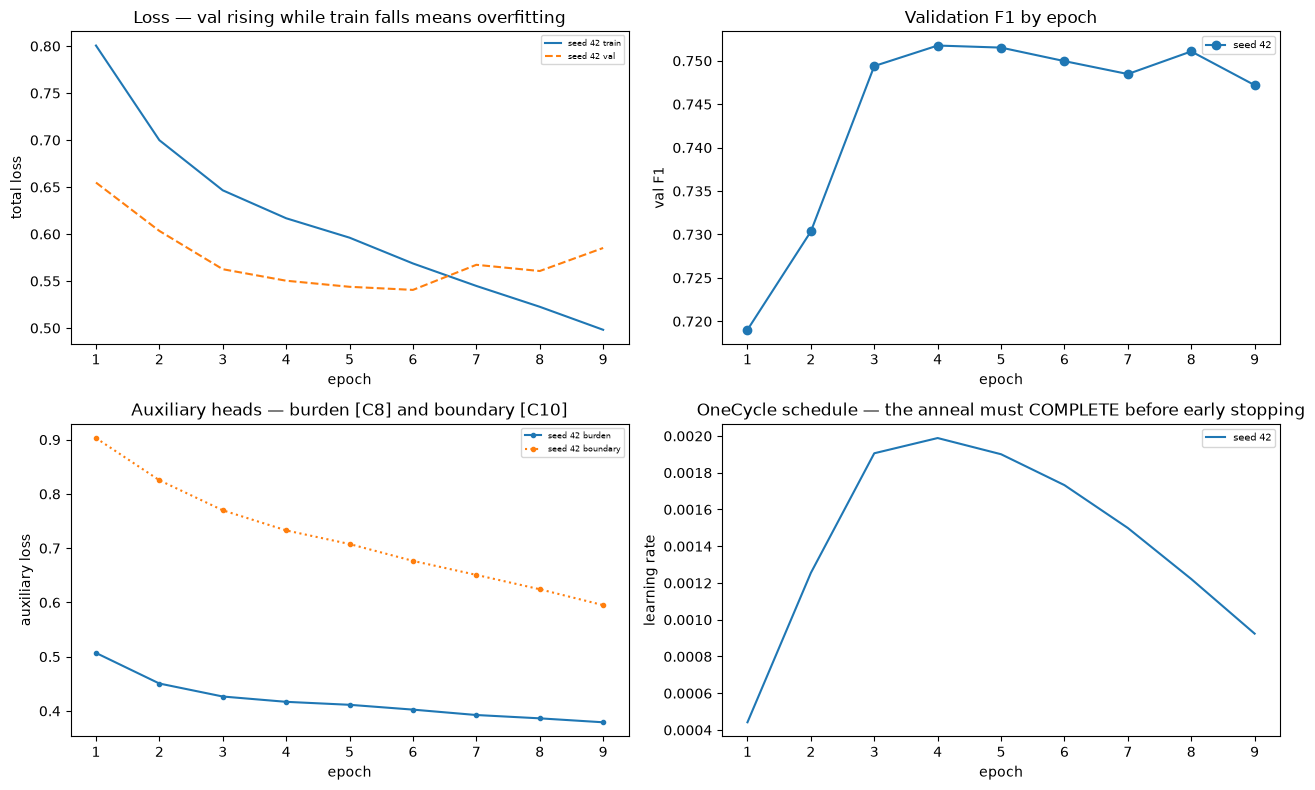

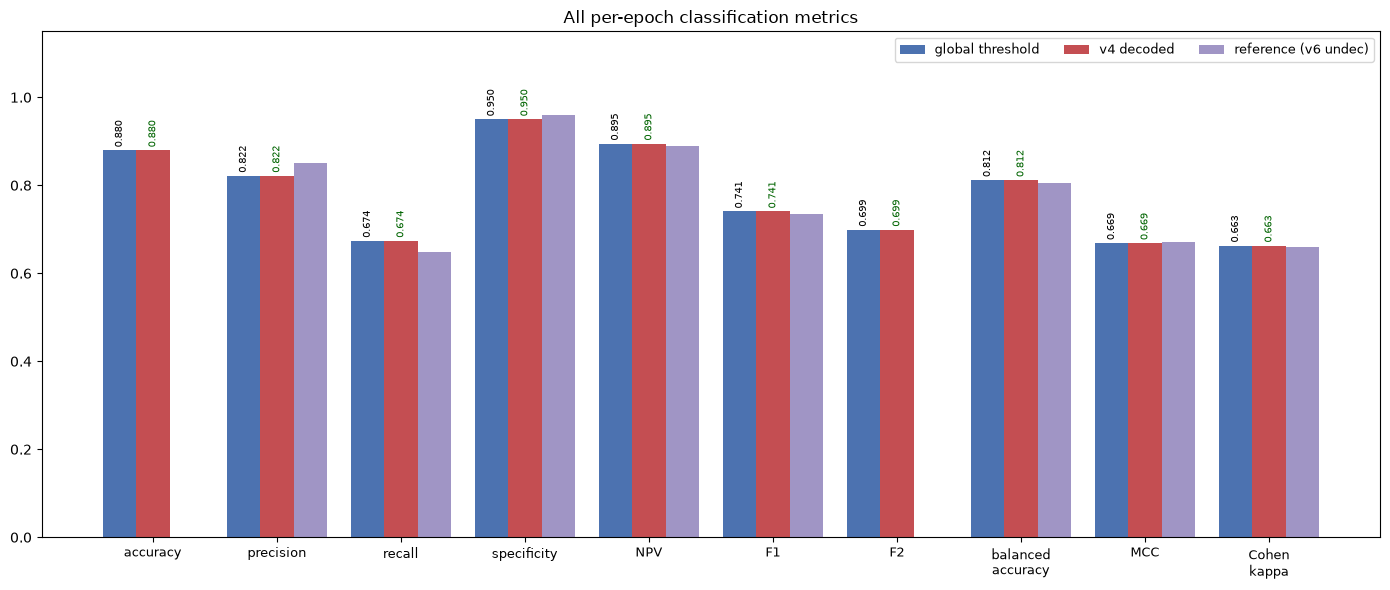

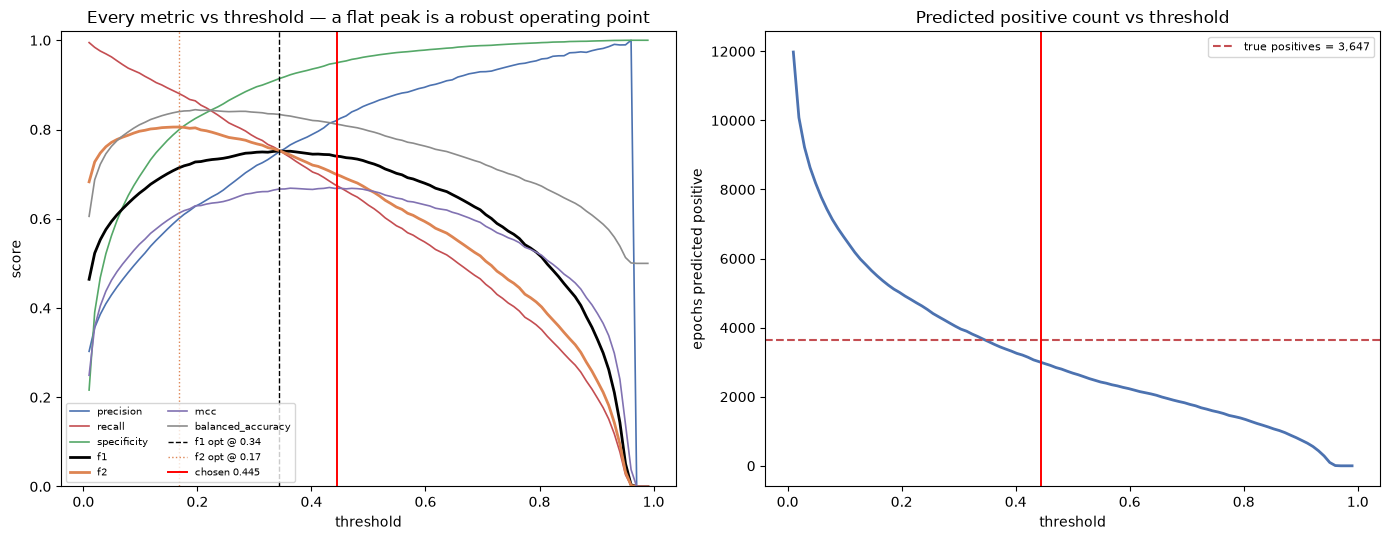

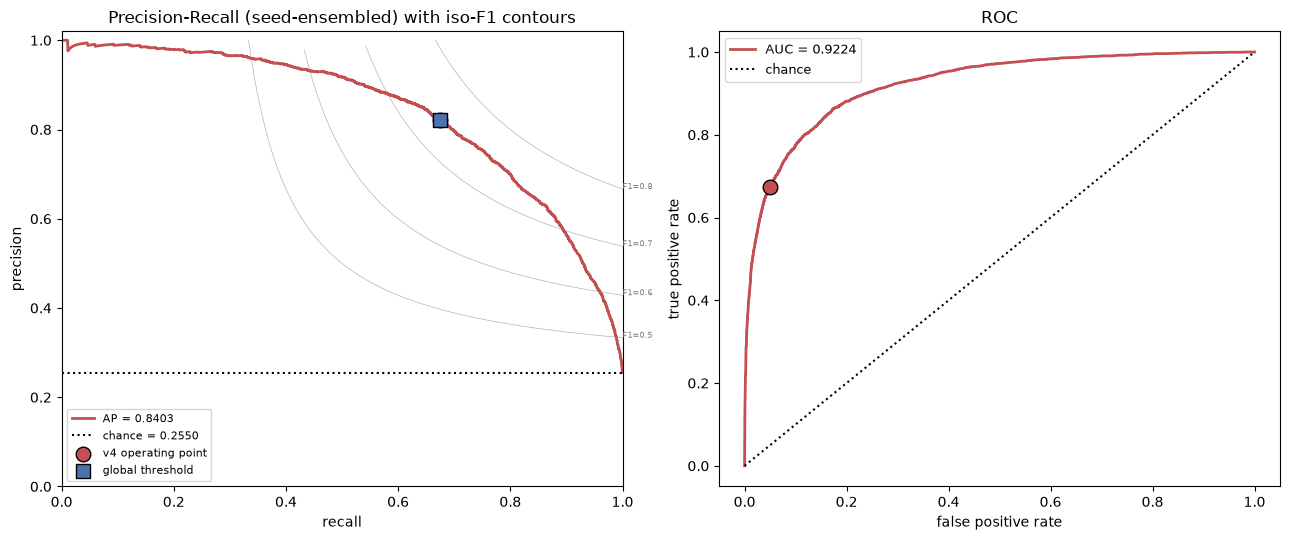

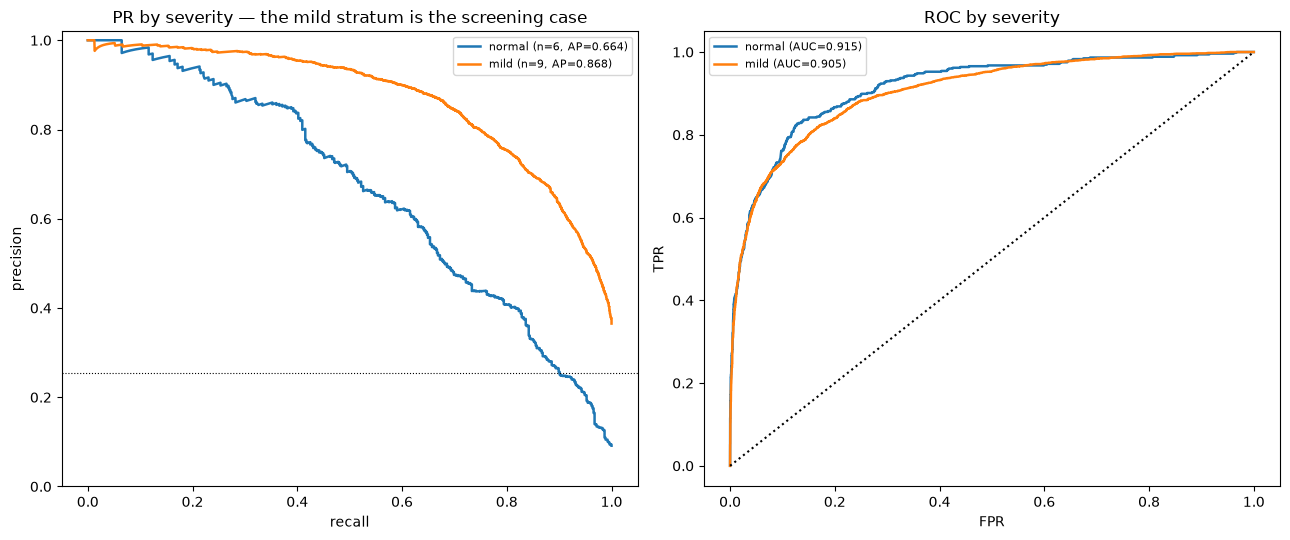

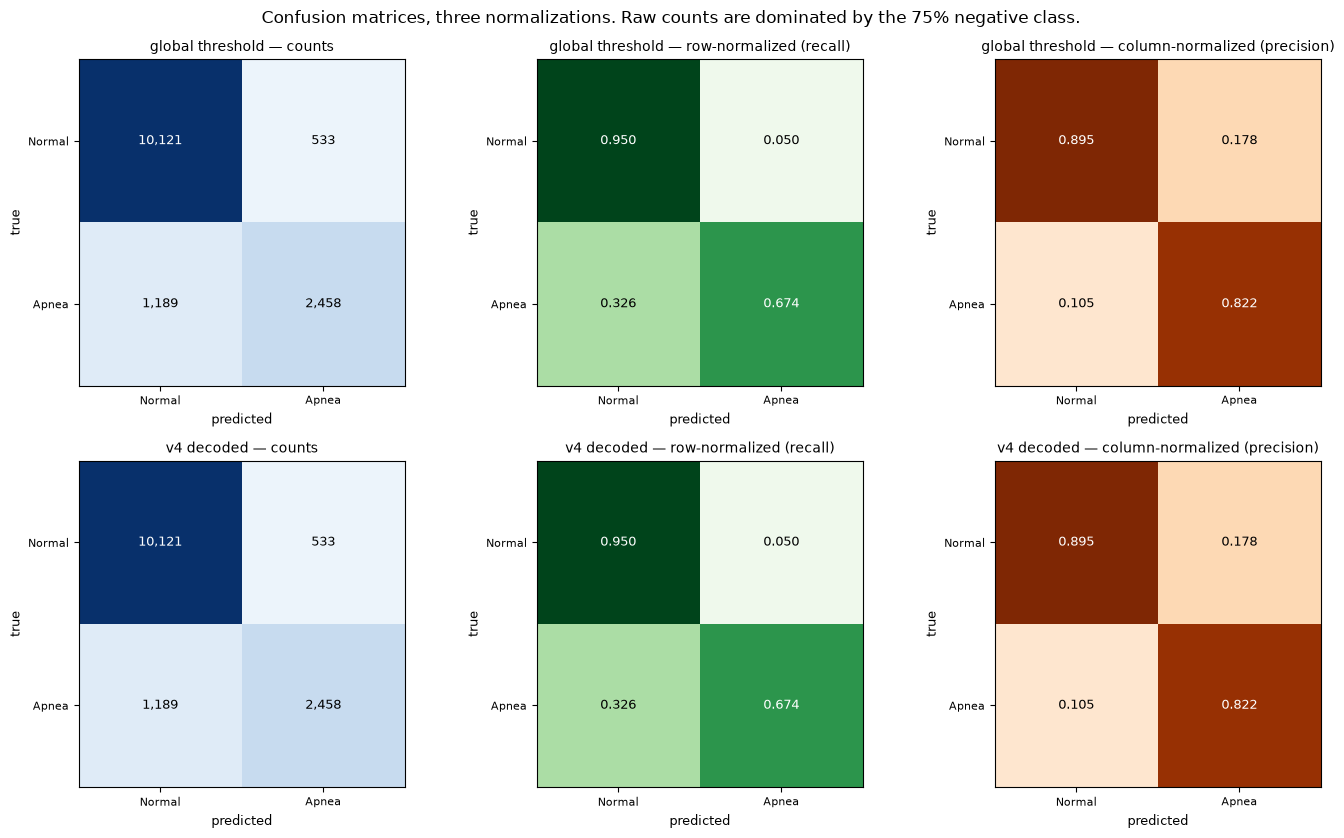

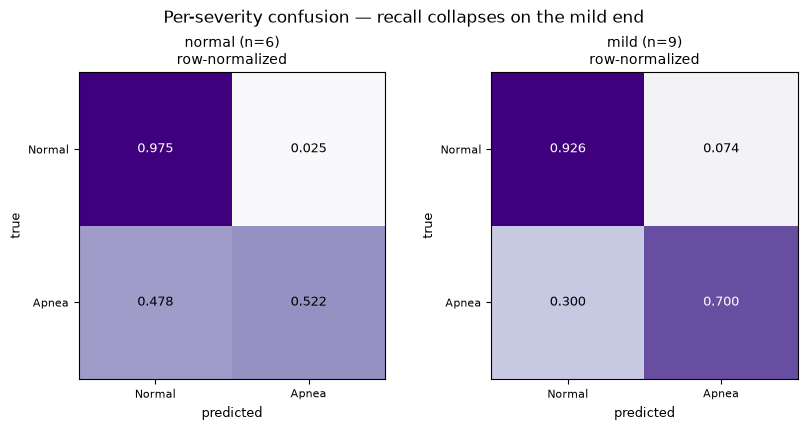

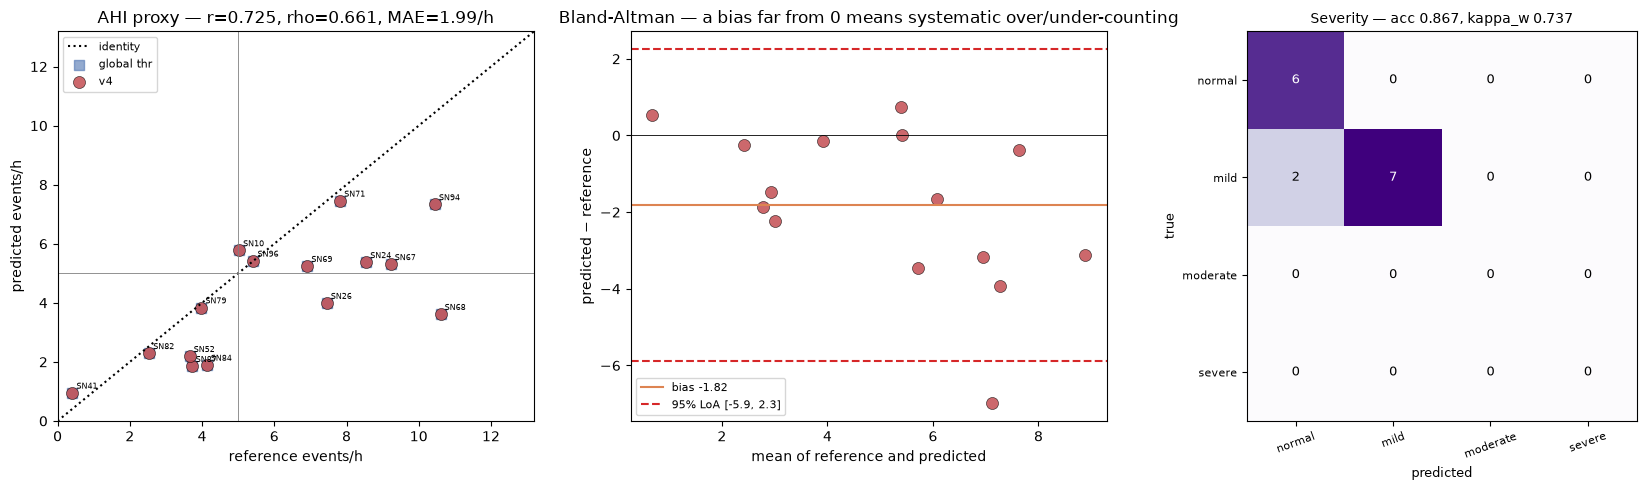

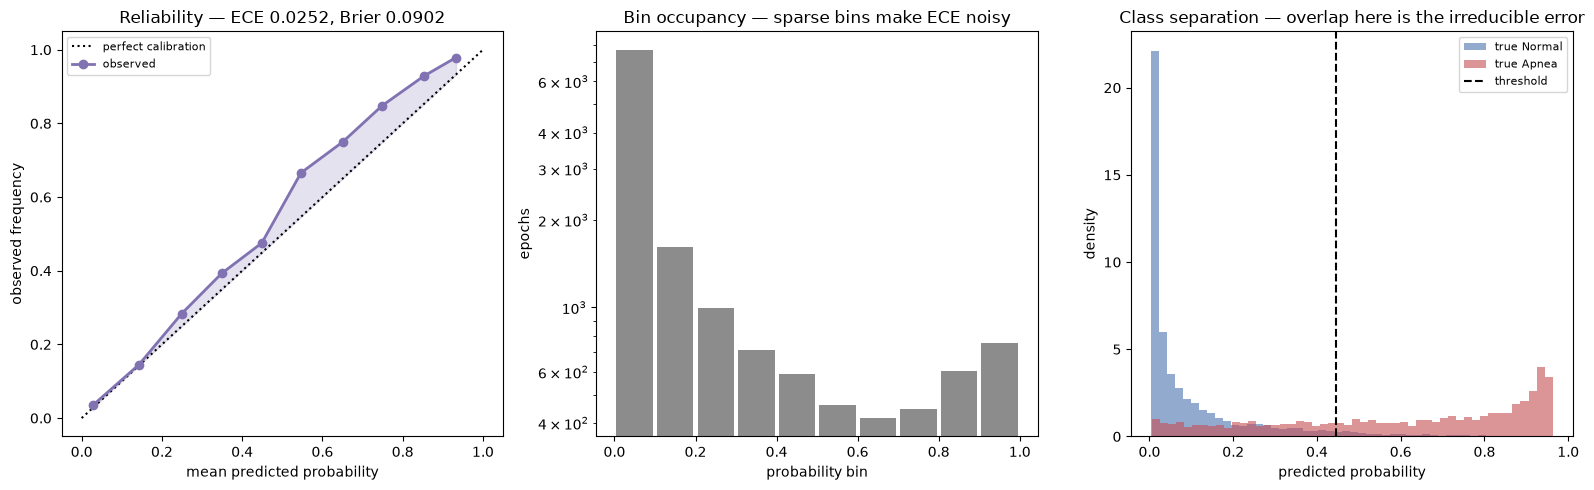

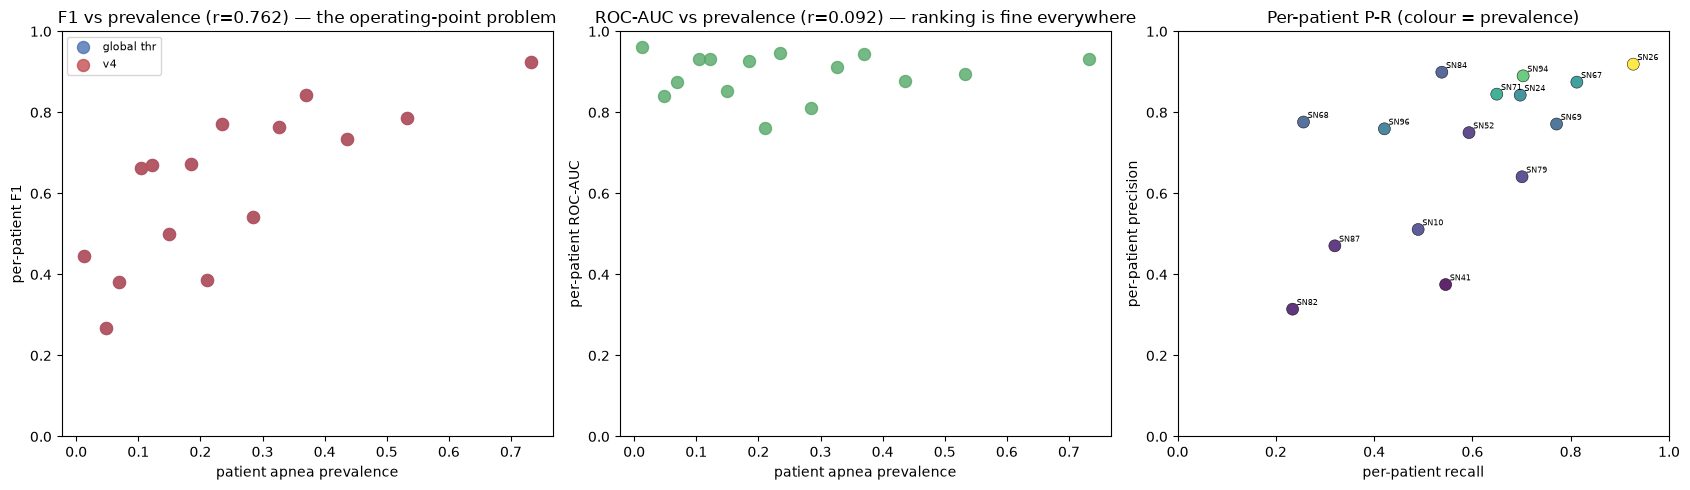

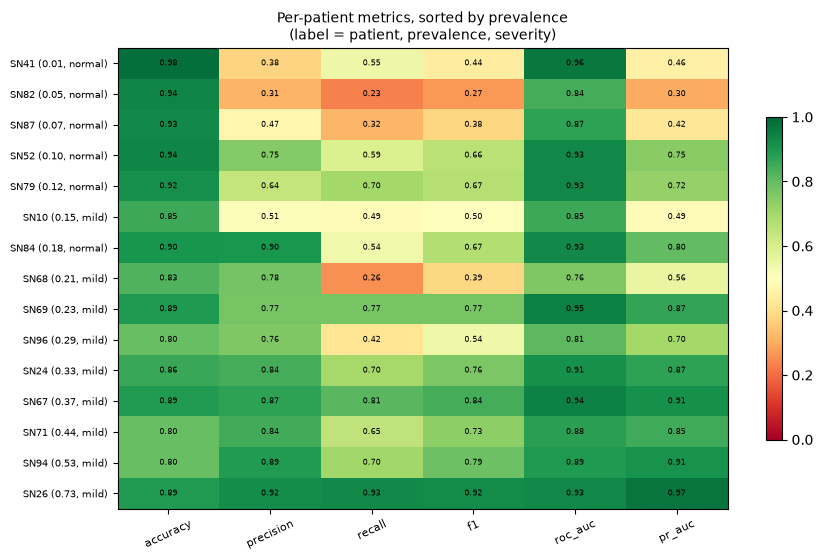

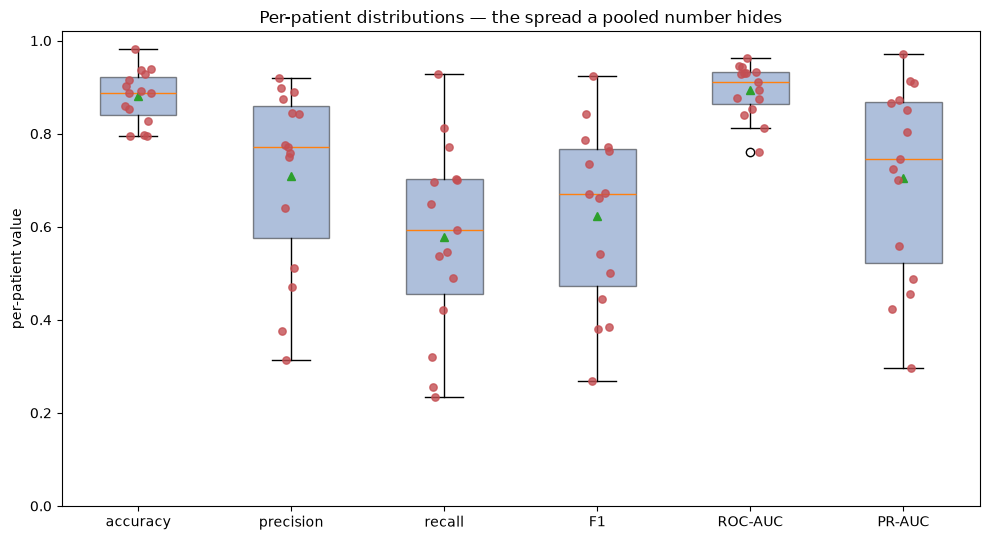

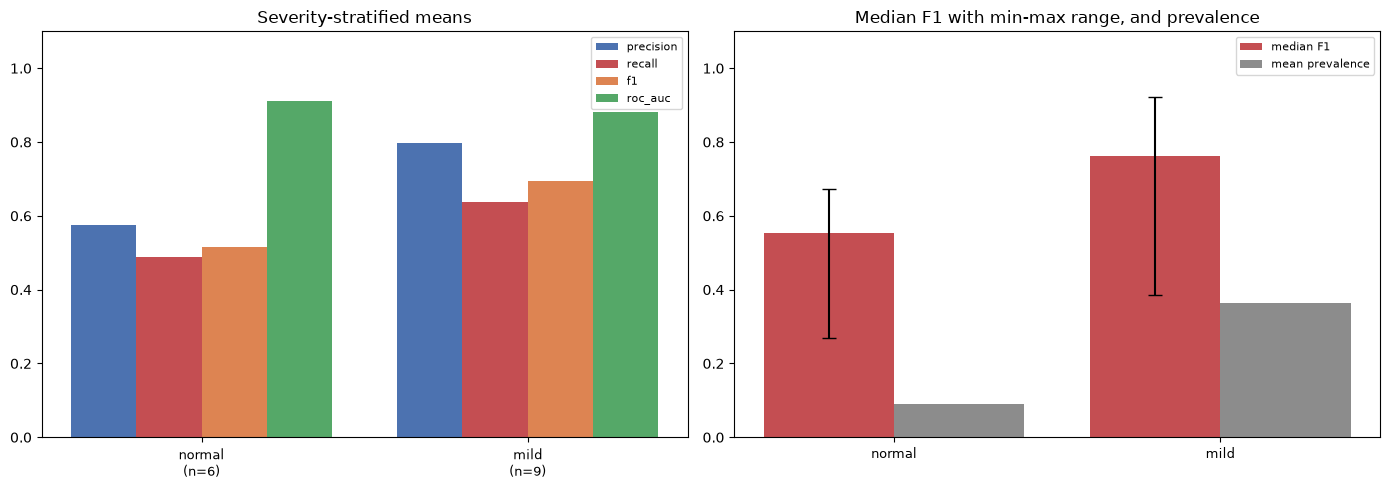

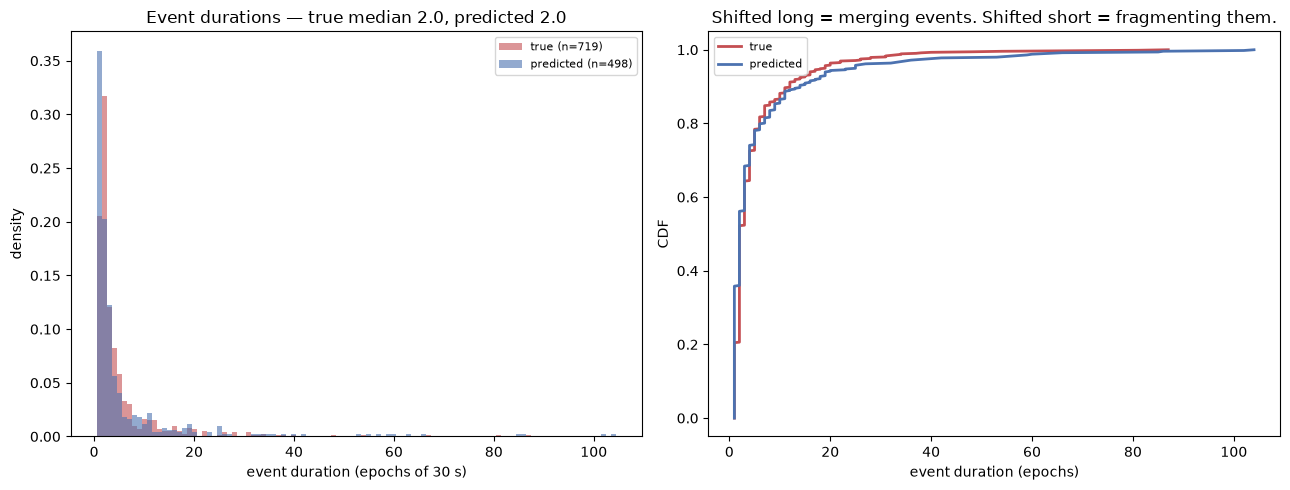

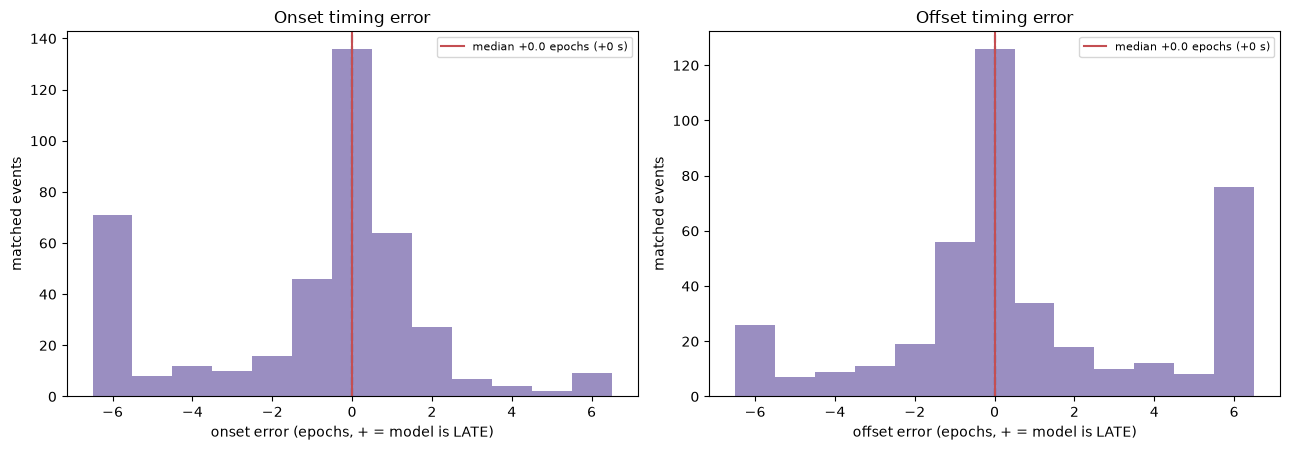

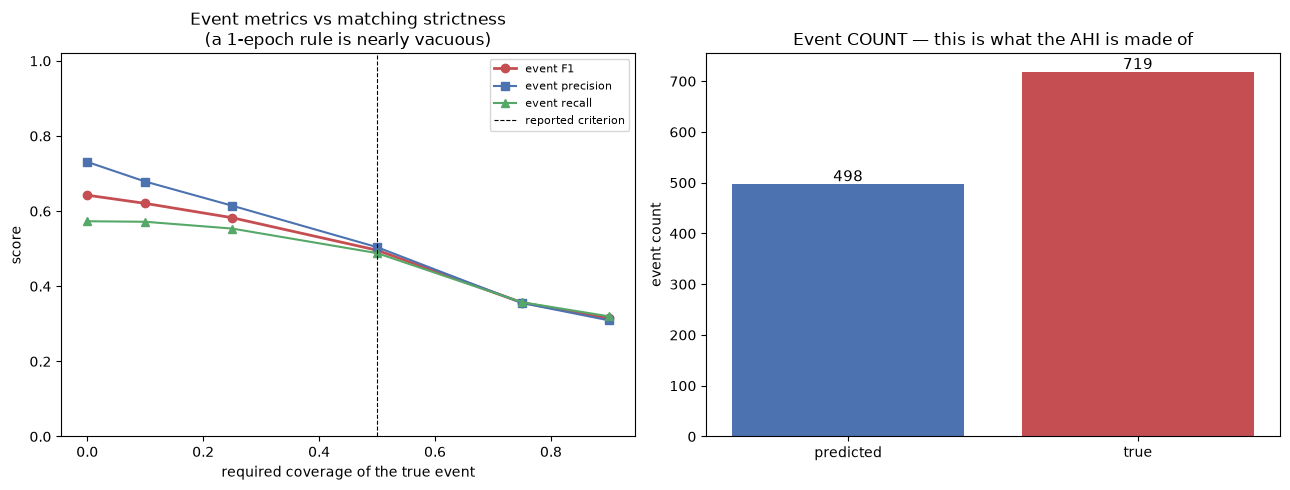

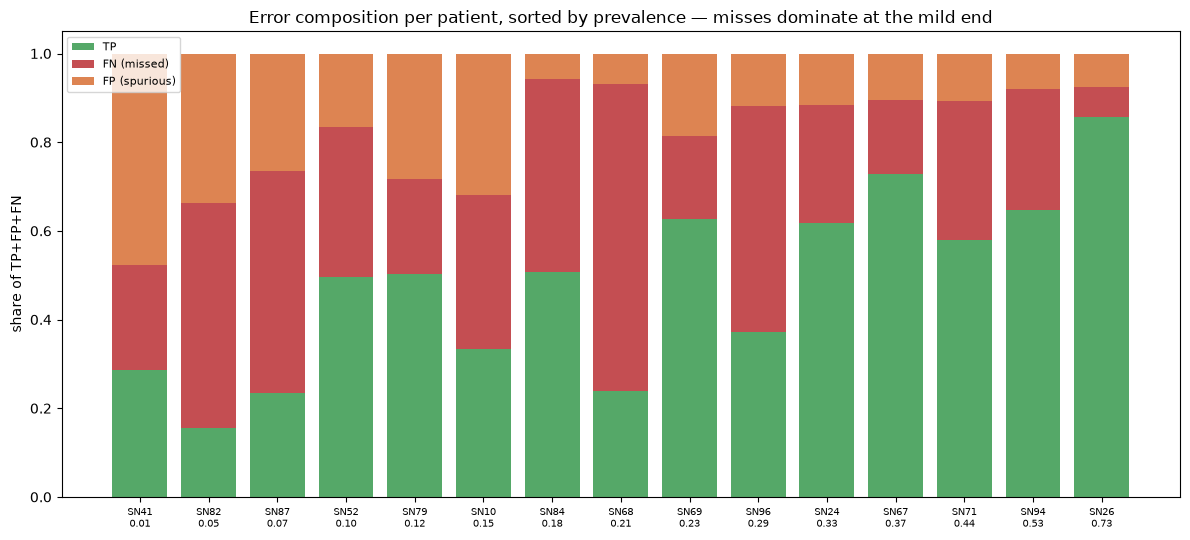

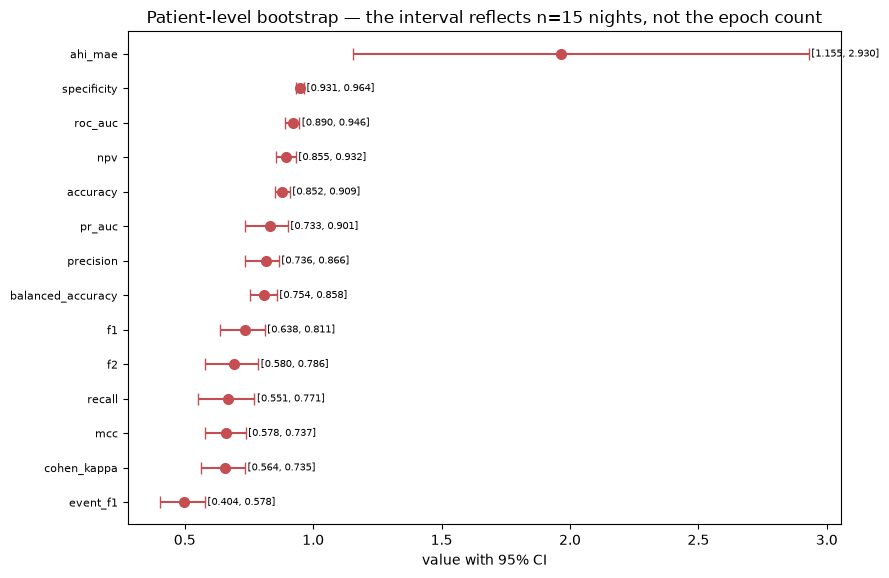

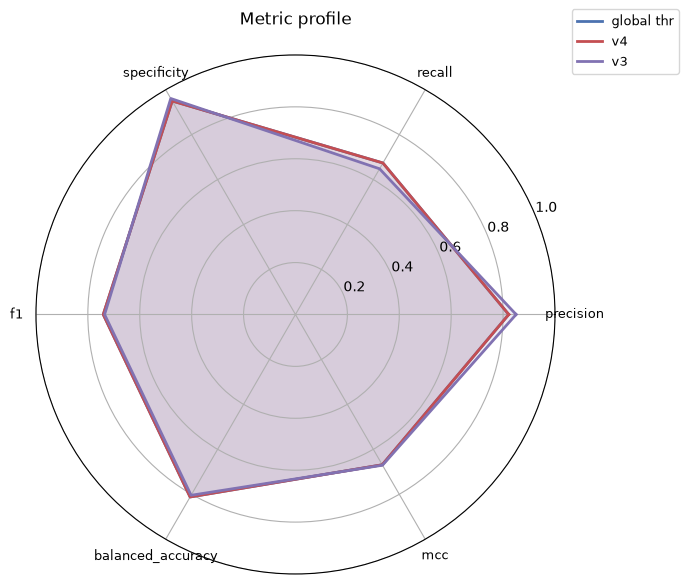

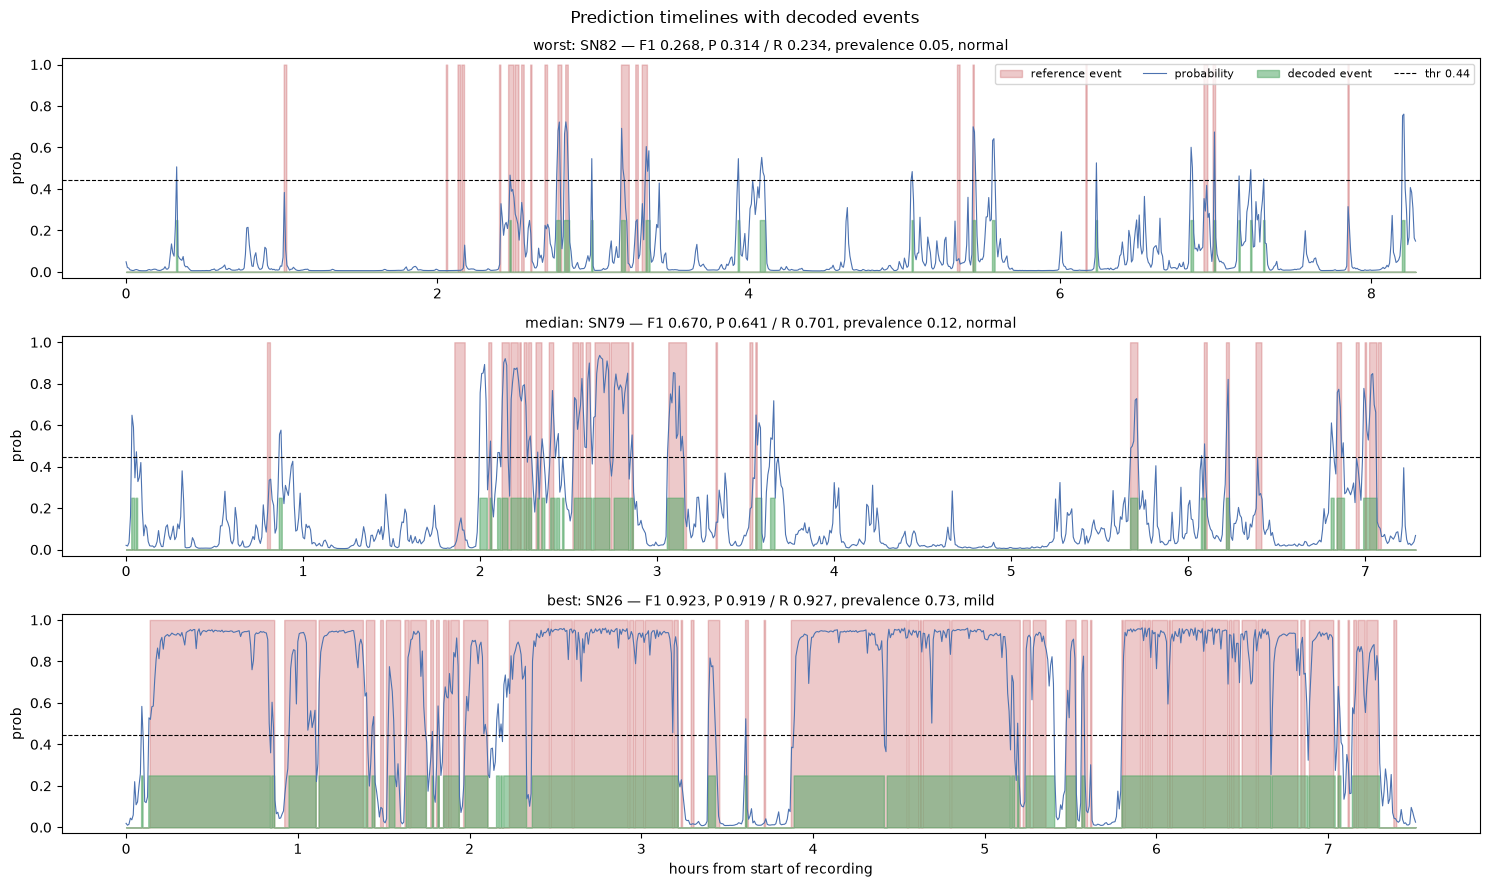

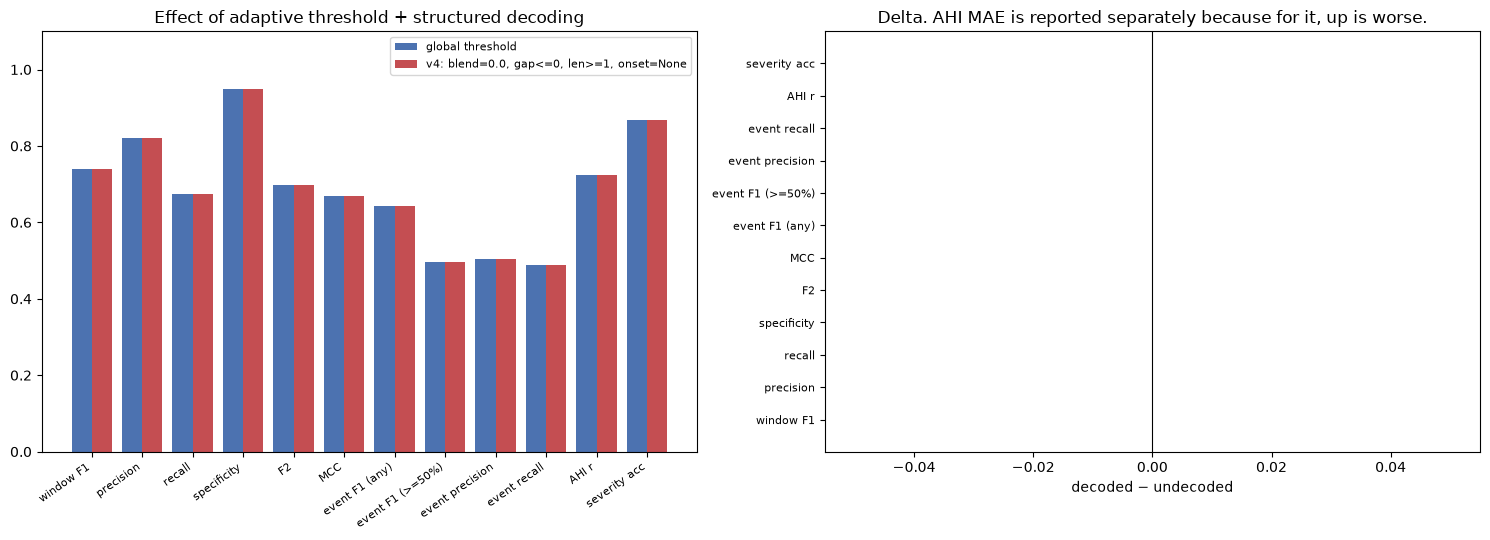

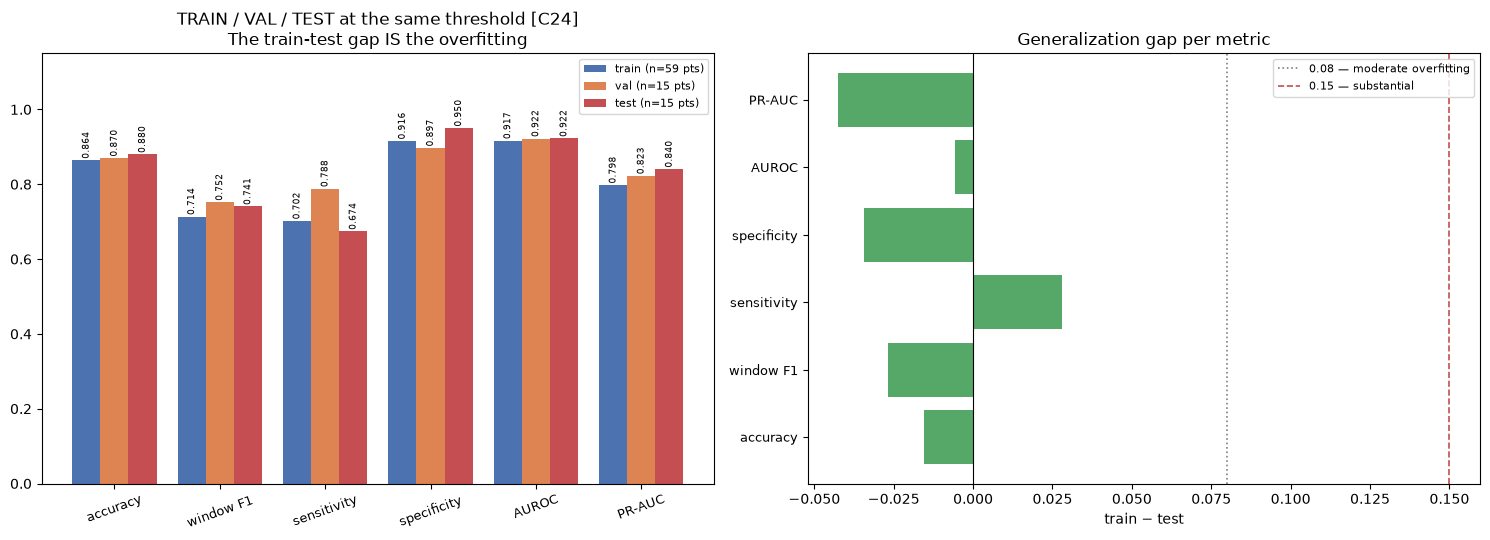


  PER-SEED RESULTS  [C18]
  Each seed is scored at ITS OWN validation-tuned threshold, undecoded.
  The ensemble rows are the headline numbers, shown both ways.

  CORE CLASSIFICATION METRICS
                 run  threshold  accuracy  precision  recall  specificity     f1     f2    mcc  roc_auc  pr_auc
             seed 42     0.4448    0.8796     0.8218   0.674         0.95 0.7406 0.6991 0.6687   0.9224  0.8403
ENSEMBLE (undecoded)     0.4448    0.8796     0.8218   0.674         0.95 0.7406 0.6991 0.6687   0.9224  0.8403
  ENSEMBLE (decoded)     0.4448    0.8796     0.8218   0.674         0.95 0.7406 0.6991 0.6687   0.9224  0.8403

  EXTENDED METRICS
                 run  balanced_accuracy  cohen_kappa    npv  brier    ece  event_f1_strict  ahi_r  ahi_mae  severity_acc  patient_f1_median
             seed 42              0.812       0.6632 0.8949 0.0902 0.0252            0.496 0.7252   1.9931        0.8667             0.6696
ENSEMBLE (undecoded)              0.812       0.6632 0.8949

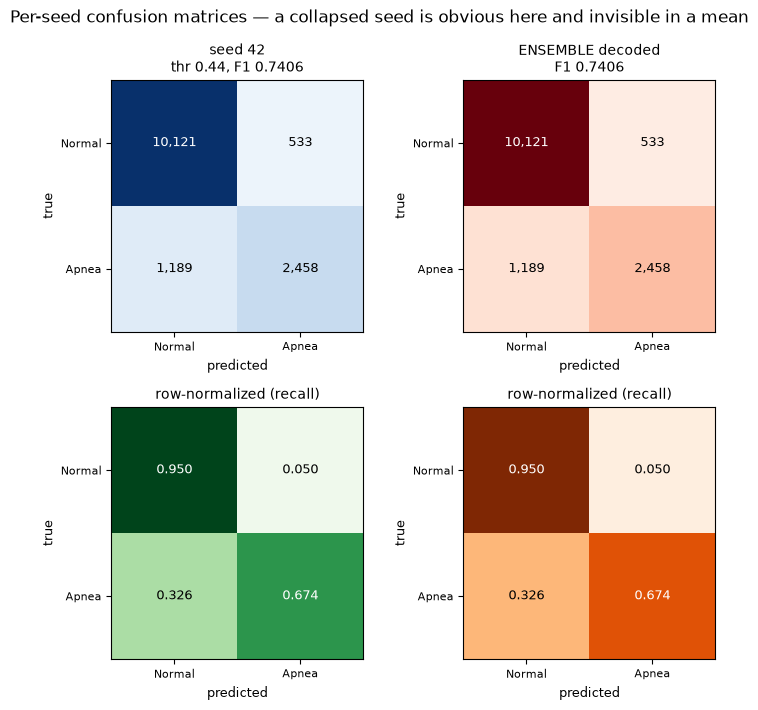

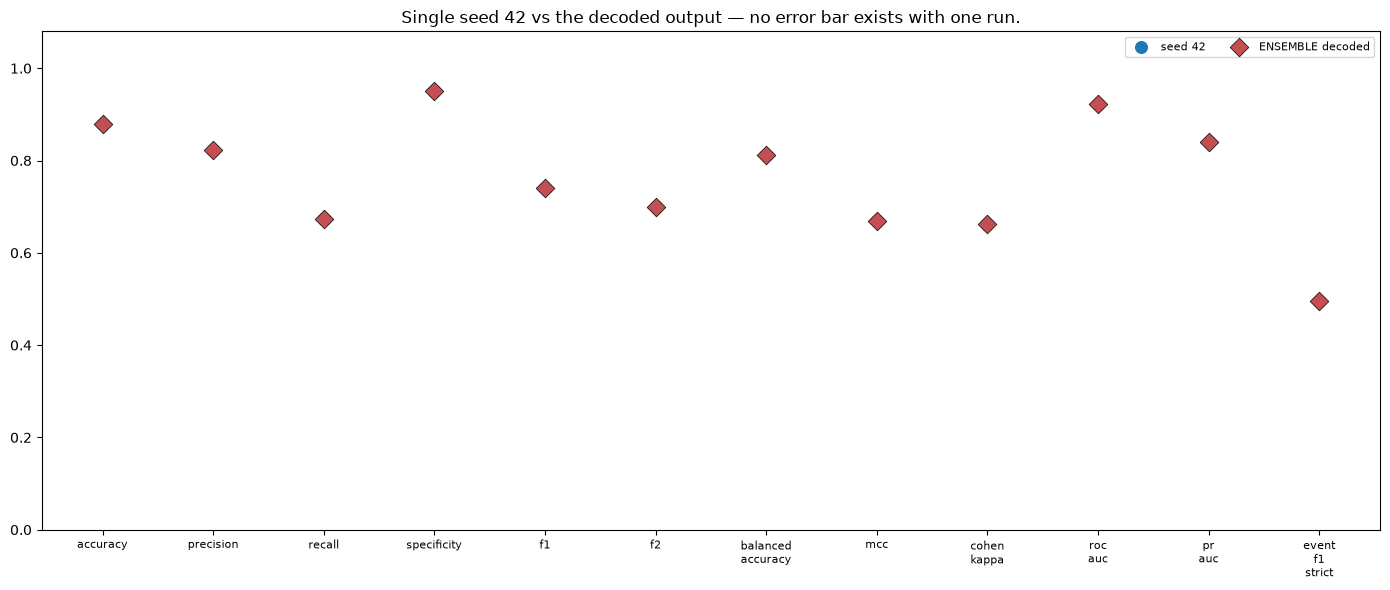

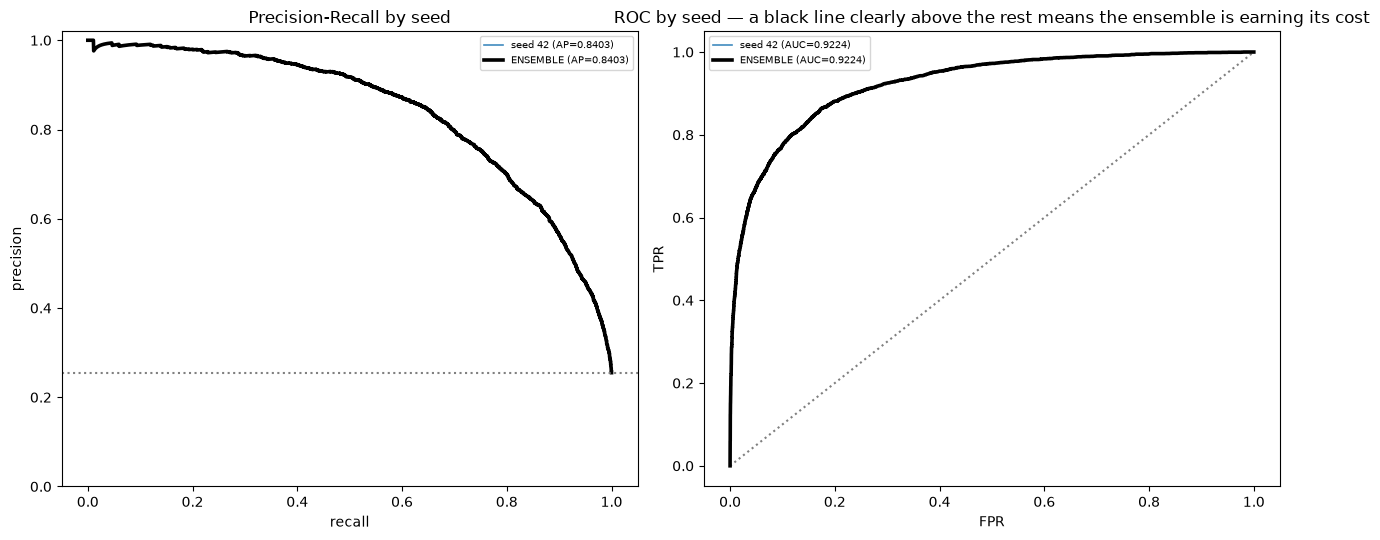


  FULL METRIC TABLE — 'no_decoding' = global threshold only
                 metric  no_decoding       v4  reference  delta_vs_ref  delta_decoding
                 PR-AUC       0.8403   0.8403     0.8480       -0.0077             0.0
                ROC-AUC       0.9224   0.9224     0.9271       -0.0047             0.0
              window F1       0.7406   0.7406     0.7355        0.0051             0.0
       window precision       0.8218   0.8218     0.8501       -0.0283             0.0
          window recall       0.6740   0.6740     0.6482        0.0258             0.0
     window specificity       0.9500   0.9500     0.9609       -0.0109             0.0
      balanced accuracy       0.8120   0.8120     0.8045        0.0075             0.0
              window F2       0.6991   0.6991        NaN           NaN             0.0
                    MCC       0.6687   0.6687     0.6707       -0.0020             0.0
            Cohen kappa       0.6632   0.6632     0.6607        0.002

In [22]:
# Trains the model. Figures appear inline AND are saved to OUTPUT_DIR.
if _ok:
    results = main()
else:
    print("Preflight failed — see cell 21.")
    results = None

## Cell 23 — Headline numbers

Pulls the key metrics out of `results` for a quick read.

In [23]:
# Headline metrics from the run above.
if results is not None:
    cmp = results["comparison"]
    key = ["PR-AUC", "ROC-AUC", "window F1", "window precision",
           "window recall", "window specificity", "MCC", "Cohen kappa",
           "event F1 (>=50%)", "AHI r", "AHI MAE (events/h)",
           "severity accuracy", "severity kappa_w"]
    print(cmp[cmp.metric.isin(key)].round(4).to_string(index=False))

    print("\nSeverity-stratified (the table a reviewer asks for):")
    print(results["v4"]["strata"].round(3).to_string(index=False))

            metric  no_decoding     v4  reference  delta_vs_ref  delta_decoding
            PR-AUC       0.8403 0.8403     0.8480       -0.0077             0.0
           ROC-AUC       0.9224 0.9224     0.9271       -0.0047             0.0
         window F1       0.7406 0.7406     0.7355        0.0051             0.0
  window precision       0.8218 0.8218     0.8501       -0.0283             0.0
     window recall       0.6740 0.6740     0.6482        0.0258             0.0
window specificity       0.9500 0.9500     0.9609       -0.0109             0.0
               MCC       0.6687 0.6687     0.6707       -0.0020             0.0
       Cohen kappa       0.6632 0.6632     0.6607        0.0025             0.0
  event F1 (>=50%)       0.4960 0.4960     0.4704        0.0256             0.0
             AHI r       0.7252 0.7252     0.8516       -0.1264             0.0
AHI MAE (events/h)       1.9931 1.9931     1.9695        0.0236             0.0
 severity accuracy       0.8667 0.8667  

---
# Loss-Function Ablation

**Optional. Run cells 24–28 only after cell 22 has finished** — they reuse its
functions and its exact split.

Trains four arms — BCE, Weighted BCE, Focal, Weighted Focal — on identical
data, split, seed and decoder. Roughly 4× the main runtime.

### What it can and cannot show

| Group | Metrics | What it tells you |
|---|---|---|
| **Discrimination** | AUROC, PR-AUC | Ranking quality. Independent of threshold *and* calibration. **The only fair loss comparison.** |
| **Calibration** | Brier, ECE | Are probabilities honest? `pos_weight` shifts every probability without reordering any — so this moves while AUROC doesn't. |
| **At-threshold** | accuracy, sensitivity, specificity, F1, MCC, κ | Properties of *model + threshold*. Tuning per arm largely cancels the effect being measured. |

Read AUROC/PR-AUC **first**. In your earlier run, AUROC spanned only
0.8891–0.8911 (identical ranking) while severity κ_w spanned 0.546–0.746 —
the losses changed where probabilities *sit*, not what the model *sees*.

## Cell 24 — Ablation documentation and imports

### `[C28]` The split is read back, not recomputed
`severity_ranked_split()` is deterministic, so recomputing usually gives the
same answer — but that is an **assumption**. If the cohort changed, a cache
file was rebuilt, or `SPLIT_RANK_BY` was flipped, the "same" call silently
returns a **different** split and every arm gets compared against a main-cell
result measured on other patients.

So this reads `split_assignment.csv` verbatim, *and* recomputes, and compares.
If they disagree it names the patients that moved and uses the CSV.

In [24]:
r"""
=============================================================================
 LOSS-FUNCTION ABLATION  —  NOTEBOOK CELL
 BCE · Weighted BCE · Focal · Weighted Focal
=============================================================================

 HOW TO USE

   1. Run the apnea_notebook.py cell FIRST. This cell needs its functions
      (run_split, window_metrics, ahi_metrics, ...) which that cell leaves in
      the notebook namespace.

   2. Paste this whole thing into the NEXT cell and run it.

   Result lands in `results_ablation`. Everything is written to
       /home/nishant/apneastudyproject/output/loss_ablation

=============================================================================
 THE SPLIT IS NOT RECOMPUTED — IT IS READ BACK  [C28]
=============================================================================

 You asked for the train/val/test split to stay exactly as it was. Two ways
 to achieve that, and only one of them is a guarantee:

   RECOMPUTE.  severity_ranked_split() is deterministic — no RNG — so calling
     it again with the same patient list and the same SPLIT_RANK_BY gives the
     same answer. But that is an ASSUMPTION. If the cohort changed (a cache
     file was rebuilt, a patient was added, SKIP_PATIENTS was edited, or
     SPLIT_RANK_BY was flipped between cells) the "same" call silently
     returns a DIFFERENT split, and every arm would then be compared against
     a main-cell result measured on other patients.

   READ IT BACK.  The main cell already wrote split_assignment.csv listing
     every patient and its fold/split. This cell loads that file and uses it
     verbatim. The split cannot drift, because it is not being derived.

 So: read the CSV, and ALSO recompute, and compare the two. If they disagree
 the cell says exactly which patients moved and stops rather than producing a
 quietly invalid comparison.

 If split_assignment.csv is missing (main cell not run yet, or output folder
 cleared), the cell falls back to recomputing and says so loudly.

=============================================================================
 WHAT THIS MEASURES, AND WHAT IT CANNOT
=============================================================================

 Metrics fall into three groups. Conflating them is the usual error in
 loss-comparison tables.

  1. DISCRIMINATION — AUROC, PR-AUC. Depend on the RANKING only: not on the
     threshold, not on calibration. The ONLY metrics that can show a loss
     taught the model to separate the classes better.

  2. CALIBRATION — Brier, ECE. Are the probabilities honest? pos_weight
     shifts every probability upward WITHOUT reordering any of them, so it
     can wreck calibration while leaving AUROC bit-for-bit identical. Not a
     discrimination win — but not nothing, because a miscalibrated model
     breaks a single global threshold across patients.

  3. AT-THRESHOLD — accuracy, sensitivity, specificity, precision, NPV, F1,
     F2, balanced accuracy, MCC, Cohen kappa. Properties of
     (model + threshold). This pipeline tunes a threshold on VALIDATION for
     every arm independently, which slides each model back to its own ROC
     curve's F1 optimum — largely cancelling the effect being measured.

 Read the table in that order. On the run you already have, AUROC spanned
 only 0.8891-0.8911 across all four arms (identical ranking) while severity
 kappa_w spanned 0.546-0.746. The losses did not change what the model SEES;
 they changed where its probabilities SIT, which moves the threshold, which
 changes the event COUNT, which is what the AHI is made of.

=============================================================================
"""

import os
import gc
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve, precision_recall_curve, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
)

## Cell 25 — Ablation configuration

`BEST_BY` decides which arm is "the best" — stated explicitly because the
answer genuinely differs by criterion. Every criterion's winner is printed
regardless, so you can see the disagreement.

`NOISE_FLOOR = 0.0097` is the measured 3-seed validation-F1 spread. Any
difference below **2σ** is reported as noise.

In [25]:
# =========================================================================
#  CONFIG
# =========================================================================
PROJECT_DIR = "/home/nishant/apneastudyproject"
ABL_DIR = os.path.join(PROJECT_DIR, "output2", "loss_ablation")

LOSSES = ["bce", "weighted_bce", "focal", "weighted_focal"]
PRETTY = {"bce": "BCE", "weighted_bce": "Weighted BCE",
          "focal": "Focal", "weighted_focal": "Weighted Focal"}
COLORS = {"bce": "#4C72B0", "weighted_bce": "#55A868",
          "focal": "#C44E52", "weighted_focal": "#8172B2"}

# Which metric names "the best model". Stated explicitly because the answer
# genuinely differs by criterion; every criterion's winner is printed anyway.
BEST_BY = "window_f1"     # or severity_kappa_w / pr_auc / event_f1 / mcc

DISCRIMINATION = ["auroc", "pr_auc"]
CALIBRATION = ["brier", "ece"]
AT_THRESHOLD = ["accuracy", "sensitivity", "specificity", "precision", "npv",
                "window_f1", "window_f2", "balanced_accuracy", "mcc",
                "cohen_kappa"]
DOWNSTREAM = ["event_f1", "event_precision", "event_recall", "ahi_r",
              "ahi_mae", "severity_acc", "severity_kappa_w",
              "patient_f1_median"]
LOWER_BETTER = {"brier", "ece", "ahi_mae"}

NOISE_FLOOR = 0.0097      # val-F1 spread measured across 3 seeds
REAL_SIGMA = 2.0

## Cell 26 — Split resolution and per-arm training

`resolve_splits()` implements the read-back-and-verify logic. `train_arm()`
trains one loss with everything else held fixed, and each arm gets **its own**
validation-tuned threshold.

In [26]:
# =========================================================================
#  1.  [C28] THE SPLIT — read back, then verified against a recompute
# =========================================================================
def load_split_from_csv(path, cache):
    """Reconstruct (train, val, test) per fold from split_assignment.csv."""
    if not os.path.exists(path):
        return None, "split_assignment.csv not found"
    df = pd.read_csv(path)
    need = {"fold", "split", "patient"}
    if not need <= set(df.columns):
        return None, f"CSV missing columns {need - set(df.columns)}"

    missing = [p for p in df.patient.unique() if p not in cache]
    if missing:
        return None, (f"{len(missing)} patient(s) in the CSV are not in the "
                      f"cache: {missing[:5]}")

    folds = []
    for fi in sorted(df.fold.unique()):
        d = df[df.fold == fi]
        tr = d.loc[d.split == "train", "patient"].astype(str).tolist()
        va = d.loc[d.split == "val", "patient"].astype(str).tolist()
        te = d.loc[d.split == "test", "patient"].astype(str).tolist()
        if not (tr and va and te):
            return None, f"fold {fi} has an empty split"
        overlap = (set(tr) & set(va)) | (set(tr) & set(te)) | (set(va) & set(te))
        if overlap:
            return None, f"fold {fi} has patients in two splits: {overlap}"
        folds.append((tr, va, te))
    return folds, f"{len(folds)} fold(s), {len(df.patient.unique())} patients"


def recompute_split(ok, cache):
    """What the main cell WOULD compute now. Used only to cross-check."""
    rank = getattr(M, "SPLIT_RANK_BY", "ratio")
    ratios = ([M.ahi_proxy(cache[p]["y"]) for p in ok] if rank == "ahi"
              else [float(np.mean(cache[p]["y"])) for p in ok])
    if M.N_FOLDS > 1:
        return M.grouped_folds(ok, ratios, M.N_FOLDS)
    return [M.severity_ranked_split(ok, ratios, M.VAL_FRAC, M.TEST_FRAC)]


def resolve_splits(ok, cache, out_dir):
    """Prefer the CSV; verify against a recompute; refuse to guess."""
    csv_path = os.path.join(out_dir, "split_assignment.csv")
    from_csv, note = load_split_from_csv(csv_path, cache)
    recomputed = recompute_split(ok, cache)

    print("\n  [C28] SPLIT SOURCE")
    if from_csv is None:
        print(f"    split_assignment.csv unusable: {note}")
        print( "    -> falling back to a RECOMPUTE. This matches the main cell")
        print( "       only if the cohort and SPLIT_RANK_BY are unchanged.")
        return recomputed

    print(f"    read from {csv_path}")
    print(f"    {note}")

    same = (len(from_csv) == len(recomputed) and
            all(set(a) == set(c) for f1, f2 in zip(from_csv, recomputed)
                for a, c in zip(f1, f2)))
    if same:
        print("    verified: a fresh recompute gives the identical split.")
    else:
        print("\n    " + "!" * 66)
        print("    WARNING — the CSV and a fresh recompute DISAGREE.")
        for fi, (fc, rc) in enumerate(zip(from_csv, recomputed)):
            for nm, a, c in zip(("train", "val", "test"), fc, rc):
                moved = set(a) ^ set(c)
                if moved:
                    print(f"      fold {fi} {nm}: {sorted(moved)}")
        print("    Something changed since the main cell ran (cohort, cache,")
        print("    SKIP_PATIENTS, or SPLIT_RANK_BY). USING THE CSV, so this")
        print("    ablation stays comparable to the main-cell result.")
        print("    " + "!" * 66)
    return from_csv


# =========================================================================
#  2.  TRAIN ONE ARM
# =========================================================================
def train_arm(loss_type, cache, splits, device, out_root):
    """One loss on the SAME data, split, seed and decoder as every other arm.

    Each arm gets its OWN validation-tuned threshold: scoring a conservative
    model at an aggressive model's operating point would measure the
    threshold, not the loss.
    """
    print(f"\n{'#' * 78}\n#  ARM {LOSSES.index(loss_type) + 1}/{len(LOSSES)}: "
          f"{PRETTY[loss_type]}   ({loss_type})\n{'#' * 78}")

    M.LOSS_TYPE = loss_type
    arm_dir = os.path.join(out_root, "arms", loss_type)
    os.makedirs(arm_dir, exist_ok=True)
    prev, M.OUTPUT_DIR = M.OUTPUT_DIR, arm_dir

    t0 = time.time()
    folds = [M.run_split(cache, tr, va, te, device,
                         f"  ({PRETTY[loss_type]}, fold {i})")
             for i, (tr, va, te) in enumerate(splits)]
    M.OUTPUT_DIR = prev

    if len(folds) == 1:
        R = folds[0]
        labels, probs, bounds = R["labels"], R["probs"], R["bounds"]
        base, final = R["base"], R["v4"]
    else:
        labels = np.concatenate([r["labels"] for r in folds])
        probs = np.concatenate([r["probs"] for r in folds])
        off, bounds = 0, []
        for r in folds:
            for pid, s, e in r["bounds"]:
                bounds.append((pid, s + off, e + off))
            off += len(r["labels"])
        pv = np.concatenate([r["v4"]["pred"] for r in folds])
        pb = np.concatenate([r["base"]["pred"] for r in folds])
        tv = {k: v for r in folds for k, v in r["v4"]["thr_map"].items()}
        tb = {k: v for r in folds for k, v in r["base"]["thr_map"].items()}

        def asm(pred, thr_map, tag):
            win, cm = M.window_metrics(labels, pred, probs)
            pp = M.per_patient_metrics(bounds, labels, probs, pred, thr_map)
            adf, ahi = M.ahi_metrics(bounds, labels, pred)
            _, cal = M.expected_calibration_error(labels, probs)
            return dict(tag=tag, pred=pred, thr_map=thr_map,
                        cfg=folds[0]["cfg"], window=win, cm=cm,
                        ev_loose=M.event_metrics(bounds, labels, pred, 0.0),
                        ev_strict=M.event_metrics(bounds, labels, pred, 0.5),
                        per_patient=pp, strata=M.severity_strata(pp),
                        ahi_df=adf, ahi=ahi, calib=cal)

        base, final = asm(pb, tb, "base"), asm(pv, tv, "final")

    runtime = (time.time() - t0) / 60
    w = final["window"]
    print(f"\n  [{PRETTY[loss_type]}] {runtime:.1f} min | "
          f"window F1 {w['f1']:.4f} | AUROC {w['roc_auc']:.4f} | "
          f"sens {w['recall']:.3f} | spec {w['specificity']:.3f}")

    gc.collect()
    if M.TORCH_AVAILABLE and M.torch.cuda.is_available():
        M.torch.cuda.empty_cache()

    return dict(loss=loss_type, folds=folds, base=base, final=final,
                labels=labels, probs=probs, bounds=bounds, runtime=runtime,
                global_thr=folds[0]["global_thr"],
                splits_eval=folds[0].get("splits_eval", {}),
                val_f1=[q["val_f1"] for r in folds for q in r["runs"]],
                thresholds=[q["threshold"] for r in folds for q in r["runs"]])

## Cell 27 — Ablation tables, plots and best-model dump

Builds the comparison tables, the significance verdicts, 10 figures, and the
`BEST_MODEL/` folder (11 files: all three confusion normalizations, the
4-class severity confusion, classification report, per-patient tables,
threshold and coverage sweeps).

In [27]:
# =========================================================================
#  3.  TABLES
# =========================================================================
def build_table(arms):
    rows = []
    for a in arms:
        w, ev, ahi = a["final"]["window"], a["final"]["ev_strict"], a["final"]["ahi"]
        pp = a["final"]["per_patient"]
        rows.append(dict(
            loss=PRETTY[a["loss"]], key=a["loss"],
            threshold=float(np.mean(list(a["final"]["thr_map"].values()))),
            auroc=w["roc_auc"], pr_auc=w["pr_auc"],
            brier=w["brier"], ece=w["ece"],
            accuracy=w["accuracy"], window_f1=w["f1"],
            sensitivity=w["recall"], specificity=w["specificity"],
            precision=w["precision"], npv=w["npv"],
            window_f2=w["f2"], balanced_accuracy=w["balanced_accuracy"],
            mcc=w["mcc"], cohen_kappa=w["cohen_kappa"],
            tn=w["tn"], fp=w["fp"], fn=w["fn"], tp=w["tp"],
            event_f1=ev["f1"], event_precision=ev["precision"],
            event_recall=ev["recall"], n_pred_events=ev["n_pred"],
            n_true_events=ev["n_true"],
            ahi_r=ahi["r"], ahi_mae=ahi["mae"],
            severity_acc=ahi["sev_acc"], severity_kappa_w=ahi["sev_kappa"],
            patient_f1_median=float(pp.f1.median()),
            patient_f1_min=float(pp.f1.min()),
            val_f1=float(np.mean(a["val_f1"])),
            runtime_min=round(a["runtime"], 1)))
    return pd.DataFrame(rows)


def build_tvt_table(arms):
    """Every arm on train / val / test — the generalization gap."""
    rows = []
    for a in arms:
        for split, v in (a.get("splits_eval") or {}).items():
            w = v["window"]
            rows.append(dict(
                loss=PRETTY[a["loss"]], split=split,
                n_patients=v["n_patients"], n_epochs=v["n_epochs"],
                prevalence=v["prevalence"], accuracy=w["accuracy"],
                window_f1=w["f1"], sensitivity=w["recall"],
                specificity=w["specificity"], auroc=w["roc_auc"],
                pr_auc=w["pr_auc"],
                event_f1=v.get("event", {}).get("f1", np.nan),
                ahi_mae=v.get("ahi", {}).get("mae", np.nan)))
    df = pd.DataFrame(rows)
    if len(df):
        gaps = []
        for lo in df.loss.unique():
            d = df[df.loss == lo].set_index("split")
            if {"train", "test"} <= set(d.index):
                gaps.append(dict(loss=lo,
                                 train_f1=d.loc["train", "window_f1"],
                                 test_f1=d.loc["test", "window_f1"],
                                 gap=d.loc["train", "window_f1"]
                                     - d.loc["test", "window_f1"]))
        if gaps:
            df.attrs["gaps"] = pd.DataFrame(gaps)
    return df


def significance(df):
    rows = []
    for m in DISCRIMINATION + CALIBRATION + AT_THRESHOLD + DOWNSTREAM:
        if m not in df.columns:
            continue
        v = df[m].astype(float)
        if v.isna().all():
            continue
        i = v.idxmin() if m in LOWER_BETTER else v.idxmax()
        spread = float(v.max() - v.min())
        rows.append(dict(
            metric=m,
            group=("DISCRIMINATION" if m in DISCRIMINATION else
                   "calibration" if m in CALIBRATION else
                   "at-threshold" if m in AT_THRESHOLD else "downstream"),
            best_arm=df.loss[i], best_value=float(v[i]),
            spread=spread, sigma=spread / NOISE_FLOOR,
            verdict="REAL" if spread > REAL_SIGMA * NOISE_FLOOR else "noise"))
    return pd.DataFrame(rows)


def print_report(df, sig, tvt, arms, best_key, splits):
    W = 118
    p = print
    p("\n" + "=" * W)
    p("  LOSS-FUNCTION ABLATION — identical data, SPLIT, seed and decoder; "
      "only the loss differs")
    p("=" * W)
    p(f"  split ranked by : {getattr(M, 'SPLIT_RANK_BY', 'ratio')}  "
      f"[C28] taken from split_assignment.csv, not recomputed")
    for fi, (tr, va, te) in enumerate(splits):
        p(f"  fold {fi}          train {len(tr)} | val {len(va)} | test {len(te)} patients")
    p(f"  seeds / folds   : {M.SEEDS} / {M.N_FOLDS}")
    p(f"  context         : {M.CHUNK_EPOCHS} epochs = "
      f"{M.CHUNK_EPOCHS * M.WINDOW_SEC / 60:.0f} min")
    p(f"  decoding        : {'OFF' if M.GAP_GRID == [0] else 'ON'}")

    p("\n" + "-" * W)
    p("  [1] DISCRIMINATION — ranking quality. Unaffected by threshold or "
      "calibration.")
    p("      The ONLY fair comparison of what the loss taught the model.")
    p("-" * W)
    t = df[["loss", "auroc", "pr_auc"]].copy()
    t.columns = ["Loss", "AUROC", "PR-AUC"]
    p(t.round(4).to_string(index=False))

    p("\n" + "-" * W)
    p("  [2] CALIBRATION — are the probabilities honest? (lower is better)")
    p("      pos_weight shifts every probability without reordering any, so "
      "these can move")
    p("      a long way while AUROC is unchanged. NOT evidence of a better "
      "model.")
    p("-" * W)
    t = df[["loss", "brier", "ece"]].copy()
    t.columns = ["Loss", "Brier", "ECE"]
    p(t.round(4).to_string(index=False))

    p("\n" + "=" * W)
    p("  [3] MAIN TABLE — WINDOW LEVEL, each arm at ITS OWN validation-tuned "
      "threshold")
    p("=" * W)
    p("      One 30-s epoch = one sample. 'window F1' is the per-epoch F1, "
      "NOT event F1.")
    t = df[["loss", "threshold", "accuracy", "window_f1", "sensitivity",
            "specificity", "precision", "npv", "cohen_kappa", "mcc",
            "auroc", "pr_auc"]].copy()
    t.columns = ["Loss", "Thr", "Accuracy", "Window F1", "Sensitivity",
                 "Specificity", "Precision", "NPV", "Cohen k", "MCC",
                 "AUROC", "PR-AUC"]
    p(t.round(4).to_string(index=False))
    p("\n      sensitivity = recall = TP/(TP+FN)     specificity = TN/(TN+FP)")
    p("      CAUTION: everything left of AUROC depends on the threshold, and "
      "tuning slides")
    p("      each arm to its own optimum — so these cannot cleanly separate "
      "losses.")

    p("\n  [4] EVENT LEVEL and CLINICAL — different units, different questions")
    p("      window F1 counts EPOCHS   event F1 counts EVENTS   "
      "AHI counts EVENTS/HOUR")
    t = df[["loss", "window_f1", "event_f1", "event_precision",
            "event_recall", "n_pred_events", "ahi_r", "ahi_mae",
            "severity_acc", "severity_kappa_w", "patient_f1_median"]].copy()
    t.columns = ["Loss", "Window F1", "Event F1", "Ev prec", "Ev rec",
                 "n pred ev", "AHI r", "AHI MAE", "Sev acc", "Sev k_w",
                 "Pt F1 med"]
    p(t.round(4).to_string(index=False))
    p(f"\n      true events = {int(df.n_true_events[0])}. An arm predicting far "
      "fewer is MERGING")
    p("      events, which halves the AHI even when window F1 looks fine.")

    p("\n  [5] CONFUSION COUNTS (window level)")
    p(df[["loss", "tn", "fp", "fn", "tp"]].to_string(index=False))

    if len(tvt):
        p("\n" + "=" * W)
        p("  [6] TRAIN / VAL / TEST — the generalization gap, measured")
        p("=" * W)
        p(tvt.round(4).to_string(index=False))
        if "gaps" in tvt.attrs:
            p("\n      train F1 − test F1:")
            p("      " + tvt.attrs["gaps"].round(4).to_string(index=False)
              .replace("\n", "\n      "))
            p("      >0.15 substantial overfitting · 0.08-0.15 moderate · "
              "<0.08 generalizing well")

    p("\n" + "=" * W)
    p(f"  [7] IS ANY DIFFERENCE REAL?   sigma = {NOISE_FLOOR} (3-seed val-F1 "
      f"spread), REAL needs > {REAL_SIGMA}sigma")
    p("=" * W)
    p(sig.round(4).to_string(index=False))

    real = sig[sig.verdict == "REAL"]
    disc = real[real.group == "DISCRIMINATION"]
    cal = real[real.group == "calibration"]
    dwn = real[real.group == "downstream"]
    att = real[real.group == "at-threshold"]

    p("\n" + "=" * W)
    p("  [8] CONCLUSION")
    p("=" * W)
    if len(disc):
        p(f"  DISCRIMINATION SEPARATES: {', '.join(disc.metric)}.")
        p("  AUROC and/or PR-AUC differ beyond noise, so the losses genuinely "
          "changed what")
        p("  the model learned to RANK. That is a real result.")
    else:
        p(f"  DISCRIMINATION: no separation "
          f"(AUROC {df.auroc.min():.4f}-{df.auroc.max():.4f}, "
          f"PR-AUC {df.pr_auc.min():.4f}-{df.pr_auc.max():.4f}).")
        p("  All four losses taught the model to rank equally well. Expected: "
          "these losses")
        p("  reweight the objective, they do not add information.")
    if len(cal):
        b = df.loc[df.ece.idxmin()]
        p(f"\n  CALIBRATION SEPARATES: best = {b.loss} "
          f"(ECE {b.ece:.4f} vs {df.ece.max():.4f} worst).")
        p("  This is the mechanism behind everything below: a miscalibrated "
          "model needs a")
        p("  different threshold, which changes the event COUNT, which is what "
          "the AHI is.")
    if len(att):
        p(f"\n  AT-THRESHOLD moved: {', '.join(att.metric)} — the operating "
          "point shifted.")
        p("  Expected; that is precisely what pos_weight does.")
    if len(dwn):
        w = dwn.sort_values("sigma", ascending=False).iloc[0]
        p(f"\n  CLINICAL / DOWNSTREAM SEPARATES: {', '.join(dwn.metric)}.")
        p(f"  Largest effect: {w.metric} ({w.sigma:.1f}sigma), best = "
          f"{w.best_arm}.")
        p("  THIS is the block that matters for a screening tool.")

    p("\n  BEST ARM BY EACH CRITERION:")
    for m in ["window_f1", "accuracy", "sensitivity", "specificity", "auroc",
              "pr_auc", "cohen_kappa", "mcc", "event_f1", "ahi_mae",
              "severity_kappa_w", "ece"]:
        if m not in df.columns:
            continue
        v = df[m].astype(float)
        i = v.idxmin() if m in LOWER_BETTER else v.idxmax()
        p(f"    {m:20s} {df.loss[i]:16s} {v[i]:.4f}"
          + ("   (lower is better)" if m in LOWER_BETTER else ""))

    p(f"\n  SELECTED AS BEST (BEST_BY = '{BEST_BY}'): {PRETTY[best_key]}")
    if len(arms[0]["val_f1"]) < 2:
        p(f"\n  [!] SINGLE SEED per arm. sigma = {NOISE_FLOOR} is carried over "
          "from an earlier")
        p("      3-seed run. Before reporting anything, set SEEDS = "
          "[42, 43, 44] and")
        p("      N_FOLDS = 5 in the main cell, re-run it, then re-run this.")


# =========================================================================
#  4.  PLOTS
# =========================================================================
def _save(fig, name, out_dir):
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, name), dpi=145, bbox_inches="tight")
    if getattr(M, "IN_NOTEBOOK", False):
        plt.show()
    plt.close(fig)


def make_plots(arms, df, sig, tvt, best_key, out_dir):
    keys = [a["loss"] for a in arms]
    nA = len(arms)
    w = 0.8 / nA

    # ------------------------------------------------------------ L01
    fig, ax = plt.subplots(1, 2, figsize=(17, 5.5),
                           gridspec_kw={"width_ratios": [1, 2.2]})
    mm = ["auroc", "pr_auc"]
    x = np.arange(len(mm))
    for i, k in enumerate(keys):
        r = df[df.key == k].iloc[0]
        ax[0].bar(x + (i - (nA - 1) / 2) * w, [r[m] for m in mm], w,
                  label=PRETTY[k], color=COLORS[k])
        for j, m in enumerate(mm):
            ax[0].text(j + (i - (nA - 1) / 2) * w, r[m] + .01, f"{r[m]:.4f}",
                       ha="center", fontsize=7, rotation=90)
    ax[0].set_xticks(x); ax[0].set_xticklabels(["AUROC", "PR-AUC"], fontsize=10)
    ax[0].set_ylim(0, 1.15); ax[0].legend(fontsize=8)
    ax[0].set_title("DISCRIMINATION\n(ranking only — the fair comparison)",
                    fontsize=10)

    mm = ["accuracy", "window_f1", "sensitivity", "specificity",
          "cohen_kappa", "mcc"]
    lbl = ["accuracy", "window F1", "sensitivity", "specificity",
           "Cohen κ", "MCC"]
    x = np.arange(len(mm))
    for i, k in enumerate(keys):
        r = df[df.key == k].iloc[0]
        ax[1].bar(x + (i - (nA - 1) / 2) * w, [r[m] for m in mm], w,
                  label=PRETTY[k], color=COLORS[k])
        for j, m in enumerate(mm):
            ax[1].text(j + (i - (nA - 1) / 2) * w, r[m] + .01, f"{r[m]:.3f}",
                       ha="center", fontsize=6.5, rotation=90)
    ax[1].set_xticks(x); ax[1].set_xticklabels(lbl, fontsize=9)
    ax[1].set_ylim(0, 1.15); ax[1].legend(fontsize=8, ncol=2)
    ax[1].set_title("AT EACH ARM'S OWN VALIDATION-TUNED THRESHOLD\n"
                    "(model + threshold — cannot cleanly separate losses)",
                    fontsize=10)
    _save(fig, "L01_main_comparison.png", out_dir)

    # ------------------------------------------------------------ L02
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
    for a in arms:
        k, lb, pr = a["loss"], a["labels"], a["probs"]
        f_, t_, _ = roc_curve(lb, pr)
        ax[0].plot(f_, t_, lw=1.8, color=COLORS[k],
                   label=f"{PRETTY[k]} ({roc_auc_score(lb, pr):.4f})")
        p_, r_, _ = precision_recall_curve(lb, pr)
        ax[1].plot(r_, p_, lw=1.8, color=COLORS[k],
                   label=f"{PRETTY[k]} ({average_precision_score(lb, pr):.4f})")
        ww = a["final"]["window"]
        ax[0].scatter([1 - ww["specificity"]], [ww["recall"]], s=90,
                      color=COLORS[k], edgecolor="k", zorder=5)
        ax[1].scatter([ww["recall"]], [ww["precision"]], s=90,
                      color=COLORS[k], edgecolor="k", zorder=5)
    ax[0].plot([0, 1], [0, 1], "k:", alpha=.5)
    ax[0].set_xlabel("1 − specificity"); ax[0].set_ylabel("sensitivity")
    ax[0].legend(fontsize=8, title="AUROC")
    ax[0].set_title("ROC — coincident curves with separated dots means the\n"
                    "loss moved the OPERATING POINT, not the model")
    ax[1].axhline(np.mean(arms[0]["labels"]), ls=":", c="k", alpha=.5)
    ax[1].set_xlabel("sensitivity"); ax[1].set_ylabel("precision")
    ax[1].set_ylim(0, 1.02); ax[1].legend(fontsize=8, title="PR-AUC")
    ax[1].set_title("Precision–Recall")
    _save(fig, "L02_roc_pr.png", out_dir)

    # ------------------------------------------------------------ L03
    fig, ax = plt.subplots(2, nA, figsize=(3.8 * nA, 7.6), squeeze=False)
    for i, a in enumerate(arms):
        c_, r_, _ = M.confusion_variants(a["final"]["cm"])
        ww = a["final"]["window"]
        star = "  ★ BEST" if a["loss"] == best_key else ""
        M._cm_panel(ax[0][i], c_,
                    f"{PRETTY[a['loss']]}{star}\ncounts — F1 {ww['f1']:.4f}",
                    "{:,.0f}", "Reds" if a["loss"] == best_key else "Blues")
        M._cm_panel(ax[1][i], r_,
                    f"row-normalized\nsens {ww['recall']:.3f} · "
                    f"spec {ww['specificity']:.3f}", "{:.3f}", "Greens")
    fig.suptitle("Confusion matrices by loss (top: counts, bottom: recall "
                 "per true class)", fontsize=13)
    _save(fig, "L03_confusion_all.png", out_dir)

    # ------------------------------------------------------------ L04
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    for a in arms:
        k = a["loss"]
        sw = M.threshold_sweep(a["labels"], a["probs"])
        thr = np.mean(list(a["final"]["thr_map"].values()))
        ax[0].plot(sw.threshold, sw.f1, lw=1.8, color=COLORS[k], label=PRETTY[k])
        ax[0].axvline(thr, color=COLORS[k], ls=":", lw=1.2)
        ax[1].plot(sw.threshold, sw.recall, lw=1.8, color=COLORS[k],
                   label=PRETTY[k])
        ax[1].plot(sw.threshold, sw.precision, lw=1.2, ls="--",
                   color=COLORS[k], alpha=.7)
        ax[2].hist(a["probs"], bins=60, histtype="step", lw=1.7,
                   color=COLORS[k], density=True, label=PRETTY[k])
        ax[2].axvline(thr, color=COLORS[k], ls=":", lw=1.2)
    ax[0].set_xlabel("threshold"); ax[0].set_ylabel("window F1")
    ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=8)
    ax[0].set_title("F1 vs threshold (dotted = chosen point)\n"
                    "Same peak at different thresholds = same model,\n"
                    "different calibration")
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("score")
    ax[1].set_ylim(0, 1.02); ax[1].legend(fontsize=8)
    ax[1].set_title("sensitivity (solid) · precision (dashed)")
    ax[2].set_xlabel("predicted probability"); ax[2].set_ylabel("density")
    ax[2].set_yscale("log"); ax[2].legend(fontsize=8)
    ax[2].set_title("Probability distributions — THIS is what\nthe loss "
                    "actually changes")
    _save(fig, "L04_threshold_calibration.png", out_dir)

    # ------------------------------------------------------------ L05
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    mm = ["ahi_r", "severity_acc", "severity_kappa_w", "event_f1"]
    lbl = ["AHI r", "severity acc", "severity κ_w", "event F1"]
    x = np.arange(len(mm))
    for i, k in enumerate(keys):
        r = df[df.key == k].iloc[0]
        ax[0].bar(x + (i - (nA - 1) / 2) * w, [r[m] for m in mm], w,
                  label=PRETTY[k], color=COLORS[k])
        for j, m in enumerate(mm):
            ax[0].text(j + (i - (nA - 1) / 2) * w, r[m] + .01, f"{r[m]:.3f}",
                       ha="center", fontsize=7, rotation=90)
    ax[0].set_xticks(x); ax[0].set_xticklabels(lbl, fontsize=9)
    ax[0].set_ylim(0, 1.15); ax[0].legend(fontsize=8)
    ax[0].set_title("CLINICAL ENDPOINT by loss (higher is better)")
    ax[1].bar(np.arange(nA), df.ahi_mae, color=[COLORS[k] for k in keys])
    for i, v in enumerate(df.ahi_mae):
        ax[1].text(i, v + .05, f"{v:.2f}", ha="center", fontsize=9)
    ax[1].set_xticks(np.arange(nA))
    ax[1].set_xticklabels([PRETTY[k] for k in keys], fontsize=8, rotation=15)
    ax[1].set_ylabel("AHI MAE (events/h)")
    ax[1].set_title("AHI mean absolute error — LOWER is better")
    _save(fig, "L05_clinical.png", out_dir)

    # ------------------------------------------------------------ L06
    v = sig.sort_values("sigma")
    if len(v):
        fig, ax = plt.subplots(figsize=(11, max(4.5, .38 * len(v))))
        cols = ["#C44E52" if s > REAL_SIGMA else "#8C8C8C" for s in v.sigma]
        ax.barh(np.arange(len(v)), v.sigma, color=cols)
        ax.axvline(REAL_SIGMA, c="k", ls="--", lw=1.4,
                   label=f"{REAL_SIGMA}σ — left of this is noise")
        ax.set_yticks(np.arange(len(v)))
        ax.set_yticklabels([f"{r.metric}  [{r.group}]" for r in v.itertuples()],
                           fontsize=8)
        ax.set_xlabel(f"arm-to-arm spread ÷ seed noise floor (σ = {NOISE_FLOOR})")
        ax.legend(fontsize=9)
        ax.set_title("Does the loss function matter, metric by metric?")
        _save(fig, "L06_significance.png", out_dir)

    # ------------------------------------------------------------ L07
    rn = ["sensitivity", "specificity", "precision", "window_f1",
          "balanced_accuracy", "mcc", "auroc"]
    ang = np.linspace(0, 2 * np.pi, len(rn), endpoint=False).tolist()
    ang += ang[:1]
    fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw=dict(polar=True))
    for a in arms:
        r = df[df.key == a["loss"]].iloc[0]
        vv = [float(r[m]) for m in rn]
        ax.plot(ang, vv + [vv[0]], lw=3 if a["loss"] == best_key else 1.8,
                color=COLORS[a["loss"]],
                label=PRETTY[a["loss"]] + (" ★" if a["loss"] == best_key else ""))
        ax.fill(ang, vv + [vv[0]], alpha=.08, color=COLORS[a["loss"]])
    ax.set_xticks(ang[:-1])
    ax.set_xticklabels(["sensitivity", "specificity", "precision", "window F1",
                        "balanced\naccuracy", "MCC", "AUROC"], fontsize=9)
    ax.set_ylim(0, 1)
    ax.legend(loc="upper right", bbox_to_anchor=(1.32, 1.1), fontsize=9)
    ax.set_title("Metric profile by loss", fontsize=12, pad=24)
    _save(fig, "L07_radar.png", out_dir)

    # ------------------------------------------------------------ L08
    if len(tvt):
        splits_present = [s for s in ("train", "val", "test")
                          if s in set(tvt.split)]
        scol = {"train": "#4C72B0", "val": "#DD8452", "test": "#C44E52"}
        fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
        x = np.arange(nA); ws = 0.8 / len(splits_present)
        for i, sp in enumerate(splits_present):
            d = tvt[tvt.split == sp].set_index("loss")
            vals = [d.window_f1.get(PRETTY[k], np.nan) for k in keys]
            ax[0].bar(x + (i - (len(splits_present) - 1) / 2) * ws, vals, ws,
                      label=sp, color=scol[sp])
        ax[0].set_xticks(x)
        ax[0].set_xticklabels([PRETTY[k] for k in keys], fontsize=8, rotation=15)
        ax[0].set_ylim(0, 1.12); ax[0].legend(fontsize=9)
        ax[0].set_title("Window F1 on TRAIN / VAL / TEST")
        if "gaps" in tvt.attrs:
            g = tvt.attrs["gaps"]
            ax[1].bar(np.arange(len(g)), g.gap,
                      color=["#C44E52" if x_ > .08 else "#55A868"
                             for x_ in g.gap])
            for i, vv in enumerate(g.gap):
                ax[1].text(i, vv + .004, f"{vv:+.3f}", ha="center", fontsize=9)
            ax[1].axhline(.08, c="grey", ls=":", lw=1.2, label="0.08 moderate")
            ax[1].axhline(.15, c="#C44E52", ls="--", lw=1.2,
                          label="0.15 substantial")
            ax[1].set_xticks(np.arange(len(g)))
            ax[1].set_xticklabels(g.loss, fontsize=8, rotation=15)
            ax[1].set_ylabel("train F1 − test F1"); ax[1].legend(fontsize=8)
            ax[1].set_title("Generalization gap by loss")
        _save(fig, "L08_train_val_test.png", out_dir)

    # ------------------------------------------------------------ L09
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    wide = None
    for a in arms:
        c = a["final"]["per_patient"].set_index("patient")["f1"].rename(
            PRETTY[a["loss"]])
        wide = c.to_frame() if wide is None else wide.join(c)
    if wide is not None:
        wide = wide.loc[wide.mean(1).sort_values().index]
        xx = np.arange(len(wide))
        for k in keys:
            ax[0].scatter(xx, wide[PRETTY[k]], s=55, alpha=.85,
                          color=COLORS[k], label=PRETTY[k])
        if len(wide.columns) > 1:
            ax[0].errorbar(xx, wide.mean(1), yerr=wide.std(1, ddof=1), fmt="_",
                           ms=20, color="k", capsize=3, lw=1, zorder=0)
        ax[0].set_xticks(xx)
        ax[0].set_xticklabels(wide.index, rotation=60, fontsize=7)
        ax[0].set_ylabel("per-patient window F1"); ax[0].set_ylim(0, 1)
        ax[0].legend(fontsize=8)
        ax[0].set_title("Per-patient F1 by loss — a wide spread on one patient\n"
                        "means that score is luck, not loss choice")
    sev = list(M.SEVERITY_NAMES)
    xx = np.arange(len(sev))
    for i, a in enumerate(arms):
        st = a["final"]["strata"].set_index("severity")
        ax[1].bar(xx + (i - (nA - 1) / 2) * w,
                  [st.mean_f1.get(s, np.nan) for s in sev], w,
                  color=COLORS[a["loss"]], label=PRETTY[a["loss"]])
    ax[1].set_xticks(xx); ax[1].set_xticklabels(sev, fontsize=9)
    ax[1].set_ylim(0, 1.05); ax[1].legend(fontsize=8)
    ax[1].set_title("Severity-stratified mean F1 by loss\n"
                    "(empty bars = that band absent from the test split)")
    _save(fig, "L09_per_patient_severity.png", out_dir)

    # ------------------------------------------------------------ L10
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    for a in arms:
        k, first = a["loss"], True
        for r in a["folds"]:
            for q in r["runs"]:
                h = pd.DataFrame(q["hist"])
                ax[0].plot(h.epoch, h.val_loss, color=COLORS[k], alpha=.85,
                           label=PRETTY[k] if first else None)
                ax[1].plot(h.epoch, h.val_f1, color=COLORS[k], marker="o",
                           ms=3, alpha=.85, label=PRETTY[k] if first else None)
                first = False
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation loss")
    ax[0].legend(fontsize=8)
    ax[0].set_title("Validation loss — NOT comparable across arms\n"
                    "(different losses are different quantities)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation window F1")
    ax[1].legend(fontsize=8)
    ax[1].set_title("Validation F1 — this one IS comparable")
    _save(fig, "L10_training_curves.png", out_dir)


# =========================================================================
#  5.  BEST-MODEL DUMP
# =========================================================================
def dump_best(best, out_dir):
    d = os.path.join(out_dir, "BEST_MODEL")
    os.makedirs(d, exist_ok=True)
    f, lab, prob, bnd = best["final"], best["labels"], best["probs"], best["bounds"]

    counts, row, col = M.confusion_variants(f["cm"])
    idx = ["true_Normal", "true_Apnea"]
    cols = ["pred_Normal", "pred_Apnea"]
    pd.DataFrame(counts, index=idx, columns=cols).to_csv(
        os.path.join(d, "confusion_counts.csv"))
    pd.DataFrame(row, index=idx, columns=cols).round(5).to_csv(
        os.path.join(d, "confusion_rownorm_recall.csv"))
    pd.DataFrame(col, index=idx, columns=cols).round(5).to_csv(
        os.path.join(d, "confusion_colnorm_precision.csv"))

    if len(f["ahi_df"]):
        sc = confusion_matrix(f["ahi_df"].true_sev, f["ahi_df"].pred_sev,
                              labels=list(range(4)))
        pd.DataFrame(sc, index=[f"true_{s}" for s in M.SEVERITY_NAMES],
                     columns=[f"pred_{s}" for s in M.SEVERITY_NAMES]).to_csv(
            os.path.join(d, "confusion_severity_4class.csv"))
        f["ahi_df"].round(5).to_csv(os.path.join(d, "ahi_per_patient.csv"),
                                    index=False)

    f["per_patient"].round(5).to_csv(os.path.join(d, "per_patient.csv"),
                                     index=False)
    f["strata"].round(5).to_csv(os.path.join(d, "severity_strata.csv"),
                                index=False)
    M.threshold_sweep(lab, prob).round(5).to_csv(
        os.path.join(d, "threshold_sweep.csv"), index=False)
    M.coverage_sweep(bnd, lab, f["pred"]).round(5).to_csv(
        os.path.join(d, "event_coverage_sweep.csv"), index=False)
    M.per_patient_confusion(bnd, lab, f["pred"]).to_csv(
        os.path.join(d, "per_patient_confusion.csv"), index=False)

    rep = classification_report(lab, f["pred"], labels=[0, 1],
                                target_names=["Normal", "Apnea"],
                                zero_division=0, digits=4)
    thr = float(np.mean(list(f["thr_map"].values())))
    with open(os.path.join(d, "classification_report.txt"), "w") as fh:
        fh.write(f"BEST MODEL — {PRETTY[best['loss']]}\n")
        fh.write(f"threshold {thr:.4f} (tuned on validation)\n\n{rep}\n")
        fh.write("Confusion matrix (window level)\n")
        fh.write("                pred Normal   pred Apnea    recall\n")
        for i, nm in enumerate(idx):
            fh.write(f"  {nm:12s} {counts[i,0]:>11,d} {counts[i,1]:>12,d}"
                     f"   {row[i,i]:>8.4f}\n")
        fh.write(f"  precision    {col[0,0]:>11.4f} {col[1,1]:>12.4f}\n")

    print(f"\n{'=' * 78}\n  BEST MODEL — {PRETTY[best['loss']]}\n{'=' * 78}")
    print(f"  threshold {thr:.4f} (tuned on validation)\n")
    print("                pred Normal   pred Apnea    recall")
    for i, nm in enumerate(idx):
        print(f"  {nm:12s} {counts[i,0]:>11,d} {counts[i,1]:>12,d}"
              f"   {row[i,i]:>8.4f}")
    print(f"  precision    {col[0,0]:>11.4f} {col[1,1]:>12.4f}\n")
    print(rep)
    print(f"  artefacts -> {d}")
    return d


# =========================================================================
#  6.  RUN
# =========================================================================
def run_ablation(out_dir=ABL_DIR, losses=None, best_by=None):
    losses = losses or LOSSES
    crit = best_by or BEST_BY
    os.makedirs(out_dir, exist_ok=True)

    # fail fast if the arm switch cannot take effect
    probe, M.LOSS_TYPE = M.LOSS_TYPE, "__probe__"
    if M.LOSS_TYPE != "__probe__":
        raise RuntimeError("LOSS_TYPE is not writable — every arm would train "
                           "identically.")
    M.LOSS_TYPE = probe

    print("=" * 78)
    print("  LOSS-FUNCTION ABLATION")
    print("=" * 78)
    print(f"  arms      : {', '.join(PRETTY[l] for l in losses)}")
    print(f"  seeds     : {M.SEEDS}     folds: {M.N_FOLDS}")
    print(f"  trainings : {len(losses) * M.N_FOLDS * len(M.SEEDS)}")
    print(f"  output    : {out_dir}")
    print("\n  Read AUROC / PR-AUC first. If those do not separate, any F1")
    print("  difference is the threshold moving, not a better model.")

    # ---- cohort (cache already built by the main cell) -------------------
    src = M.find_data_dir(getattr(M, "DATA_DIR", None), verbose=True)
    pids = sorted({f[2:-4] for f in os.listdir(src)
                   if f.startswith("X_SN") and f.endswith(".npy")},
                  key=lambda p: int(p[2:]) if p[2:].isdigit() else 0)
    pids = [p for p in pids if p not in M.SKIP_PATIENTS
            and os.path.exists(os.path.join(src, f"y_{p}.npy"))]
    if getattr(M, "MAX_PATIENTS", None):
        idx = np.linspace(0, len(pids) - 1, min(M.MAX_PATIENTS, len(pids)))
        pids = [pids[int(round(i))] for i in idx]
    ok = [p for p in pids
          if M.build_patient_cache(p, src, M.CACHE_DIR) is not None]
    cache = M.load_cache(ok, M.CACHE_DIR)
    M.apply_channel_ablation(cache, M.ABLATE_CHANNELS)
    print(f"\n  cohort: {len(cache)} patients, "
          f"{sum(len(d['y']) for d in cache.values()):,} epochs")

    # ---- [C28] the split, read back not recomputed -----------------------
    splits = resolve_splits(ok, cache, M.OUTPUT_DIR)
    for fi, (tr, va, te) in enumerate(splits):
        print(f"    fold {fi}: train {len(tr)} | val {len(va)} | test {len(te)}")
        print(f"      test patients: {', '.join(sorted(te))}")

    device = M.torch.device("cuda" if M.gpu_kernels_usable() else "cpu")
    print(f"  device: {device}")

    # ---- train -----------------------------------------------------------
    orig = M.LOSS_TYPE
    arms = [train_arm(l, cache, splits, device, out_dir) for l in losses]
    M.LOSS_TYPE = orig

    # ---- report ----------------------------------------------------------
    df = build_table(arms)
    sig = significance(df)
    tvt = build_tvt_table(arms)
    v = df[crit].astype(float)
    best_key = df.key[v.idxmin() if crit in LOWER_BETTER else v.idxmax()]
    best = next(a for a in arms if a["loss"] == best_key)

    print_report(df, sig, tvt, arms, best_key, splits)
    make_plots(arms, df, sig, tvt, best_key, out_dir)
    dump_best(best, out_dir)

    # ---- CSVs ------------------------------------------------------------
    paper = df[["loss", "threshold", "accuracy", "window_f1", "sensitivity",
                "specificity", "precision", "npv", "cohen_kappa", "mcc",
                "auroc", "pr_auc", "brier", "ece", "event_f1", "ahi_r",
                "ahi_mae", "severity_acc", "severity_kappa_w",
                "patient_f1_median", "tn", "fp", "fn", "tp"]].copy()
    paper.columns = ["Loss", "Threshold", "Accuracy", "Window F1",
                     "Sensitivity", "Specificity", "Precision", "NPV",
                     "Cohen kappa", "MCC", "AUROC", "PR-AUC", "Brier", "ECE",
                     "Event F1", "AHI r", "AHI MAE", "Severity acc",
                     "Severity kappa_w", "Patient F1 median",
                     "TN", "FP", "FN", "TP"]
    paper.round(4).to_csv(os.path.join(out_dir, "TABLE_all_losses.csv"),
                          index=False)
    df.round(5).to_csv(os.path.join(out_dir, "TABLE_all_losses_full.csv"),
                       index=False)
    sig.round(4).to_csv(os.path.join(out_dir, "TABLE_significance.csv"),
                        index=False)
    if len(tvt):
        tvt.round(4).to_csv(os.path.join(out_dir, "TABLE_train_val_test.csv"),
                            index=False)
    pd.DataFrame([{"fold": fi, "split": nm, "patient": p}
                  for fi, (tr, va, te) in enumerate(splits)
                  for nm, g in (("train", tr), ("val", va), ("test", te))
                  for p in g]).to_csv(
        os.path.join(out_dir, "split_used.csv"), index=False)
    for a in arms:
        pd.DataFrame(a["final"]["cm"], index=["true_Normal", "true_Apnea"],
                     columns=["pred_Normal", "pred_Apnea"]).to_csv(
            os.path.join(out_dir, f"confusion_{a['loss']}.csv"))
        a["final"]["per_patient"].round(5).to_csv(
            os.path.join(out_dir, f"per_patient_{a['loss']}.csv"), index=False)
    with open(os.path.join(out_dir, "classification_reports_all.txt"), "w") as fh:
        for a in arms:
            fh.write(f"{'=' * 70}\n{PRETTY[a['loss']]}"
                     f"{'   *** BEST ***' if a['loss'] == best_key else ''}\n"
                     f"{'=' * 70}\n")
            fh.write(classification_report(
                a["labels"], a["final"]["pred"], labels=[0, 1],
                target_names=["Normal", "Apnea"], zero_division=0, digits=4))
            fh.write("\n")

    print(f"\n{'=' * 78}")
    print(f"  TABLE_all_losses.csv  <- the table for the paper")
    print(f"  split_used.csv        <- the exact split, for the record")
    print(f"  BEST_MODEL/           <- {PRETTY[best_key]} artefacts")
    print(f"  {len(os.listdir(out_dir))} entries -> {out_dir}")
    print("=" * 78)
    return dict(arms=arms, table=df, paper_table=paper, significance=sig,
                train_val_test=tvt, best=best, best_key=best_key,
                splits=splits)

## Cell 28 — ▶ RUN THE ABLATION

Trains all four arms. **~4× the main runtime.**

Writes `TABLE_all_losses.csv` (the paper table), `TABLE_significance.csv`,
`split_used.csv` and `BEST_MODEL/` to
`<OUTPUT_DIR>/loss_ablation`.

There is a one-millisecond probe at the start that verifies `LOSS_TYPE` is
actually writable — without it, a detached namespace would train all four arms
with the same loss and produce four identical rows with **no error at all**.

  LOSS-FUNCTION ABLATION
  arms      : BCE, Weighted BCE, Focal, Weighted Focal
  seeds     : [42]     folds: 1
  trainings : 4
  output    : /home/nishant/apneastudyproject/output2/loss_ablation

  Read AUROC / PR-AUC first. If those do not separate, any F1
  difference is the threshold moving, not a better model.
  data found via DEFAULT_DATA_DIR: /home/nishant/apneastudyproject/dataset_output (1)

  cohort: 89 patients, 85,288 epochs

  [C28] SPLIT SOURCE
    read from /home/nishant/apneastudyproject/output2/split_assignment.csv
    1 fold(s), 89 patients
    verified: a fresh recompute gives the identical split.
    fold 0: train 59 | val 15 | test 15
      test patients: SN10, SN24, SN26, SN41, SN52, SN67, SN68, SN69, SN71, SN79, SN82, SN84, SN87, SN94, SN96
  device: cuda

##############################################################################
#  ARM 1/4: BCE   (bce)
##############################################################################

###########################

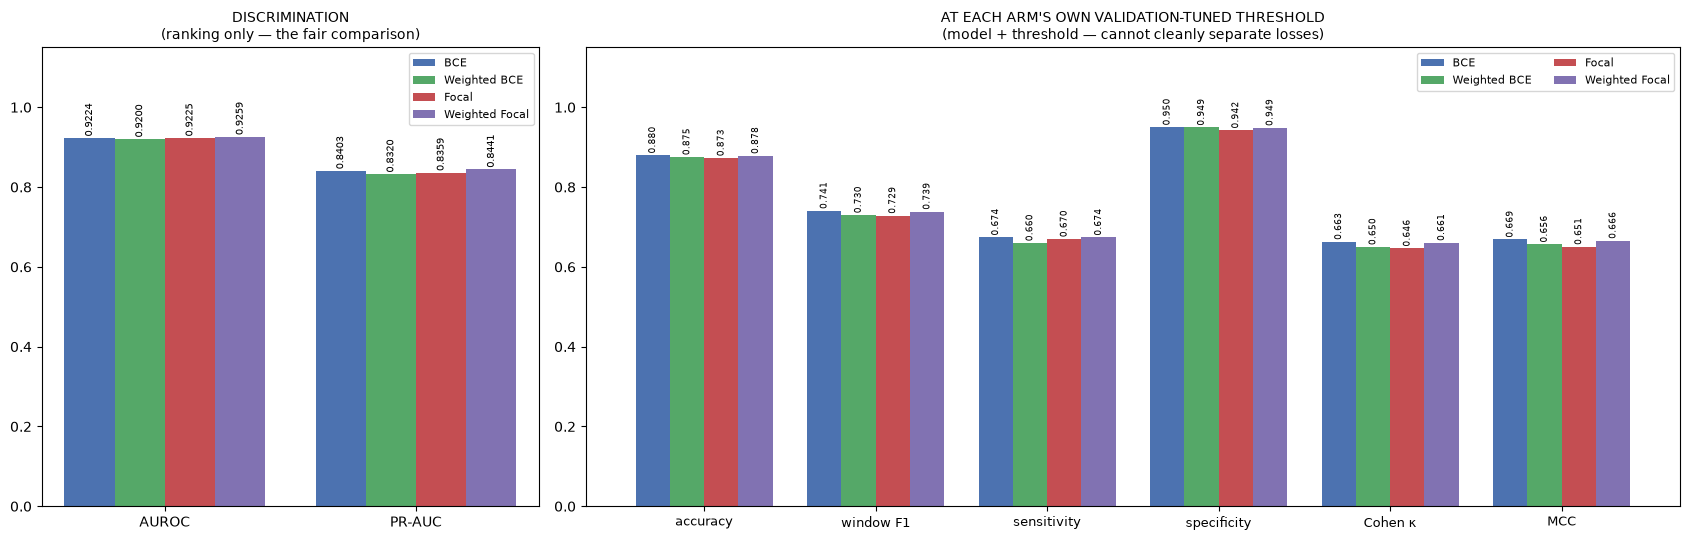

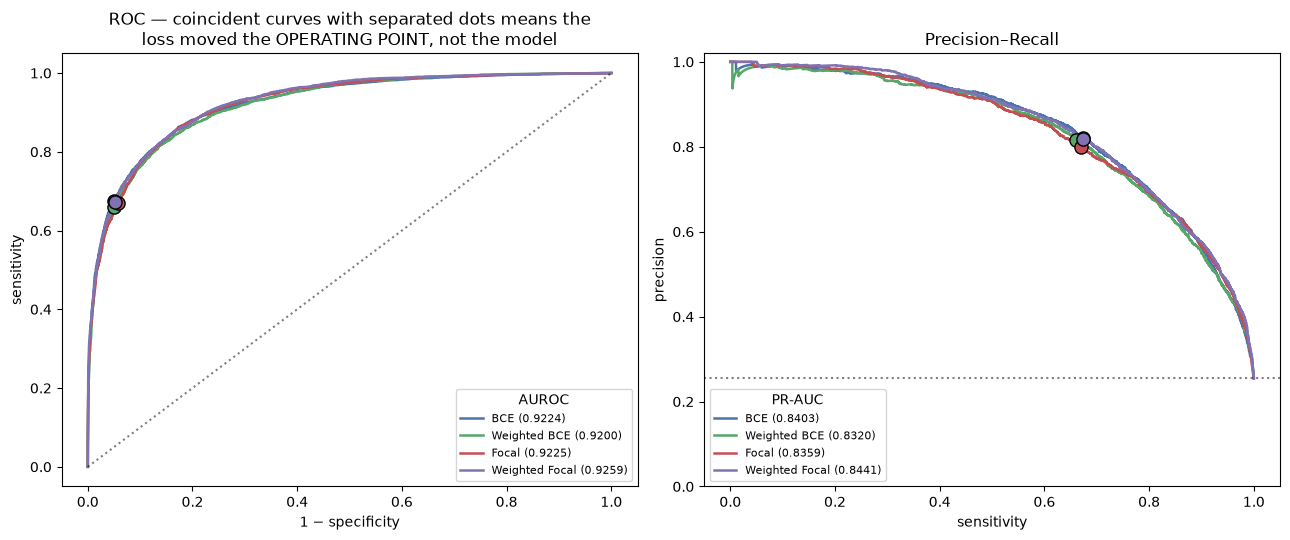

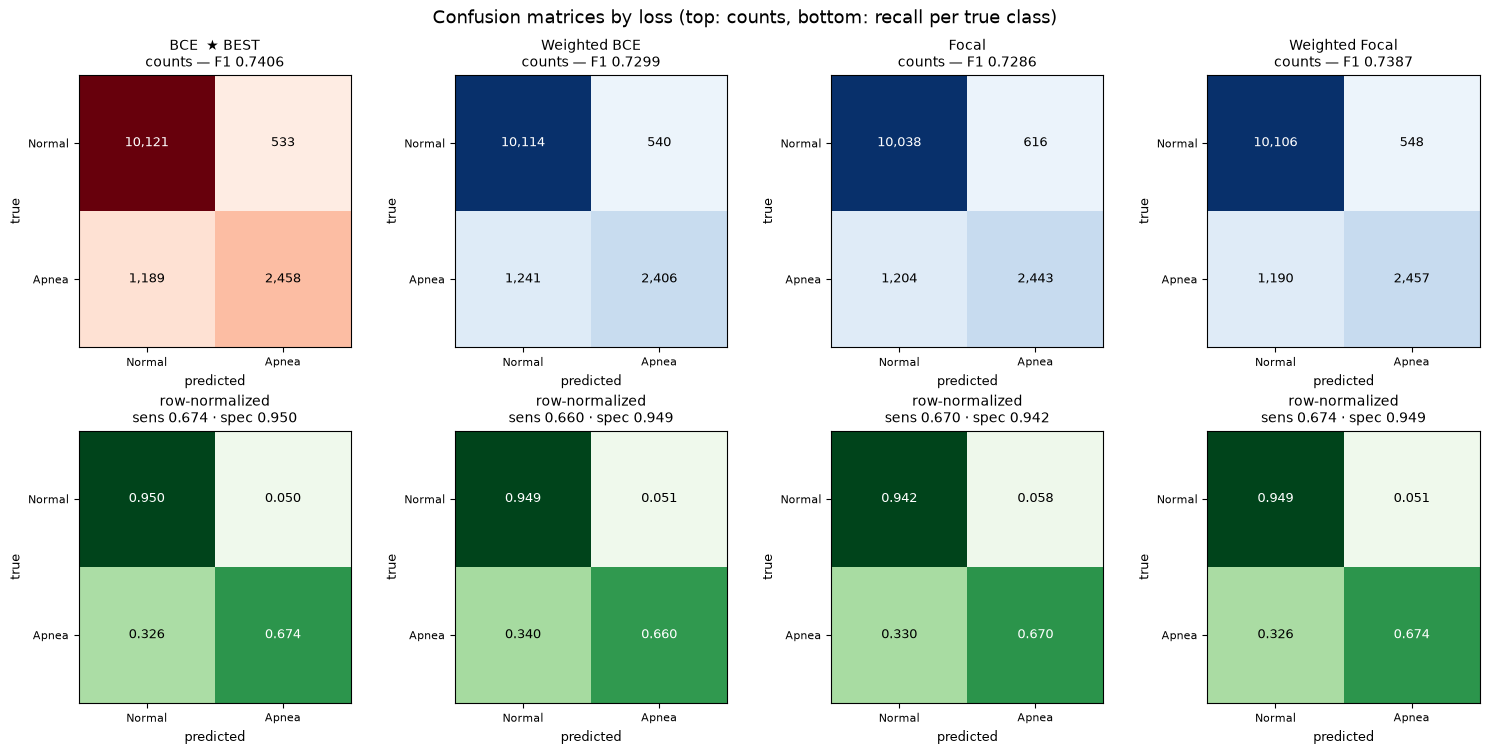

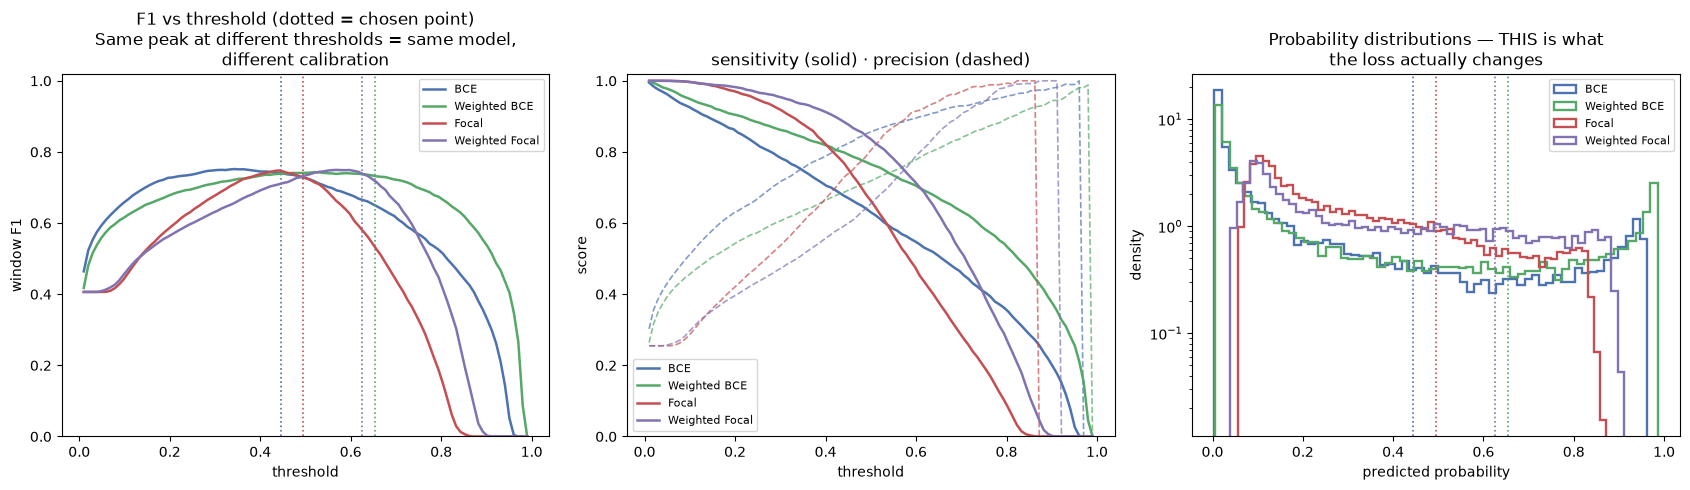

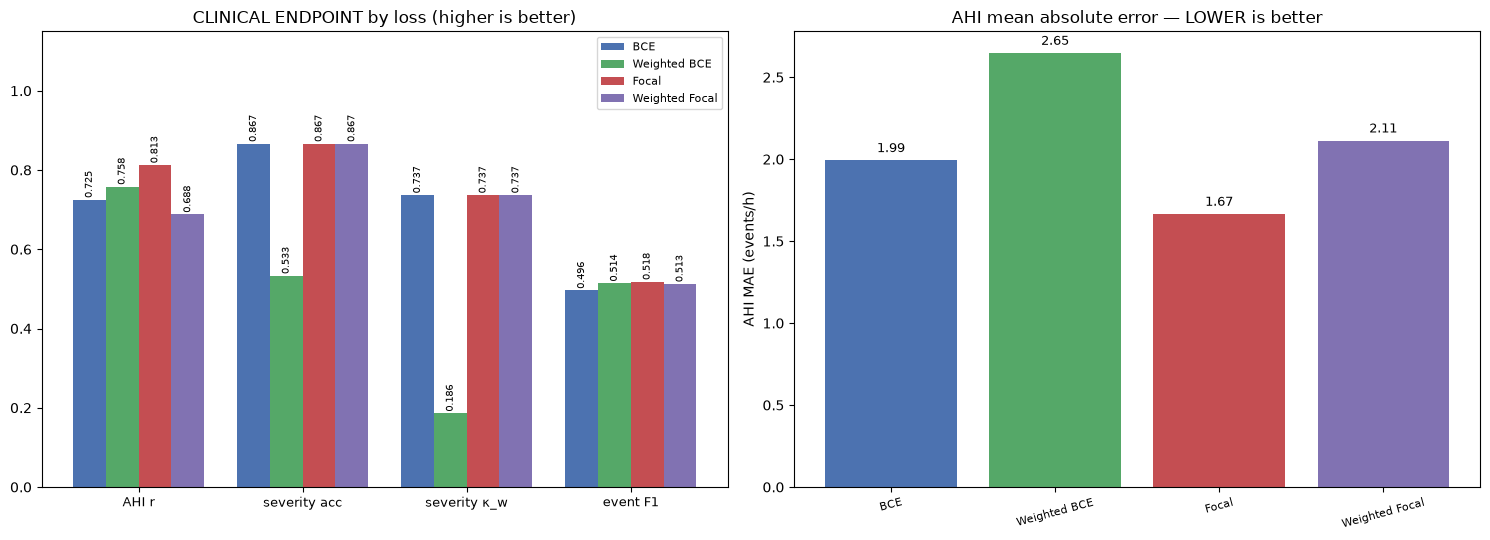

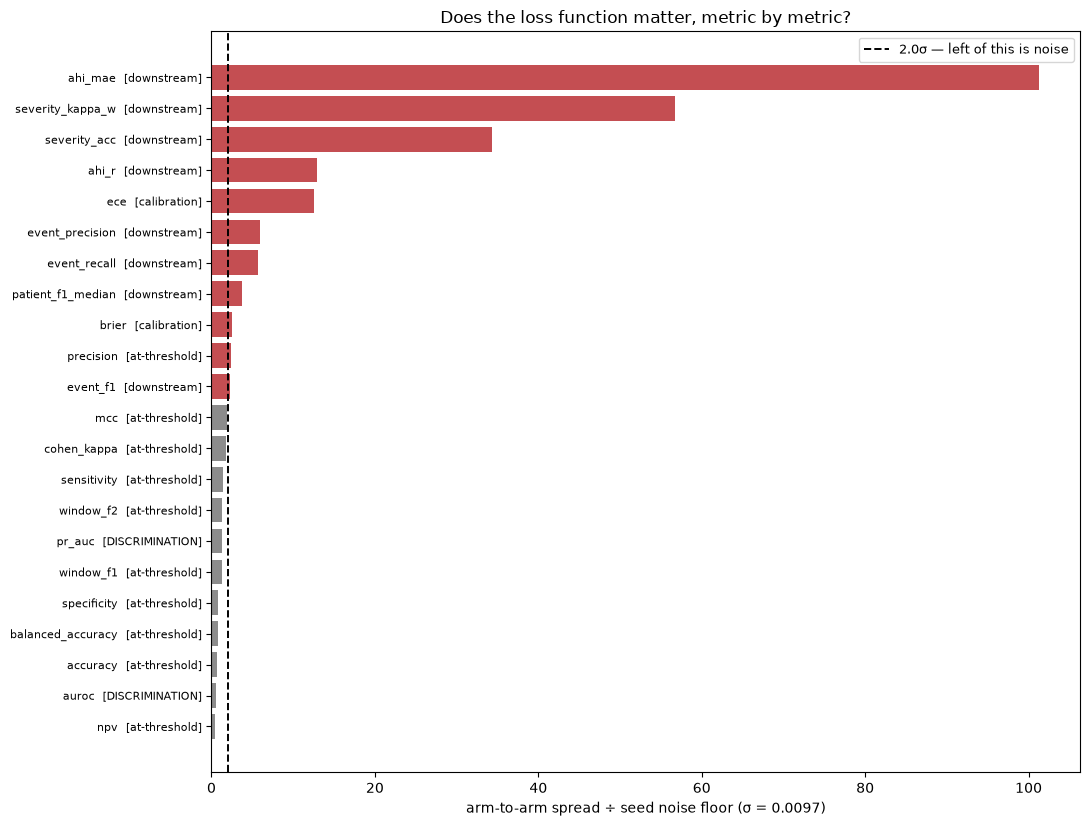

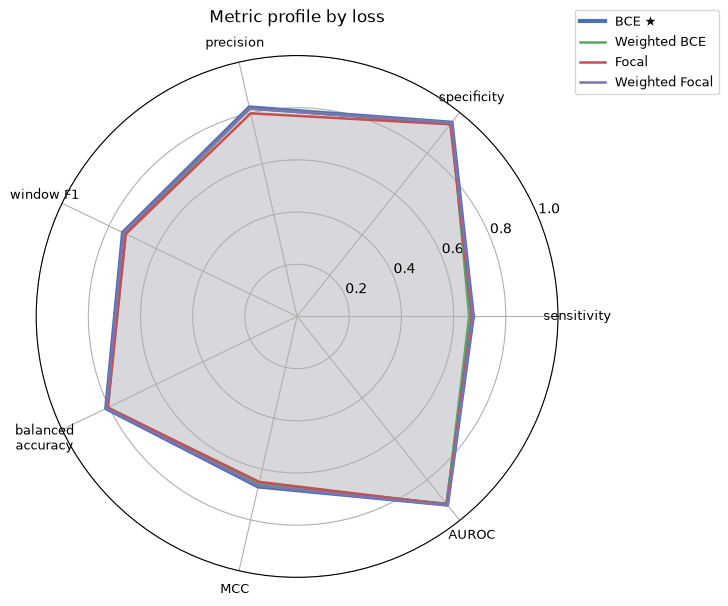

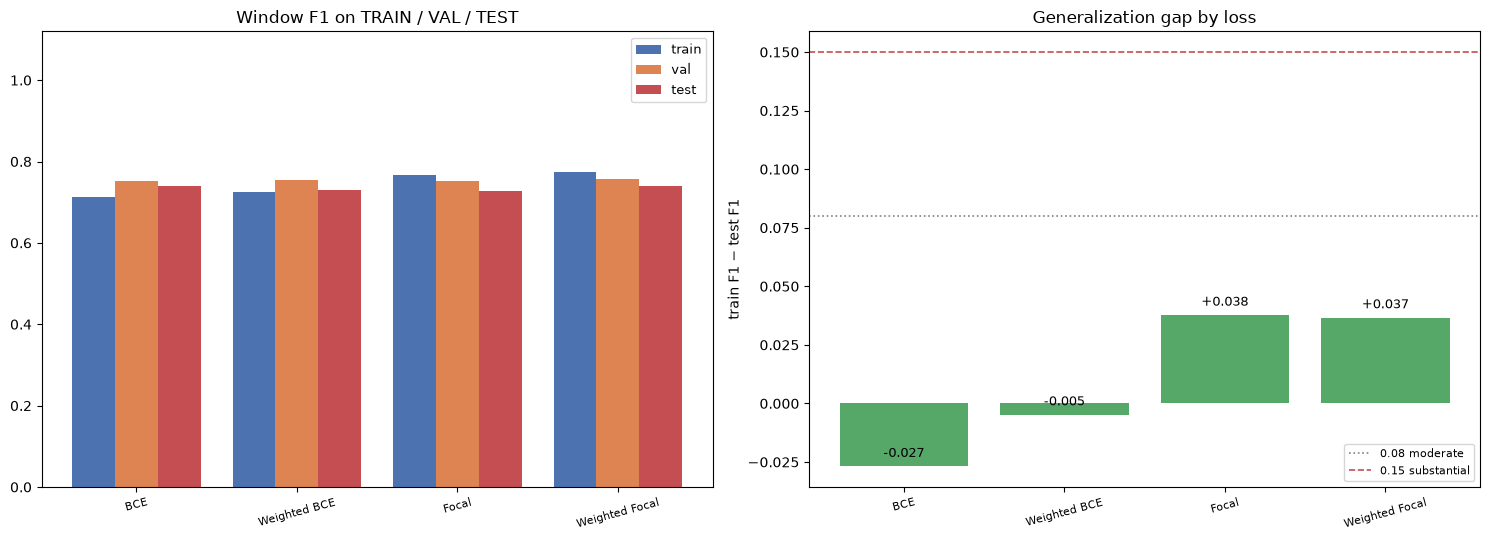

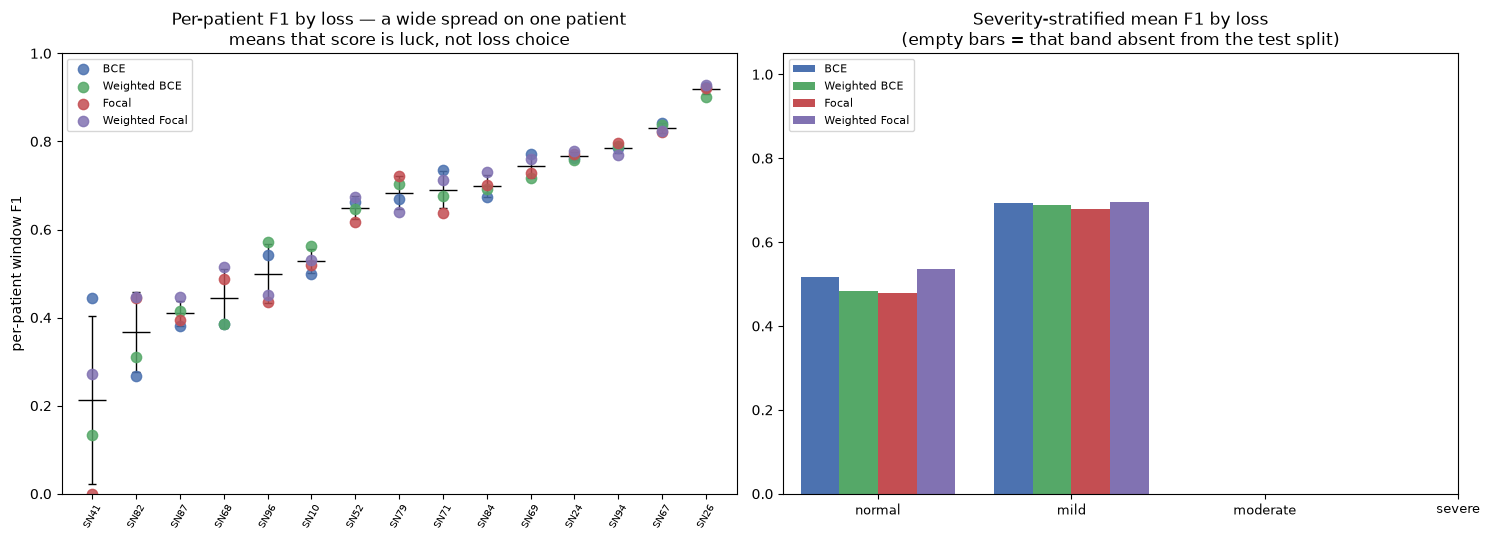

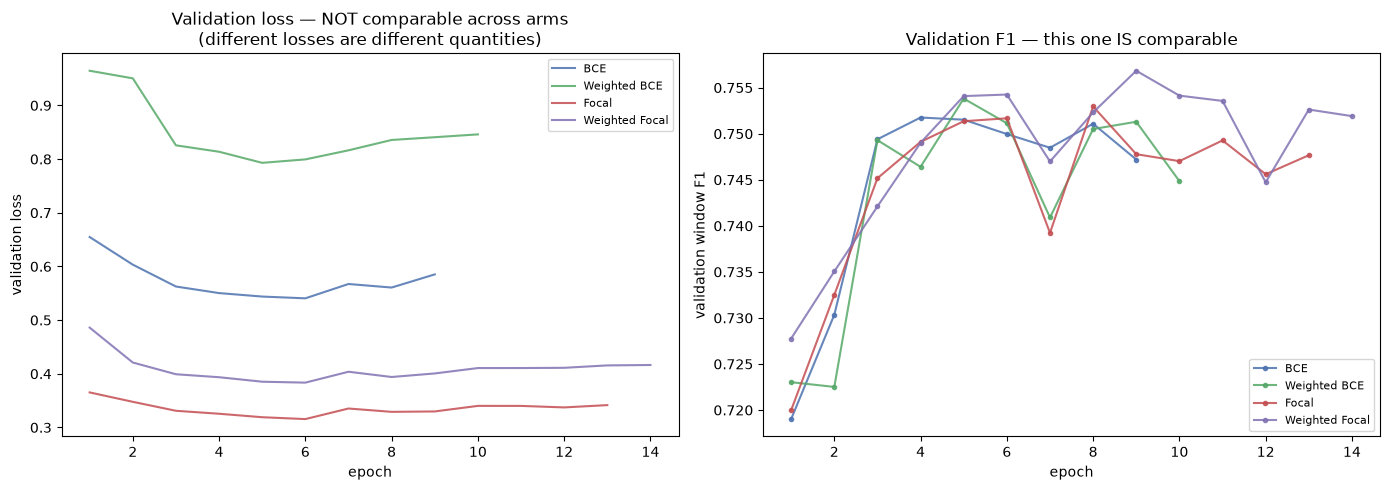


  BEST MODEL — BCE
  threshold 0.4448 (tuned on validation)

                pred Normal   pred Apnea    recall
  true_Normal       10,121          533     0.9500
  true_Apnea         1,189        2,458     0.6740
  precision         0.8949       0.8218

              precision    recall  f1-score   support

      Normal     0.8949    0.9500    0.9216     10654
       Apnea     0.8218    0.6740    0.7406      3647

    accuracy                         0.8796     14301
   macro avg     0.8583    0.8120    0.8311     14301
weighted avg     0.8762    0.8796    0.8754     14301

  artefacts -> /home/nishant/apneastudyproject/output2/loss_ablation/BEST_MODEL

  TABLE_all_losses.csv  <- the table for the paper
  split_used.csv        <- the exact split, for the record
  BEST_MODEL/           <- BCE artefacts
  26 entries -> /home/nishant/apneastudyproject/output2/loss_ablation


In [28]:
# =========================================================================
#  7.  ENTRY POINT  — no argparse: in Jupyter sys.argv holds kernel flags
# =========================================================================
def _find_namespace():
    """The main cell leaves apnea_notebook's functions in the notebook
    globals. Grab a live view of those so LOSS_TYPE writes THROUGH — a copy
    would accept the assignment silently and every arm would train the same."""
    import sys

    class _Env:
        def __init__(self, d): object.__setattr__(self, "_d", d)
        def __getattr__(self, k):
            try:
                return object.__getattribute__(self, "_d")[k]
            except KeyError:
                raise AttributeError(k) from None
        def __setattr__(self, k, v):
            object.__getattribute__(self, "_d")[k] = v

    SENTINEL = "run_split"
    g = globals()
    if SENTINEL in g:
        return _Env(g)
    try:
        from IPython import get_ipython
        ip = get_ipython()
        if ip is not None and SENTINEL in ip.user_ns:
            return _Env(ip.user_ns)
    except Exception:
        pass
    for name in ("apnea_notebook", "apnea_local", "apnea_best", "__main__"):
        mod = sys.modules.get(name)
        if mod is not None and hasattr(mod, SENTINEL):
            return mod
    return None


M = _find_namespace()

if M is None:
    print("=" * 78)
    print("  The apnea pipeline is not loaded in this notebook.")
    print("=" * 78)
    print("  Run the apnea_notebook.py cell FIRST — this cell needs its")
    print("  functions (run_split, window_metrics, ahi_metrics, ...).")
    print("  Then re-run this cell.")
    results_ablation = None
elif not getattr(M, "TORCH_AVAILABLE", False):
    print("  torch is not available — cannot train. Install it, restart the")
    print("  kernel, re-run the main cell, then this one.")
    results_ablation = None
else:
    results_ablation = run_ablation()